# Milestone 2: Data Wrangling and Project Redefinition

**Canvas project group 100:** Allen Garcia, Amy Chen, Clara Cheng, Luke Tan, Sunny Li

**Authors:** 
Amy Chen (Sections 1 – 7: EIA-930, all U.S. regions) · Clara Cheng (Section 8-11: ERCOT's own fuel mix data for Texas)

**What this notebook does.** 
It gets EIA's hourly grid data for every U.S. balancing authority, adds the balancing authorities up into EIA's **13 regions**, cleans the result, and does a preliminary EDA. The regions are CAL (California), CAR (Carolinas), CENT (Central), FLA (Florida), MIDA (Mid-Atlantic), MIDW (Midwest), NE (New England), NW (Northwest), NY (New York), SE (Southeast), SW (Southwest), TEN (Tennessee) and TEX (Texas).
It then adds a second, more detailed source for Texas, taken directly from ERCOT, the Texas grid operator (its own fuel mix report), cleans it the same way, and checks it against EIA's Texas numbers:

**Sections in this notebook:**
1. Where the data comes from, how we got it, and its size
2. What one row and each column represent, including **which balancing authorities are in each region, and how that changed over time**
3. Cleaning, and the cleaned region table (saved as CSV)
4. Quick data-quality checks
5. EDA over the **full timeline** (2019 – Oct 2026): basic plots first, then polished charts. Each chart is drawn **for each region**, then **for all regions together**
6. EDA on the **focus period** the team chose: **2023 – Oct 2026** (post-COVID)
7. Summary of findings
8. **ERCOT fuel mix data for Texas:** getting, understanding and cleaning it, and checking it against EIA's Texas region
9. **Final review of checklist** for both datasets: missing data, unusual values, class imbalance, scale of the features, information leakage

PJM is the `MIDA` (Mid-Atlantic) region and ERCOT is the `TEX` (Texas) region: each is the only balancing authority in its region.

In [5]:
import os, sys
import zipfile
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, ".")
import eia930 as E      # download / scan / clean / region table / carbon intensity
import style as S       # presentation style (same as the Allston energy & ICT project)
pd.set_option("display.width", 220, "display.max_columns", 40)

START, END = "2019-01-01", "2026-10-31"    # full window, local days, inclusive
FOCUS_START = "2023-01-01"                 # team decision: focus on the post-COVID period
RAW, OUT, FIG = "data/raw", "data", "figures"
os.makedirs(FIG, exist_ok=True)

RN = E.REGION_NAME                         # region code -> name
REGIONS = list(RN)                         # fixed order for every chart
PAL13 = dict(zip(REGIONS, sns.color_palette("tab20", 13)))   # one color per region in the basic plots


def grid13(sharex=True, sharey=False, figsize=(16, 13)):
    # 4 x 4 panels, one per region (3 left empty). Returns fig and {region: ax}
    fig, axes = plt.subplots(4, 4, figsize=figsize, sharex=sharex, sharey=sharey)
    axes = axes.ravel()
    for ax in axes[len(REGIONS):]:
        ax.axis("off")
    for ax in axes[:len(REGIONS)]:
        ax.xaxis.set_tick_params(labelbottom=True)
    return fig, dict(zip(REGIONS, axes))

## 1. Where the data comes from and how we got it

| | |
|---|---|
| **Source** | U.S. Energy Information Administration (EIA), *Form EIA-930 Hourly Electric Grid Monitor*: https://www.eia.gov/electricity/gridmonitor/ |
| **Files** | Public six-month bulk CSVs, no API key: `EIA930_BALANCE_{year}_{Jan_Jun or Jul_Dec}.csv` and `EIA930_INTERCHANGE_{...}.csv` from https://www.eia.gov/electricity/gridmonitor/sixMonthFiles/ |
| **BALANCE** | For every balancing authority (BA) and hour: demand, day-ahead demand forecast, net generation, total interchange, and net generation **by fuel** |
| **INTERCHANGE** | For every BA and hour: the flow to/from **each** directly connected neighbouring BA |
| **Downloaded** | 2026-11-11 |

The cell below downloads the EIA that are not on disk yet. ERCOT files are downloaded in Section 8.

In [6]:
bal_files = E.download(f"{RAW}/eia930", "BALANCE")
ix_files = E.download(f"{RAW}/eia930_interchange", "INTERCHANGE")

sizes = pd.DataFrame([{"kind": "BALANCE" if "BALANCE" in f else "INTERCHANGE", "file": os.path.basename(f),
                       "MB": os.path.getsize(f) / 1e6} for f in bal_files + ix_files])
print(sizes.groupby("kind").agg(files=("file", "count"), total_MB=("MB", "sum")).round(0))
print(f"\nTotal raw data: {sizes.MB.sum() / 1e3:.2f} GB")

downloaded EIA930_BALANCE_2019_Jan_Jun.csv
downloaded EIA930_BALANCE_2019_Jul_Dec.csv
downloaded EIA930_BALANCE_2020_Jan_Jun.csv
downloaded EIA930_BALANCE_2020_Jul_Dec.csv
downloaded EIA930_BALANCE_2021_Jan_Jun.csv
downloaded EIA930_BALANCE_2021_Jul_Dec.csv
downloaded EIA930_BALANCE_2022_Jan_Jun.csv
downloaded EIA930_BALANCE_2022_Jul_Dec.csv
downloaded EIA930_BALANCE_2023_Jan_Jun.csv
downloaded EIA930_BALANCE_2023_Jul_Dec.csv
downloaded EIA930_BALANCE_2024_Jan_Jun.csv
downloaded EIA930_BALANCE_2024_Jul_Dec.csv
downloaded EIA930_BALANCE_2025_Jan_Jun.csv
downloaded EIA930_BALANCE_2025_Jul_Dec.csv
downloaded EIA930_BALANCE_2026_Jan_Jun.csv
downloaded EIA930_BALANCE_2026_Jul_Dec.csv
downloaded EIA930_INTERCHANGE_2019_Jan_Jun.csv
downloaded EIA930_INTERCHANGE_2019_Jul_Dec.csv
downloaded EIA930_INTERCHANGE_2020_Jan_Jun.csv
downloaded EIA930_INTERCHANGE_2020_Jul_Dec.csv
downloaded EIA930_INTERCHANGE_2021_Jan_Jun.csv
downloaded EIA930_INTERCHANGE_2021_Jul_Dec.csv
downloaded EIA930_INTERCHANGE_

## 2. What one row and each column represent

### 2.1 BALANCE files, read exactly as published

**One row = one balancing authority × one hour.** We read **every column** of every file and let pandas infer the types, with no columns chosen or renamed first. The scan below also records which BAs and regions appear, and keeps a tidy copy for cleaning later. It takes about a minute.

In [7]:
B = E.scan_balance(bal_files)
tidy = B["tidy"]
print(f"rows (BA x hour):     {len(tidy):,}")
print(f"balancing authorities: {tidy.ba.nunique()}   regions: {tidy.region.nunique()}")
print(f"columns across all files: {len(B['profile'])}")

ncols = pd.Series({os.path.basename(f)[15:-4]: len(pd.read_csv(f, nrows=0).columns) for f in bal_files}, name="columns")
ncols.to_frame().T

rows (BA x hour):     4,304,351
balancing authorities: 69   regions: 13
columns across all files: 74


,2019_Jan_Jun,2019_Jul_Dec,2020_Jan_Jun,2020_Jul_Dec,2021_Jan_Jun,2021_Jul_Dec,2022_Jan_Jun,2022_Jul_Dec,2023_Jan_Jun,2023_Jul_Dec,2024_Jan_Jun,2024_Jul_Dec,2025_Jan_Jun,2025_Jul_Dec,2026_Jan_Jun,2026_Jul_Dec
columns,44,44,44,44,44,44,44,44,44,44,44,65,65,65,65,65


The files have **44 columns until June 2024 and 65 from July 2024**. In July 2024 EIA split solar, wind and hydro into sub-categories and added storage and geothermal. Across all files that is 74 different columns.

Every column, with the type pandas inferred, how many files have it, how full it is, and an example value:

In [8]:
with pd.option_context("display.max_rows", 100, "display.max_colwidth", 50):
    display(B["profile"])

,dtype,files_with_column,% filled (where present),example
column,,,,
Balancing Authority,str,16,100.0,AEC
Data Date,str,16,100.0,01/01/2019
Hour Number,int64,16,100.0,1
Local Time at End of Hour,str,16,100.0,01/01/2019 1:00:00 AM
UTC Time at End of Hour,str,16,100.0,01/01/2019 7:00:00 AM
Demand Forecast (MW),float64,16,85.2,630.0
Demand (MW),float64,16,85.2,361.0
Net Generation (MW),float64,16,99.4,414.0
Total Interchange (MW),float64,16,99.4,53.0


**How to read the columns.** They come in a few families:

| Family | Columns | What they mean |
|---|---|---|
| **Identifiers / time** | `Balancing Authority`, `Region`, `Data Date`, `Hour Number`, `Local Time at End of Hour`, `UTC Time at End of Hour` | Which grid, which region, and which hour. `Hour Number` is 1–24 within the local day (23 or 25 on daylight-saving days). Times mark the **end** of the hour |
| **Totals** | `Demand Forecast (MW)`, `Demand (MW)`, `Net Generation (MW)`, `Total Interchange (MW)`, `Sum(Valid DIBAs) (MW)` | Day-ahead demand forecast, actual demand, total generation inside the BA, net flow out (+ = export), and the sum of flows reported per neighbour |
| **Generation by fuel** | `Net Generation (MW) from <fuel>` | MW from coal, gas, nuclear, oil, hydro, solar, wind, other, and (from Jul 2024) storage and geothermal |
| **`(Imputed)` versions** | e.g. `Demand (MW) (Imputed)` | Filled **only** in hours where EIA had to impute the value. Useful as a flag |
| **`(Adjusted)` versions** | e.g. `Demand (MW) (Adjusted)` | EIA's cleaned series: the reported value, or EIA's estimate where the reported one was missing or bad. **This is what we analyse** |

Things to notice:
- Every measurement column is read as a number (`float64`), and only the identifier and time columns are text (`object`). No types need to be forced.
- The `(Imputed)` columns are mostly empty, as they should be.
- Two of EIA's column names have typos (`Solar witho Integrated…`, and a double space in `Pumped Storage  (Adjusted)`). That matters when selecting columns by name.

### 2.2 Regions and balancing authorities

A **balancing authority (BA)** runs one grid area: it keeps supply and demand in balance there. Examples are PJM, ERCOT, CAISO, or a single utility like Duke Energy Carolinas. EIA groups BAs into **13 regions** (the `Region` column). Some regions are one big BA; others are many small utilities. Every BA stays in the same region in every year.

In [9]:
ba_info = B["ba_info"]
latest = B["ba_year"][B["ba_year"].year == 2026]
regions = (latest.groupby("Region")["Balancing Authority"]
           .agg(n_ba="nunique", balancing_authorities=lambda s: ", ".join(sorted(set(s))))
           .reindex(REGIONS))
regions.insert(0, "name", regions.index.map(RN))
print("BAs that ever change region:", int((B["ba_year"].groupby("Balancing Authority").Region.nunique() > 1).sum()))
with pd.option_context("display.max_colwidth", 200):
    display(regions)

BAs that ever change region: 0


,name,n_ba,balancing_authorities
Region,,,
CAL,California,5,"BANC, CISO, IID, LDWP, TIDC"
CAR,Carolinas,6,"CPLE, CPLW, DUK, SC, SCEG, YAD"
CENT,Central,2,"SPA, SWPP"
FLA,Florida,9,"FMPP, FPC, FPL, GVL, HST, JEA, SEC, TAL, TEC"
MIDA,Mid-Atlantic,1,PJM
MIDW,Midwest,4,"AECI, LGEE, MISO, SIKE"
NE,New England,1,ISNE
NW,Northwest,22,"AVA, AVRN, BHBA, BPAT, CHPD, DOPD, GCPD, GRID, GWA, IPCO, NEVP, NWMT, PACE, PACW, PGE, PSCO, PSEI, SCL, SWPW, TPWR, WACM, WAUW"
NY,New York,1,NYIS


In [10]:
# number of balancing authorities in each region, by year
ba_per_region_year = (B["ba_year"].groupby(["Region", "year"])["Balancing Authority"].nunique()
                      .unstack().reindex(REGIONS))
ba_per_region_year.loc["TOTAL"] = B["ba_year"].groupby("year")["Balancing Authority"].nunique()
ba_per_region_year

year,2019,2020,2021,2022,2023,2024,2025,2026
Region,,,,,,,,
CAL,5,5,5,5,5,5,5,5
CAR,6,6,6,6,6,6,6,6
CENT,2,2,2,2,2,2,2,2
FLA,10,10,9,9,9,9,9,9
MIDA,1,1,1,1,1,1,1,1
MIDW,4,5,4,4,3,3,4,4
NE,1,1,1,1,1,1,1,1
NW,21,21,21,21,21,21,21,22
NY,1,1,1,1,1,1,1,1


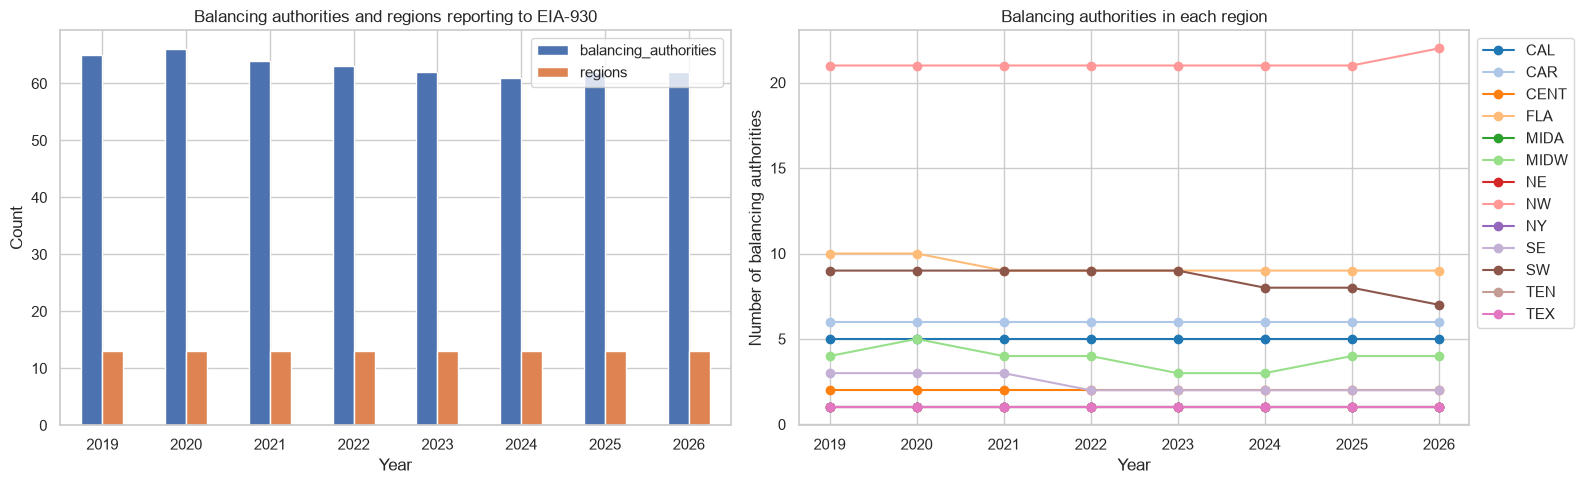

In [11]:
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
# left: total BAs and regions per year
per_year = B["ba_year"].groupby("year").agg(balancing_authorities=("Balancing Authority", "nunique"),
                                            regions=("Region", "nunique"))
per_year.plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_xlabel("Year"); axes[0].set_ylabel("Count")
axes[0].set_title("Balancing authorities and regions reporting to EIA-930")
# right: BAs per region, by year
ba_per_region_year.drop("TOTAL").T.plot(ax=axes[1], marker="o", color=[PAL13[r] for r in REGIONS])
axes[1].set_xlabel("Year"); axes[1].set_ylabel("Number of balancing authorities")
axes[1].set_title("Balancing authorities in each region")
axes[1].legend(bbox_to_anchor=(1, 1), ncol=1)
plt.tight_layout()
plt.show()

In [12]:
# which BAs started or stopped reporting during 2019 - Oct 2026?
came_went = ba_info[(ba_info.first_hour > "2019-01-02") | (ba_info.last_hour < "2026-10-01")].copy()
came_went["first_hour"] = came_went.first_hour.dt.date
came_went["last_hour"] = came_went.last_hour.dt.date
came_went.sort_values("region")

,region,first_hour,last_hour
ba,,,
NSB,FLA,2019-01-01,2020-01-08
EEI,MIDW,2019-01-01,2020-02-29
GLHB,MIDW,2020-02-29,2022-09-01
SIKE,MIDW,2025-06-01,2026-11-13
BHBA,NW,2026-04-01,2026-11-14
SWPW,NW,2026-04-01,2026-11-14
WACM,NW,2019-01-01,2026-04-01
WAUW,NW,2019-01-01,2026-04-01
WWA,NW,2019-01-01,2025-10-01


**What we see**

- **13 regions in every year.** The number of balancing authorities drifts from 65 (2019) to 62 (2026); 69 different BAs report at some point. No BA ever moves between regions.
- **Five regions are a single BA:** Mid-Atlantic (PJM), New England (ISO-NE), New York (NYISO), Tennessee (TVA) and Texas (ERCOT). The others group several BAs: the Northwest has 21–22, Florida 9–10, and the Southwest 7–9.
- **Changes over time are mostly small utilities.**
  - Retired: NSB (Florida) in Jan 2020, EEI (Midwest) in Feb 2020, AEC (Southeast) in Sep 2021, GRIF (Southwest) in Nov 2023, HGMA (Southwest) in Jun 2025, WWA (Northwest) in Oct 2025.
  - Came and went: GLHB (Midwest) reported only from Feb 2020 to Sep 2022.
  - New: SIKE (Midwest) from Jun 2025.
  - Biggest change: in the Northwest, WACM and WAUW stop on 1 Apr 2026, the same day BHBA and SWPW start.
- **Why it matters:** a region's total is the sum of whichever BAs report that hour (`n_ba` in the cleaned table). Because the BAs that come and go are small, region totals stay comparable over time.

### 2.3 Summary statistics, and impossible raw values

Summary statistics of the tidy BA-level table (the `(Adjusted)` series, all BAs pooled):

In [13]:
tidy.describe().T.round(0)

,count,mean,min,25%,50%,75%,max,std
utc_end,4304351,2022-11-16 11:39:02.248018,2019-01-01 06:00:00,2020-11-26 01:00:00,2022-11-04 08:00:00,2024-11-02 11:00:00,2026-11-14 08:00:00,NaN
demand,3673385.0,8845.703125,0.0,763.0,2389.0,6250.0,224345.0,17885.818359
demand_fcst,3666486.0,8791.344727,-992136.0,782.0,2304.0,6116.0,466542.0,17982.646484
netgen,4287628.0,7489.42627,-398.0,501.0,1505.0,5352.0,164403.0,16921.248047
interchange,4277570.0,-40.327023,-17149.0,-486.0,-5.0,372.0,14985.0,1724.513916
coal,2452168.0,2525.922119,-73.0,136.0,637.0,2224.0,44915.0,5199.72168
gas,3499425.0,3578.800781,-10.0,316.0,793.0,2522.0,75926.0,7571.582031
nuclear,1230411.0,5046.944336,-10.0,1142.0,3339.0,5882.0,46004.0,6987.30957
oil,1443242.0,44.398663,-10.0,0.0,0.0,0.0,11841.0,208.616898
hydro,3130058.0,658.099792,-5798.0,22.0,189.0,727.0,14919.0,1342.702148


In [14]:
# raw values above 1,000,000 MW (impossible: the largest U.S. grid peaks around 160,000 MW)
bad = B["bad_raw"]
print(f"{len(bad)} impossible raw values in {bad.ba.nunique()} BAs")
display(bad.groupby(["ba", "column"]).size().rename("count").reset_index().sort_values("count", ascending=False).head(15))
bad.sort_values("value", ascending=False).head(5)

342 impossible raw values in 10 BAs


,ba,column,count
4,BANC,Demand (MW),92
8,BANC,Sum(Valid DIBAs) (MW),88
9,BANC,Total Interchange (MW),87
5,BANC,Net Generation (MW),12
7,BANC,Net Generation (MW) from Natural Gas,12
24,SWPP,Sum(Valid DIBAs) (MW),5
25,TVA,Demand (MW),3
14,PJM,Net Generation (MW),3
13,PJM,Demand (MW),3
11,LGEE,Demand (MW),3


,ba,column,utc_end,value
333,BANC,Net Generation (MW) from Hydropower Excluding ...,2026-01-22 20:00:00,2.576981e+09
311,PJM,Net Generation (MW),2021-10-19 04:00:00,2.147480e+09
307,PJM,Demand (MW),2021-10-19 04:00:00,2.147480e+09
306,PJM,Demand (MW),2021-10-19 03:00:00,1.527760e+09
310,PJM,Net Generation (MW),2021-10-19 03:00:00,1.527330e+09


These are broken records in the **raw** columns. Some are 2³¹ − 1 = 2,147,483,647, the largest 32-bit integer. We only use the `(Adjusted)` columns, where EIA has replaced them, so they don't enter the analysis. They're one more reason to use `(Adjusted)`.

### 2.4 INTERCHANGE files

**One row = one BA × one neighbouring BA × one hour.** `Interchange (MW)` > 0 means power flows **out** to that neighbour. The `Region` and `DIBA_Region` columns give both sides' regions. Neighbours include Canada (`CAN`) and Mexico (`MEX`).

In [15]:
ix_profile, flows = E.scan_interchange(ix_files)
display(ix_profile)
print(f"region-to-region flow table: {len(flows):,} rows (region x neighbouring region x hour)")
flows.head()

,dtype,files_with_column,% filled (where present),example
column,,,,
Balancing Authority,str,16,100.0,AEC
Data Date,str,16,100.0,01/01/2019
Hour Number,int64,16,100.0,1
Directly Interconnected Balancing Authority,str,16,100.0,MISO
Interchange (MW),float64,16,98.8,28.0
Local Time at End of Hour,str,16,100.0,01/01/2019 1:00:00 AM
UTC Time at End of Hour,str,16,100.0,01/01/2019 7:00:00 AM
Region,str,16,100.0,SE
DIBA_Region,str,16,100.0,MIDW


region-to-region flow table: 2,963,909 rows (region x neighbouring region x hour)


,region,to_region,utc_end,mw
0,CAL,MEX,2019-01-01 09:00:00,-35.0
1,CAL,MEX,2019-01-01 10:00:00,-45.0
2,CAL,MEX,2019-01-01 11:00:00,-78.0
3,CAL,MEX,2019-01-01 12:00:00,-107.0
4,CAL,MEX,2019-01-01 13:00:00,-130.0


## 3. Cleaning, and the cleaned region table

`E.build_regions` does the following (code in `eia930.py`):

1. **Harmonize the fuels.** The `(Adjusted)` fuel columns are mapped onto 8 fuels that mean the same in every year: coal, gas, nuclear, oil, hydro, solar, wind, other. After July 2024, hydro, solar and wind are the sums of their new sub-categories. Geothermal and battery storage are added to **other**, where EIA counted them before July 2024. Battery charging (negative) counts as 0.
2. **Clean each BA.** One-hour spikes and impossible values (e.g. PJM nuclear at 46 GW, above its ~33 GW capacity) are set to missing. Gaps of ≤ 3 h are filled by time interpolation.
3. **Add BAs up into regions.** Demand, forecast, generation, interchange and each fuel are summed over the region's BAs for each hour. `n_ba` records how many BAs reported that hour.
4. **Local clock per region.** UTC is converted to one time zone per region (table below). `hour` is the local hour *beginning* (0 = midnight–1 am).
5. **Carbon intensity** (kg CO₂/MWh, production-based) = Σ(generation by fuel × emission factor) / Σ generation. The emission factor is EIA's CO₂ coefficient × that year's national heat rate: coal ≈ 1,030, gas ≈ 410, oil ≈ 830 kg/MWh, everything else 0. If the fuels add up to less than 85% of reported net generation, part of the mix is missing, so carbon intensity is left blank.

In [16]:
pd.DataFrame({"name": RN, "time zone used": E.REGION_TZ})

,name,time zone used
CAL,California,America/Los_Angeles
CAR,Carolinas,America/New_York
CENT,Central,America/Chicago
FLA,Florida,America/New_York
MIDA,Mid-Atlantic,America/New_York
MIDW,Midwest,America/Chicago
NE,New England,America/New_York
NW,Northwest,America/Los_Angeles
NY,New York,America/New_York
SE,Southeast,America/Chicago


In [17]:
R, cleaned = E.build_regions(tidy, START, END)
R["region_name"] = R.region.map(RN)
print("cleaned region table:", R.shape[0], "rows x", R.shape[1], "columns")
print("rows per region:", R.groupby("region").size().iloc[0], "(one per hour, Jan 2019 – Oct 2026)")
R.head()

cleaned region table: 892620 rows x 25 columns
rows per region: 68663 (one per hour, Jan 2019 – Oct 2026)


,region,utc_end,date,hour,year,month,dow,season,n_ba,demand,demand_fcst,netgen,interchange,coal,gas,nuclear,oil,hydro,solar,wind,other,co2_t,ci,mix_ratio,region_name
0,CAL,2019-01-01 09:00:00,2019-01-01,0,2019,1,1,Winter,5,26876.0,26940.0,18423.0,-6631.0,1778.0,8627.0,2273.0,89.0,2295.0,-22.0,2604.0,779.0,5400.788574,292.805023,1.001194,California
1,CAL,2019-01-01 10:00:00,2019-01-01,1,2019,1,1,Winter,5,25989.0,25922.0,17616.0,-6439.0,1765.0,8259.0,2275.0,89.0,2002.0,-22.0,2514.0,731.0,5237.209961,296.978180,1.001079,California
2,CAL,2019-01-01 11:00:00,2019-01-01,2,2019,1,1,Winter,5,25295.0,25159.0,17241.0,-6254.0,1743.0,8168.0,2274.0,88.0,1724.0,-25.0,2539.0,724.0,5176.903320,299.936462,1.001102,California
3,CAL,2019-01-01 12:00:00,2019-01-01,3,2019,1,1,Winter,5,24884.0,24700.0,17153.0,-6225.0,1727.0,8134.0,2273.0,90.0,1757.0,-25.0,2464.0,727.0,5148.463379,299.817352,1.001108,California
4,CAL,2019-01-01 13:00:00,2019-01-01,4,2019,1,1,Winter,5,24922.0,24699.0,17557.0,-6177.0,1747.0,8473.0,2275.0,91.0,1962.0,-26.0,2280.0,751.0,5308.109375,301.957428,1.001253,California


In [18]:
# one row = one region in one hour. Example: Mid-Atlantic (PJM), 15 Jul 2025, 2-3 pm local
R[(R.region == "MIDA") & (R.date == "2025-07-15") & (R.hour == 14)].T

,331953
region,MIDA
utc_end,2025-07-15 19:00:00
date,2025-07-15 00:00:00
hour,14
year,2025
month,7
dow,1
season,Summer
n_ba,1
demand,137398.0


| Column | Units | Meaning |
|---|---|---|
| `region`, `region_name` | | EIA region code and name |
| `utc_end` | UTC | **End** of the hour. |
| `date`, `hour` | local | Local day and hour *beginning* (0–23), on the region's clock |
| `year`, `month`, `dow`, `season` | | Calendar fields from `date` (`dow` 0 = Monday) |
| `n_ba` | count | Number of balancing authorities summed into this hour |
| `demand` | MW | Actual demand |
| `demand_fcst` | MW | Day-ahead demand forecast (known before the day starts) |
| `netgen` | MW | Total generation inside the region |
| `interchange` | MW | Net flow out of the region's BAs: > 0 = net **exports** |
| `coal` … `other` | MW | Generation by fuel (8 fuels) |
| `co2_t` | t CO₂ | CO₂ from the region's own generation that hour |
| `ci` | kg CO₂/MWh | **Carbon intensity**, the project's target |
| `mix_ratio` | | Fuels ÷ net generation; carbon intensity is blank when below 0.85 |

In [19]:
R.info()

<class 'pandas.DataFrame'>
RangeIndex: 892620 entries, 0 to 892619
Data columns (total 25 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   region       892620 non-null  str           
 1   utc_end      892620 non-null  datetime64[us]
 2   date         892620 non-null  datetime64[ns]
 3   hour         892620 non-null  int32         
 4   year         892620 non-null  int32         
 5   month        892620 non-null  int32         
 6   dow          892620 non-null  int32         
 7   season       892620 non-null  str           
 8   n_ba         892620 non-null  int64         
 9   demand       892596 non-null  float32       
 10  demand_fcst  892132 non-null  float32       
 11  netgen       892593 non-null  float32       
 12  interchange  892362 non-null  float32       
 13  coal         884344 non-null  float32       
 14  gas          892590 non-null  float32       
 15  nuclear      892539 non-null  float32       


In [20]:
# mean of the main columns by region
R.groupby("region_name")[["n_ba", "demand", "netgen", "interchange", "co2_t", "ci"]].mean().round(0).sort_values("demand", ascending=False)

,n_ba,demand,netgen,interchange,co2_t,ci
region_name,,,,,,
Mid-Atlantic,1.0,92414.0,96087.0,3519.0,34305.0,353.0
Midwest,4.0,80967.0,78365.0,-4128.0,39184.0,496.0
Texas,1.0,49836.0,49747.0,-89.0,16764.0,335.0
Northwest,21.0,40610.0,42322.0,5036.0,13347.0,316.0
Central,2.0,32307.0,33254.0,942.0,13479.0,398.0
California,5.0,30976.0,24005.0,-5779.0,5004.0,209.0
Florida,9.0,29399.0,28780.0,-479.0,10296.0,357.0
Southeast,2.0,27271.0,28444.0,1030.0,11318.0,394.0
Carolinas,6.0,25495.0,25258.0,-305.0,7816.0,297.0


In [21]:
# how many values the cleaning step replaced, per BA (top 10)
cleaned.assign(total=cleaned.sum(axis=1)).sort_values("total", ascending=False).head(10)

,coal,gas,nuclear,oil,hydro,solar,wind,other,demand,demand_fcst,total
PJM,279,157,700,193,96,61,1039,99,11,0,2635
SPA,0,0,0,0,5,0,0,0,0,1961,1966
NYIS,0,10,12,540,2,0,1,495,12,185,1257
ERCO,10,3,6,0,0,116,3,601,0,3,742
NEVP,122,325,0,0,0,51,1,147,40,9,695
AZPS,8,25,1,0,0,14,15,281,41,265,650
MISO,1,0,2,0,437,127,4,68,1,0,640
WACM,70,19,0,0,97,13,26,0,128,131,484
SEC,52,72,0,0,0,1,0,0,271,0,396
WALC,0,8,0,0,10,35,2,0,68,244,367


**Saving the cleaned data as CSV.** The full region table is ~136 MB as a plain CSV, above GitHub's 100 MB file limit. So the repository gets a **gzipped CSV** (`.csv.gz`, ~36 MB), which `pd.read_csv` opens directly. A plain `.csv` is also written for opening in Excel, but it stays on your computer (it is gitignored).

In [22]:
out = R.drop(columns="region_name").copy()
out["date"] = out.date.dt.date
num_cols = out.select_dtypes("float32").columns
out[num_cols] = out[num_cols].round(1)
out["mix_ratio"] = R.mix_ratio.round(3)

out.to_csv(f"{OUT}/regions_hourly_clean.csv.gz", index=False)      # in the repo
out.to_csv(f"{OUT}/regions_hourly_clean.csv", index=False)         # local only (too big for GitHub)
flows.round(1).to_csv(f"{OUT}/region_flows_hourly.csv.gz", index=False)
ba_info.join(B["ba_year"].pivot_table(index="Balancing Authority", columns="year", values="hours", aggfunc="sum")
             .add_prefix("hours_")).to_csv(f"{OUT}/balancing_authorities.csv")
for f in ["regions_hourly_clean.csv.gz", "regions_hourly_clean.csv", "region_flows_hourly.csv.gz", "balancing_authorities.csv"]:
    print(f"saved data/{f:30s} {os.path.getsize(f'{OUT}/{f}') / 1e6:6.1f} MB")

/var/folders/qh/vcbywc8161n7lb2z7bpvjyhh0000gn/T/ipykernel_14860/1195874569.py:9: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  flows.round(1).to_csv(f"{OUT}/region_flows_hourly.csv.gz", index=False)


saved data/regions_hourly_clean.csv.gz      36.7 MB
saved data/regions_hourly_clean.csv        136.8 MB
saved data/region_flows_hourly.csv.gz       14.0 MB
saved data/balancing_authorities.csv         0.0 MB


## 4. Quick data-quality checks

In [23]:
num = ["demand", "demand_fcst", "netgen", "interchange", *E.FUELS, "co2_t", "ci"]
print("% of hours missing, by region:")
R[num].isna().groupby(R.region_name).mean().mul(100).round(2)

% of hours missing, by region:


,demand,demand_fcst,netgen,interchange,coal,gas,nuclear,oil,hydro,solar,wind,other,co2_t,ci
region_name,,,,,,,,,,,,,,
California,0.00,0.00,0.00,0.00,0.00,0.00,0.03,0.03,0.00,0.00,0.00,0.00,0.00,0.00
Carolinas,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,100.00,0.00,0.00,0.00
Central,0.00,0.03,0.00,0.00,0.00,0.00,0.02,0.00,0.00,0.00,0.00,0.00,0.01,0.01
Florida,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,100.00,0.00,0.03,0.03
Mid-Atlantic,0.00,0.30,0.00,0.28,0.00,0.00,0.04,0.00,0.00,0.00,0.00,0.00,1.08,1.08
Midwest,0.00,0.00,0.00,0.00,0.00,0.00,0.00,56.24,0.00,0.00,0.00,0.00,0.00,0.00
New England,0.00,0.00,0.00,0.01,12.02,0.01,0.00,7.21,0.00,0.00,0.00,0.00,0.01,0.01
New York,0.00,0.23,0.00,0.00,0.00,0.01,0.00,0.04,0.00,0.00,0.00,0.03,0.03,0.03
Northwest,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.01,0.01


In [24]:
print("% of hours with no carbon intensity, by region and year:")
R.ci.isna().groupby([R.region_name, R.year]).mean().mul(100).round(2).unstack()

% of hours with no carbon intensity, by region and year:


year,2019,2020,2021,2022,2023,2024,2025,2026
region_name,,,,,,,,
California,0.01,0.00,0.00,0.00,0.00,0.00,0.00,0.03
Carolinas,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Central,0.06,0.00,0.00,0.00,0.00,0.01,0.00,0.00
Florida,0.02,0.03,0.05,0.06,0.06,0.03,0.00,0.00
Mid-Atlantic,0.00,8.11,0.03,0.18,0.11,0.00,0.00,0.00
Midwest,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
New England,0.00,0.08,0.00,0.00,0.00,0.00,0.00,0.03
New York,0.05,0.01,0.00,0.02,0.00,0.02,0.05,0.10
Northwest,0.00,0.00,0.00,0.00,0.00,0.00,0.11,0.00


In [25]:
# does the region's total interchange (BALANCE) match the sum of its flows to other regions (INTERCHANGE)?
s = flows.groupby(["region", "utc_end"]).mw.sum(min_count=1).rename("sum_of_flows").reset_index()
chk = R.merge(s, on=["region", "utc_end"])
print("correlation (sum of region-to-region flows, total interchange), by region and year:")
chk.groupby(["region_name", "year"])[["sum_of_flows", "interchange"]].corr().xs("sum_of_flows", level=2)["interchange"].unstack().round(2)

correlation (sum of region-to-region flows, total interchange), by region and year:


year,2019,2020,2021,2022,2023,2024,2025,2026
region_name,,,,,,,,
California,0.99,0.99,0.99,1.00,0.99,0.76,0.98,0.99
Carolinas,0.91,0.91,1.00,1.00,0.99,0.99,0.98,0.97
Central,0.78,-0.01,0.94,0.97,0.99,0.90,0.65,0.03
Florida,0.97,0.95,0.96,0.99,0.96,0.96,0.93,0.92
Mid-Atlantic,-0.64,0.75,0.81,0.82,0.83,0.79,0.62,0.45
Midwest,0.99,0.99,1.00,1.00,1.00,0.99,1.00,1.00
New England,1.00,1.00,0.97,1.00,1.00,1.00,1.00,1.00
New York,0.99,0.99,1.00,1.00,1.00,1.00,0.99,1.00
Northwest,0.98,0.83,0.96,0.96,0.98,0.98,0.84,0.97


**What the checks say**

- **Very little is missing.** Under 0.4% of hours for any measured column in any region. The "100% missing" cells are fuels a region doesn't report (no wind in the Carolinas or Florida, no oil in Texas), not missing data.
- **Carbon intensity is blank in very few hours.** The exception is the Mid-Atlantic in 2020 (8%), where PJM's January 2020 fuel mix is broken.
- **Interchange mostly adds up.** For most regions, the sum of region-to-region flows matches the reported total interchange (correlation ≥ 0.9). The exceptions are the Mid-Atlantic in 2019 (flows run *opposite* to the total), the Central region in 2020 and 2026, and the Southeast and Southwest in 2019–2020. Use flows from those years with care.
- **⚠️ California 2026 needs checking.** CAISO's reported gas generation falls from 6–15 GW (Mar–Jul 2025) to 1.6–3.3 GW (Mar–Jul 2026), then returns to normal in August. That looks more like a reporting change than real grid behaviour. Check California's 2026 numbers against CAISO's own data before relying on them.

## 5. EDA: full timeline (Jan 2019 – Oct 2026)

### 5.0 Basic EDA first

Standard first-look plots with plain pandas / seaborn. Each one is drawn **for each region** (a 4 × 4 grid of panels), then **for all regions together**.

In [26]:
plt.rcdefaults()
sns.set_theme(style="whitegrid")   # plain default plots for this block

#### (a) Distribution of carbon intensity

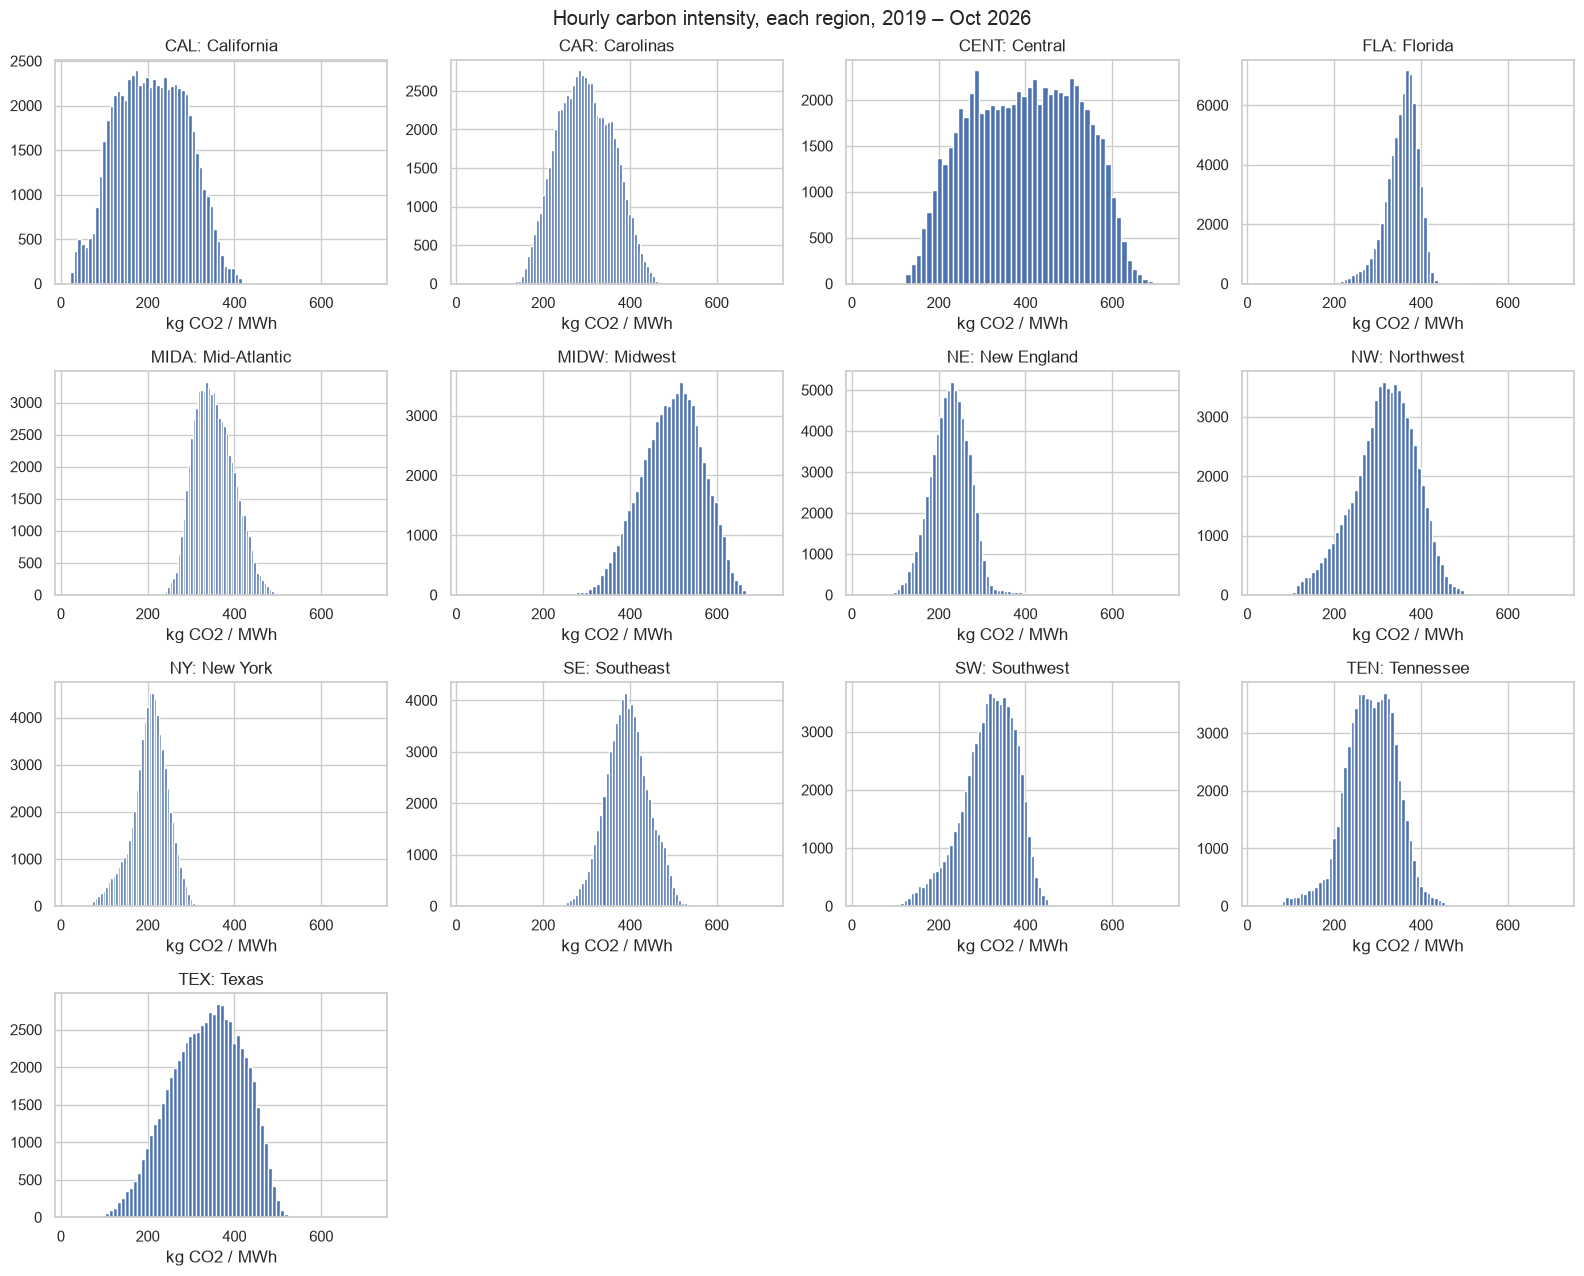

In [27]:
fig, ax = grid13()
for r in REGIONS:
    ax[r].hist(R.loc[R.region == r, "ci"].dropna(), bins=50, color="C0")
    ax[r].set_title(f"{r}: {RN[r]}")
    ax[r].set_xlabel("kg CO2 / MWh")
plt.suptitle("Hourly carbon intensity, each region, 2019 – Oct 2026")
plt.tight_layout()
plt.show()

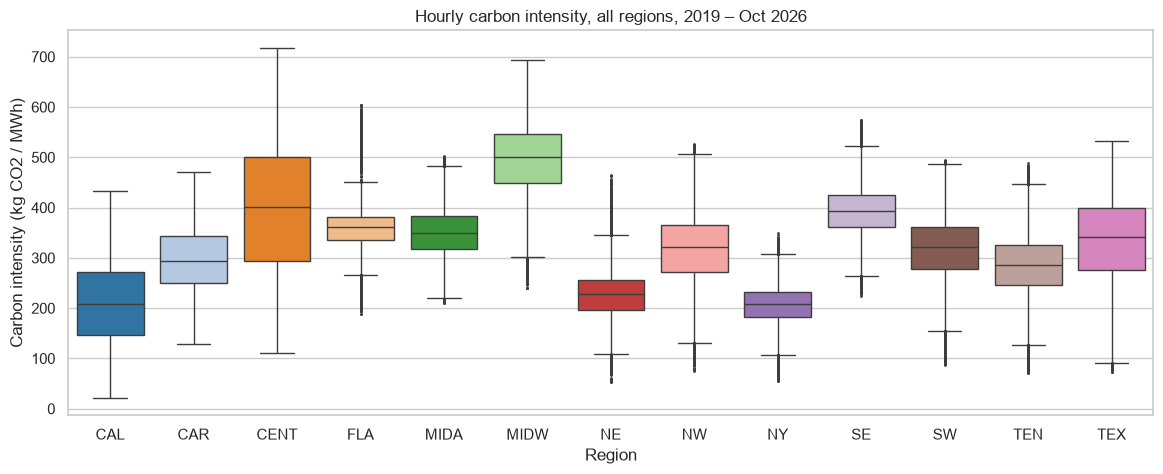

,count,mean,std,min,25%,50%,75%,max
region_name,,,,,,,,
New York,68643.0,205.0,41.0,55.0,182.0,208.0,232.0,350.0
California,68660.0,209.0,80.0,22.0,146.0,208.0,271.0,433.0
New England,68654.0,227.0,45.0,54.0,197.0,228.0,257.0,465.0
Tennessee,68659.0,284.0,59.0,71.0,246.0,286.0,326.0,489.0
Carolinas,68663.0,297.0,63.0,129.0,249.0,294.0,344.0,471.0
Northwest,68653.0,316.0,71.0,76.0,272.0,321.0,366.0,525.0
Southwest,68634.0,316.0,62.0,87.0,279.0,322.0,362.0,494.0
Texas,68627.0,335.0,82.0,73.0,276.0,341.0,399.0,533.0
Mid-Atlantic,67922.0,353.0,46.0,210.0,318.0,349.0,384.0,502.0


In [28]:
# all together
fig, ax = plt.subplots(figsize=(14, 5))
sns.boxplot(data=R, x="region", y="ci", order=REGIONS, palette=PAL13, hue="region", legend=False, fliersize=1, ax=ax)
ax.set_xlabel("Region")
ax.set_ylabel("Carbon intensity (kg CO2 / MWh)")
ax.set_title("Hourly carbon intensity, all regions, 2019 – Oct 2026")
plt.show()

R.groupby("region_name").ci.describe().round(0).sort_values("mean")

#### (b) Energy mix

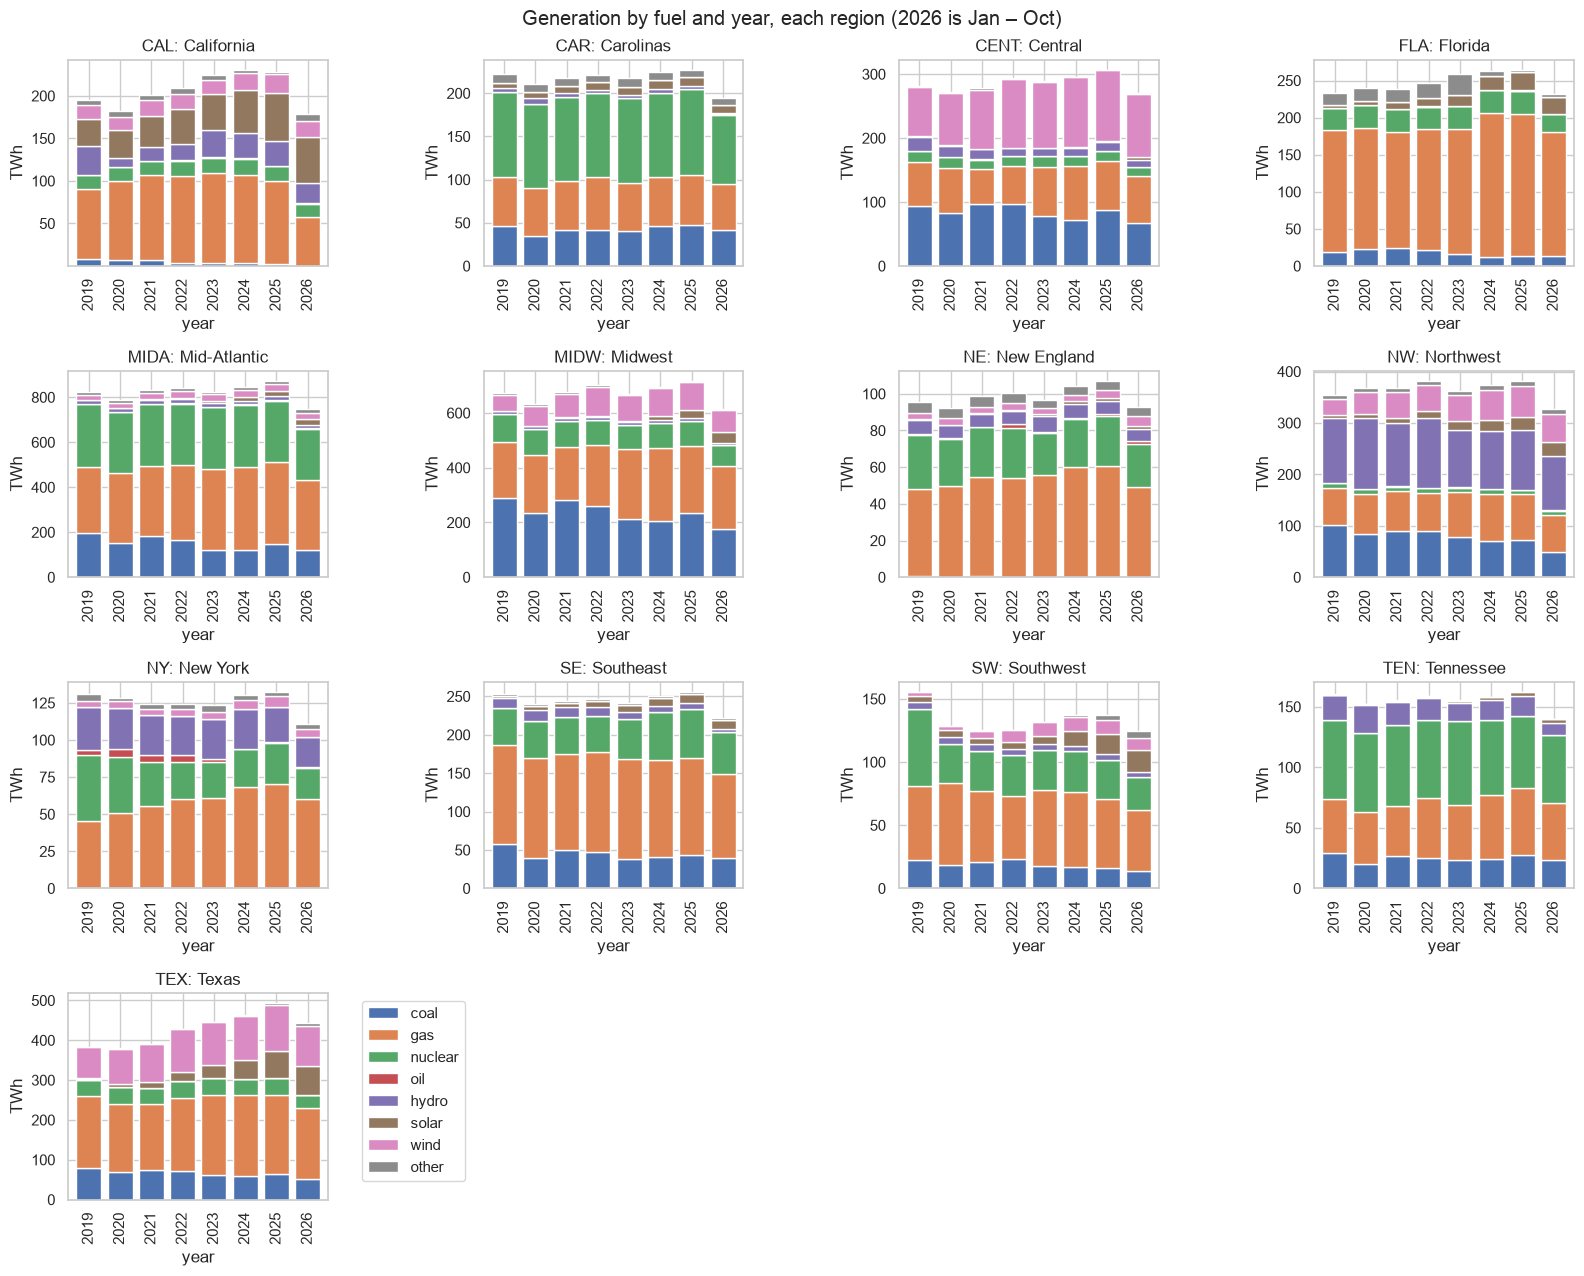

In [29]:
fig, ax = grid13(sharex=False)
for r in REGIONS:
    yearly_mix = R[R.region == r].groupby("year")[E.FUELS].sum() / 1e6     # MWh -> TWh
    yearly_mix.plot(kind="bar", stacked=True, ax=ax[r], legend=False, rot=90, width=0.8)
    ax[r].set_title(f"{r}: {RN[r]}")
    ax[r].set_ylabel("TWh")
ax["TEX"].legend(bbox_to_anchor=(1.1, 1))
plt.suptitle("Generation by fuel and year, each region (2026 is Jan – Oct)")
plt.tight_layout()
plt.show()

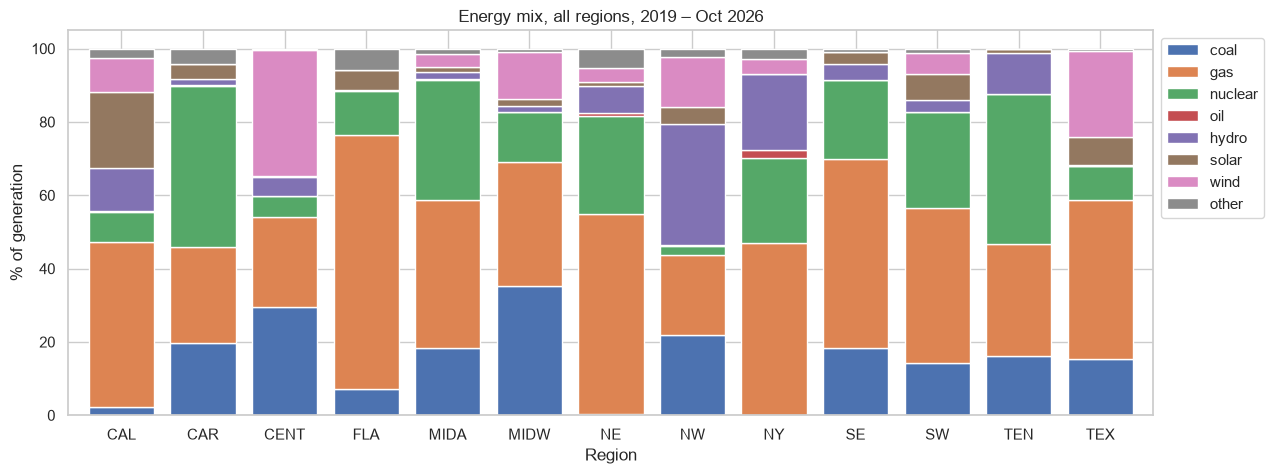

,coal,gas,nuclear,oil,hydro,solar,wind,other
region,,,,,,,,
CAL,2.200000,45.000000,8.300000,0.3,11.800000,20.799999,9.000000,2.7
CAR,19.700001,26.200001,44.099998,0.0,1.800000,4.100000,0.000000,4.2
CENT,29.600000,24.600000,5.500000,0.0,5.100000,0.500000,34.200001,0.5
FLA,7.200000,69.300003,12.100000,0.0,0.100000,5.400000,0.000000,5.9
MIDA,18.400000,40.400002,32.500000,0.4,1.900000,1.400000,3.400000,1.5
MIDW,35.200001,34.000000,13.600000,0.0,1.600000,1.800000,13.000000,0.8
NE,0.300000,54.599998,26.700001,0.8,7.500000,1.000000,4.000000,5.2
NW,21.799999,22.000000,2.400000,0.1,33.200001,4.600000,13.500000,2.4
NY,0.000000,46.900002,23.400000,2.1,20.700001,0.000000,4.000000,2.8


In [30]:
# all together: % of generation by fuel, whole period
mix = R.groupby("region")[E.FUELS].sum().reindex(REGIONS)
mix = mix.div(mix.sum(axis=1), axis=0) * 100
mix.plot(kind="bar", stacked=True, figsize=(14, 5), rot=0, width=0.8)
plt.xlabel("Region")
plt.ylabel("% of generation")
plt.title("Energy mix, all regions, 2019 – Oct 2026")
plt.legend(bbox_to_anchor=(1, 1))
plt.show()
mix.round(1)

#### (c) Carbon emissions by hour of day

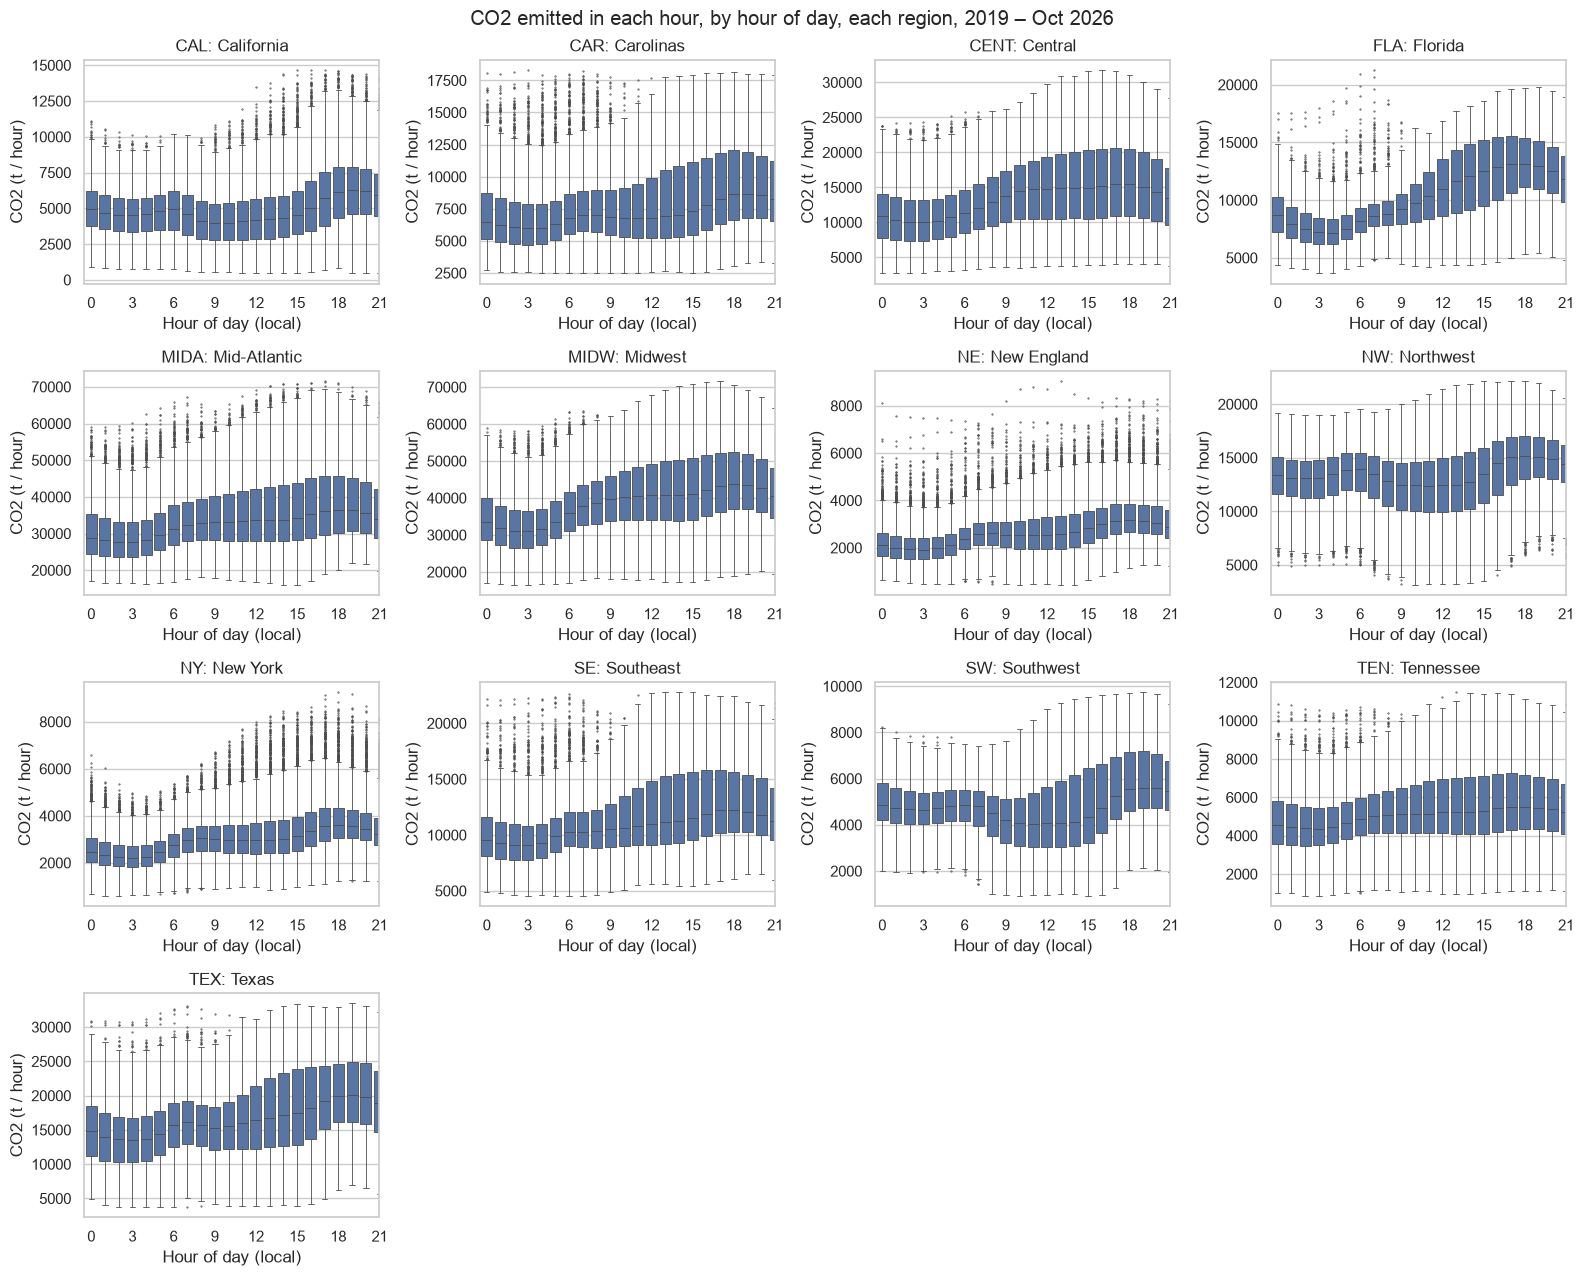

In [31]:
fig, ax = grid13()
for r in REGIONS:
    sns.boxplot(data=R[R.region == r], x="hour", y="co2_t", color="C0", fliersize=0.5, linewidth=0.6, ax=ax[r])
    ax[r].set_title(f"{r}: {RN[r]}")
    ax[r].set_xlabel("Hour of day (local)")
    ax[r].set_ylabel("CO2 (t / hour)")
    ax[r].set_xticks(range(0, 24, 3))
plt.suptitle("CO2 emitted in each hour, by hour of day, each region, 2019 – Oct 2026")
plt.tight_layout()
plt.show()

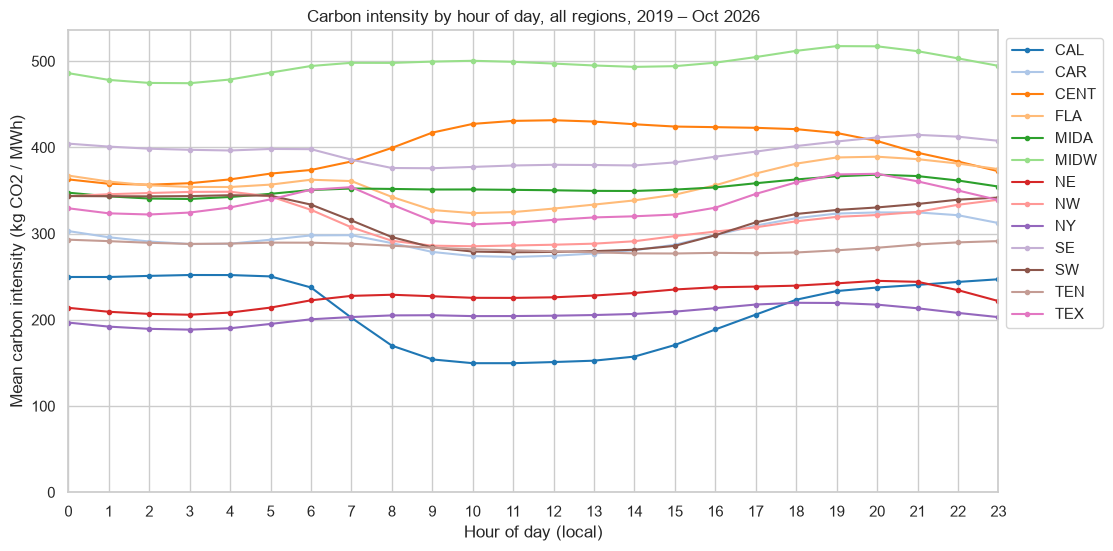

In [32]:
# all together: mean carbon intensity (per MWh, so regions of different size are comparable) by hour of day
by_hour = R.groupby(["hour", "region"]).ci.mean().unstack()[REGIONS]
by_hour.plot(figsize=(12, 6), marker="o", ms=3, color=[PAL13[r] for r in REGIONS])
plt.xlabel("Hour of day (local)")
plt.ylabel("Mean carbon intensity (kg CO2 / MWh)")
plt.title("Carbon intensity by hour of day, all regions, 2019 – Oct 2026")
plt.legend(bbox_to_anchor=(1, 1))
plt.xticks(range(24))
plt.xlim(0, 23)      # hour 0 sits on the y-axis, no padding
plt.ylim(bottom=0)   # 0 = carbon-free power, so the gap between regions is shown at true size
plt.show()

#### (d) Carbon intensity by year

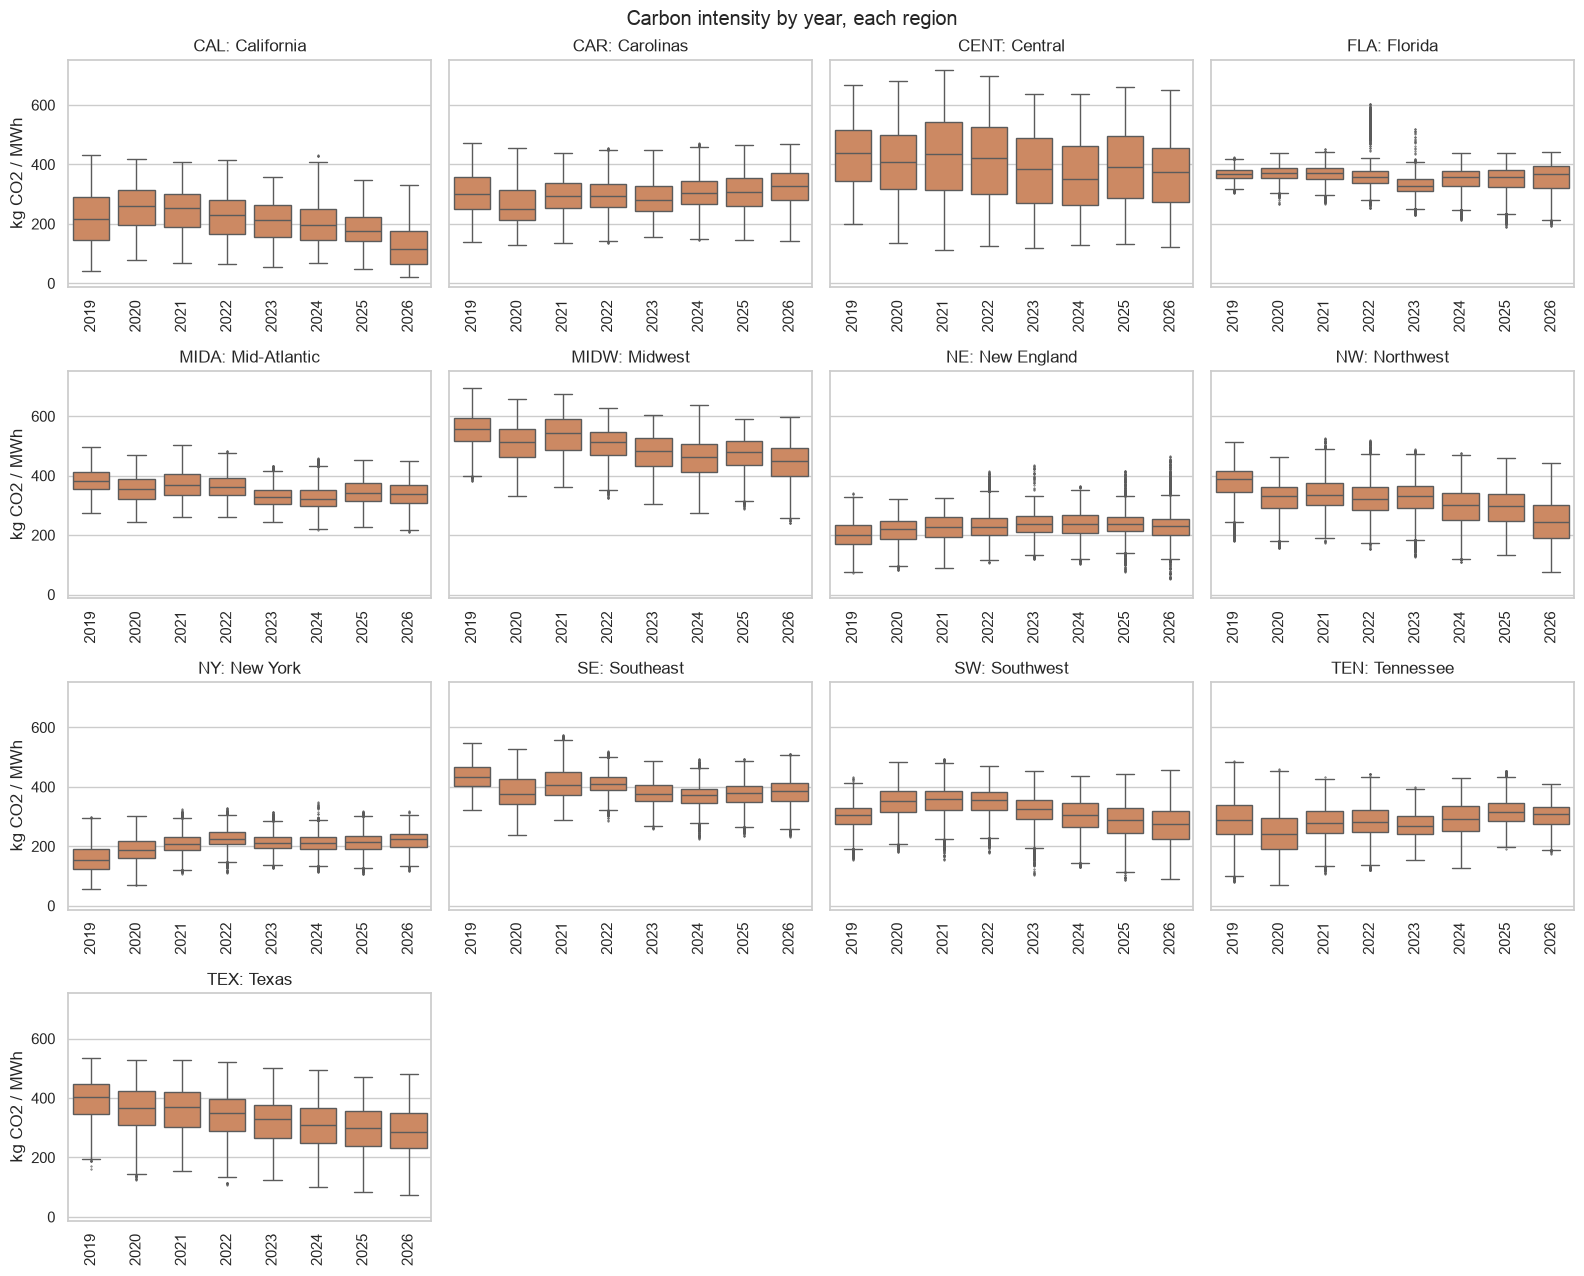

In [33]:
fig, ax = grid13(sharey=True)
for r in REGIONS:
    sns.boxplot(data=R[R.region == r], x="year", y="ci", color="C1", fliersize=0.5, ax=ax[r])
    ax[r].set_title(f"{r}: {RN[r]}")
    ax[r].set_xlabel("")
    ax[r].set_ylabel("kg CO2 / MWh")
    ax[r].tick_params(axis="x", rotation=90)
plt.suptitle("Carbon intensity by year, each region")
plt.tight_layout()
plt.show()

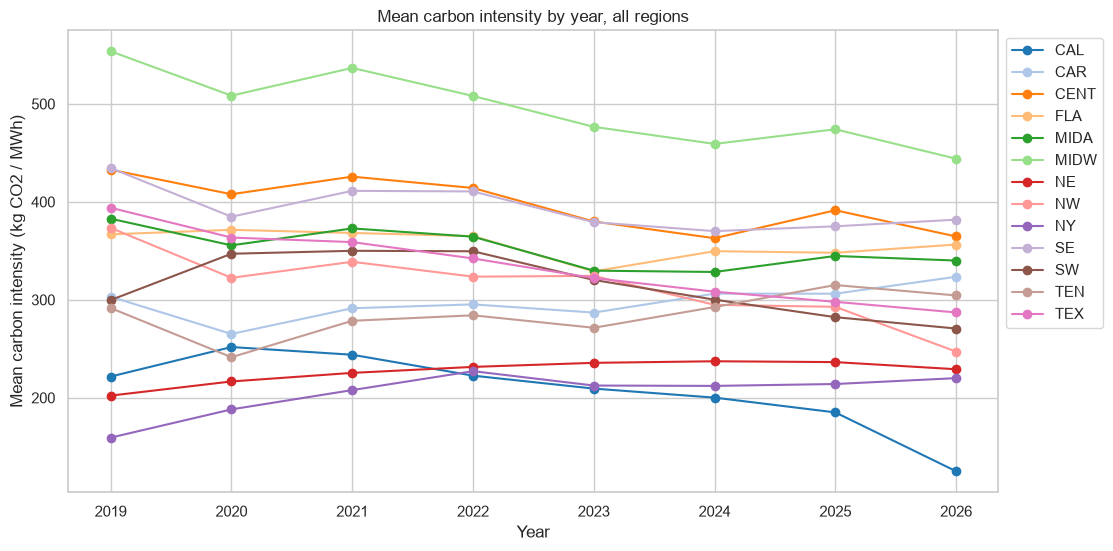

year,2019,2020,2021,2022,2023,2024,2025,2026
region,,,,,,,,
CAL,222.0,252.0,244.0,223.0,209.0,200.0,185.0,125.0
CAR,303.0,265.0,291.0,295.0,287.0,306.0,306.0,324.0
CENT,433.0,408.0,426.0,414.0,380.0,363.0,391.0,365.0
FLA,367.0,371.0,368.0,365.0,329.0,350.0,348.0,356.0
MIDA,383.0,356.0,373.0,364.0,330.0,328.0,345.0,340.0
MIDW,554.0,508.0,537.0,508.0,477.0,459.0,474.0,444.0
NE,202.0,217.0,225.0,232.0,236.0,237.0,236.0,229.0
NW,373.0,322.0,339.0,324.0,324.0,295.0,293.0,247.0
NY,159.0,188.0,208.0,227.0,212.0,212.0,214.0,220.0


In [34]:
# all together
yearly_ci = R.groupby(["year", "region"]).ci.mean().unstack()[REGIONS]
yearly_ci.plot(figsize=(12, 6), marker="o", color=[PAL13[r] for r in REGIONS])
plt.xlabel("Year")
plt.ylabel("Mean carbon intensity (kg CO2 / MWh)")
plt.title("Mean carbon intensity by year, all regions")
plt.legend(bbox_to_anchor=(1, 1))
plt.show()
yearly_ci.T.round(0)

#### (e) Daily carbon intensity over time

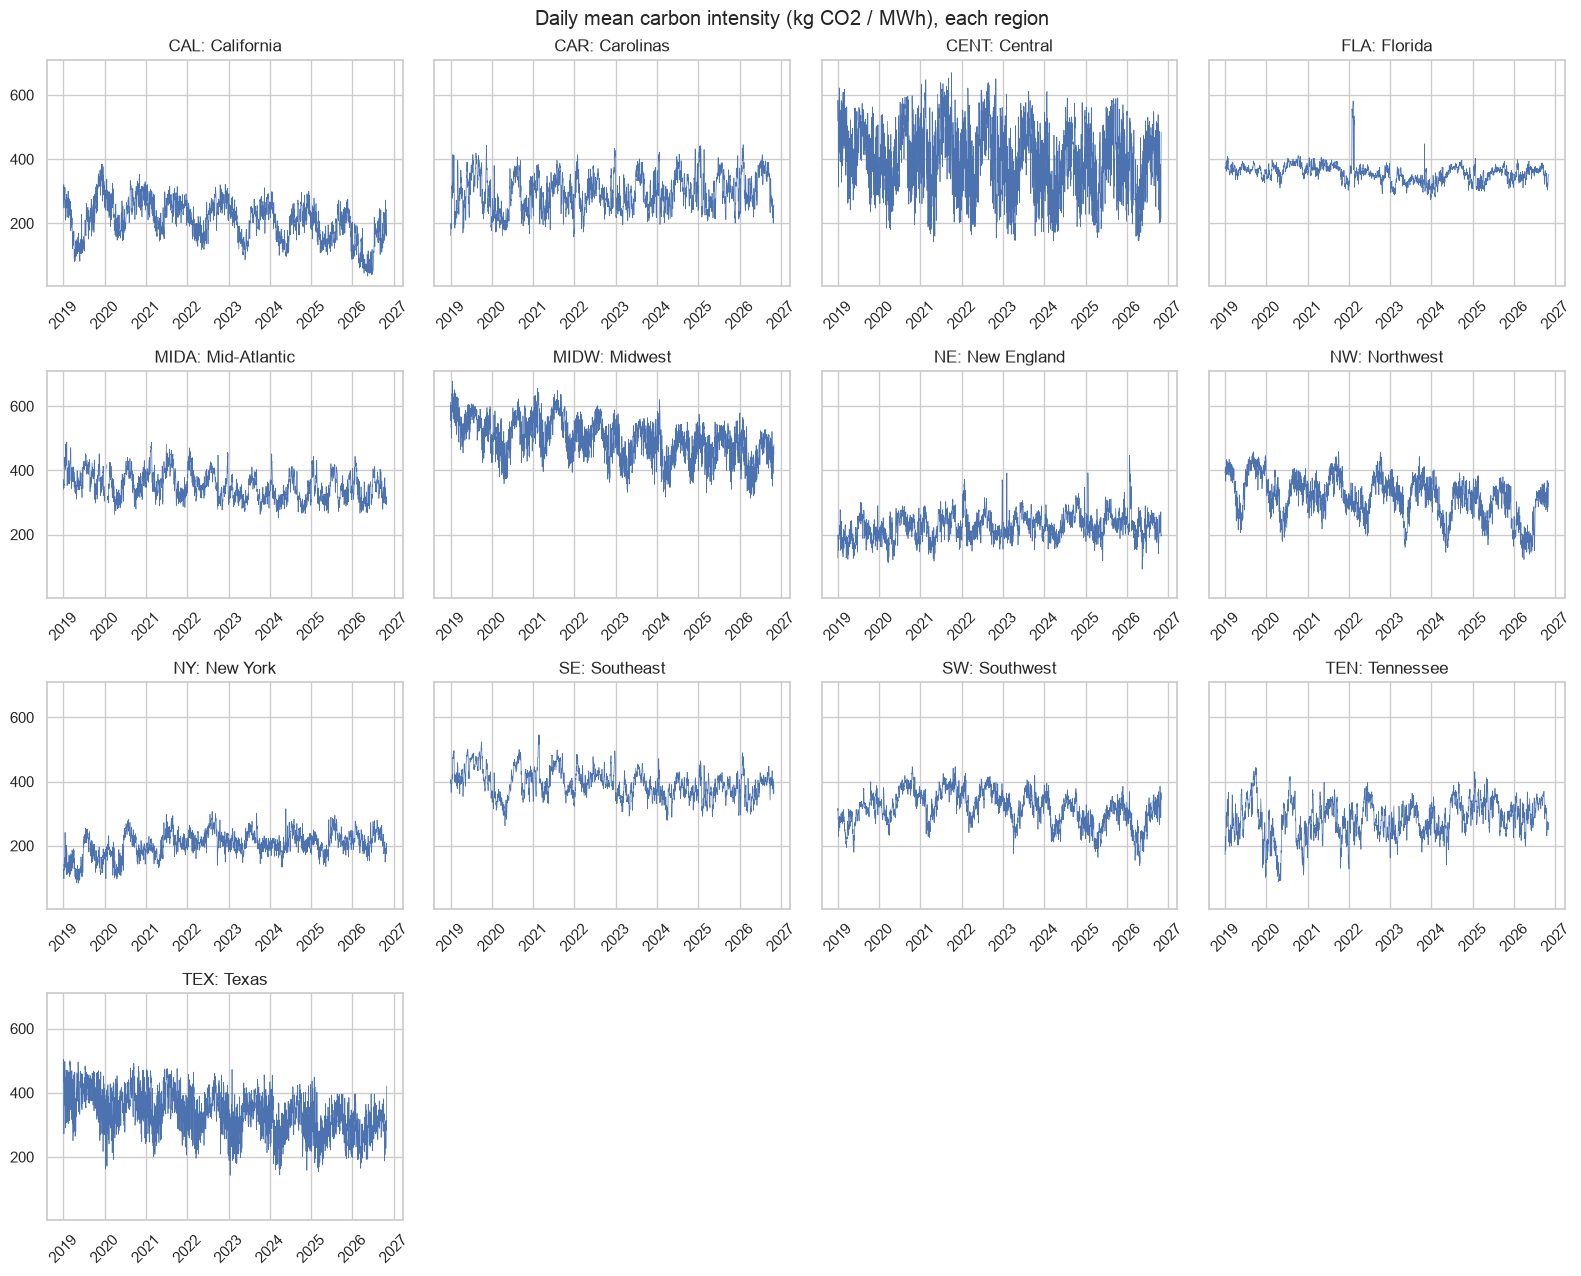

In [35]:
fig, ax = grid13(sharey=True)
for r in REGIONS:
    daily = R[R.region == r].groupby("date").ci.mean()
    ax[r].plot(daily.index, daily.values, lw=0.5, color="C0")
    ax[r].set_title(f"{r}: {RN[r]}")
    ax[r].tick_params(axis="x", rotation=45)
plt.suptitle("Daily mean carbon intensity (kg CO2 / MWh), each region")
plt.tight_layout()
plt.show()

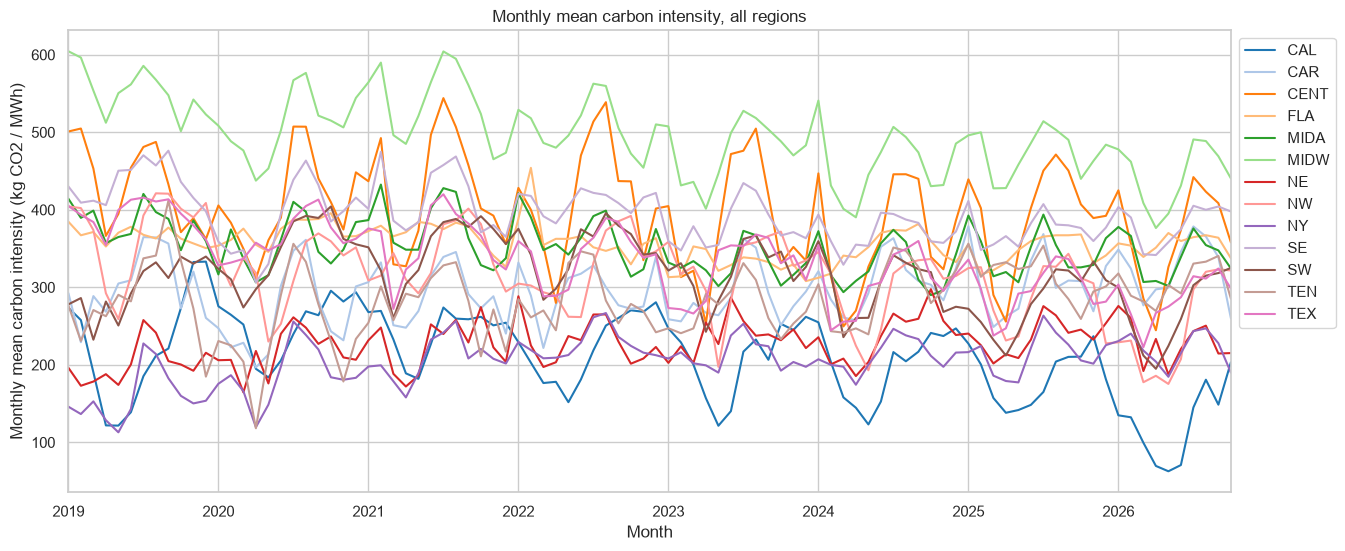

In [36]:
# all together: monthly means
monthly = R.groupby([R.date.dt.to_period("M"), "region"]).ci.mean().unstack()[REGIONS]
monthly.index = monthly.index.to_timestamp()
monthly.plot(figsize=(15, 6), color=[PAL13[r] for r in REGIONS])
plt.xlabel("Month")
plt.ylabel("Monthly mean carbon intensity (kg CO2 / MWh)")
plt.title("Monthly mean carbon intensity, all regions")
plt.legend(bbox_to_anchor=(1, 1))
plt.show()

#### (f) Demand vs carbon intensity

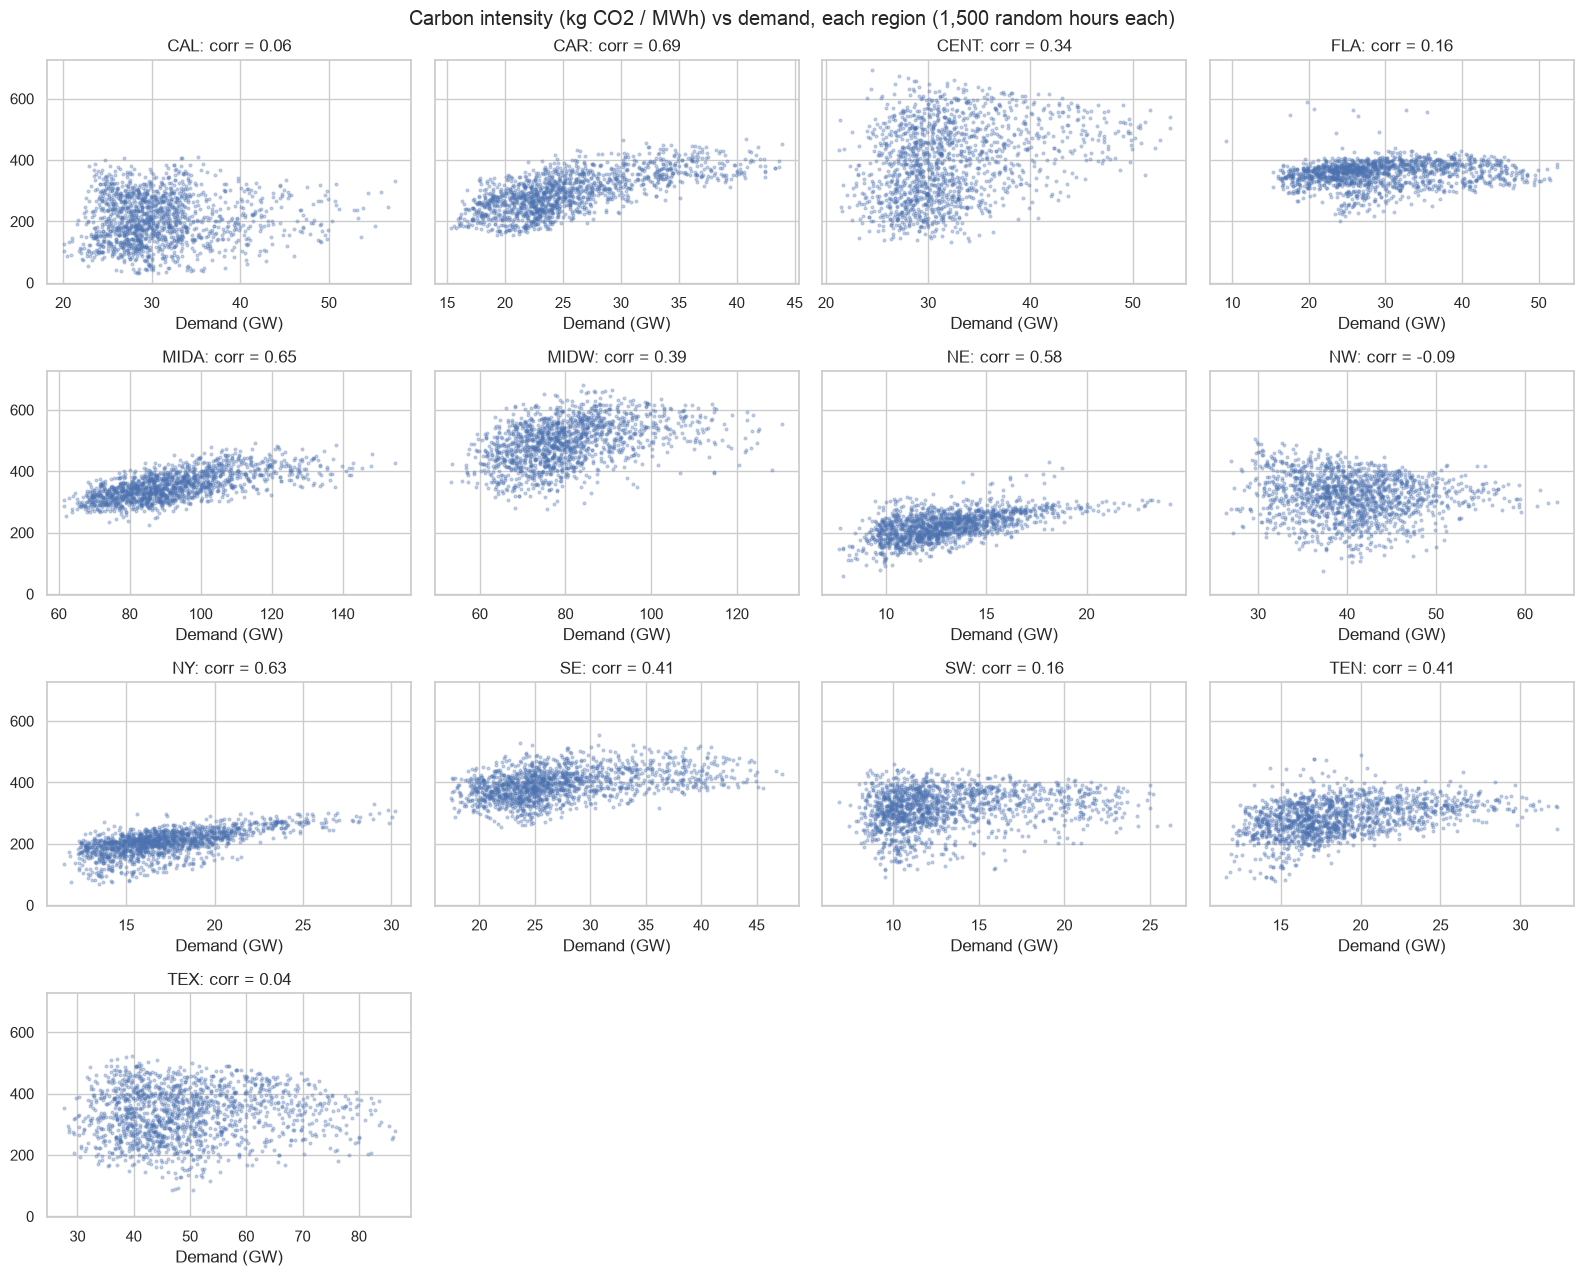

In [37]:
sample = R.dropna(subset=["ci", "demand"]).groupby("region").sample(1500, random_state=0)
fig, ax = grid13(sharex=False, sharey=True)
for r in REGIONS:
    g = sample[sample.region == r]
    ax[r].scatter(g.demand / 1e3, g.ci, s=4, alpha=0.3, color="C0")
    corr = R.loc[R.region == r, "demand"].corr(R.loc[R.region == r, "ci"])
    ax[r].set_title(f"{r}: corr = {corr:.2f}")
    ax[r].set_xlabel("Demand (GW)")
plt.suptitle("Carbon intensity (kg CO2 / MWh) vs demand, each region (1,500 random hours each)")
plt.tight_layout()
plt.show()

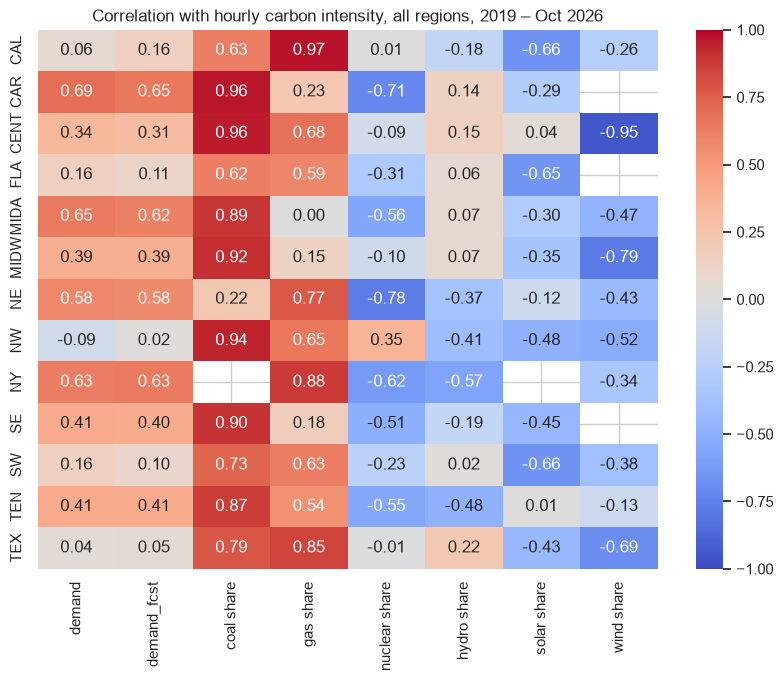

In [38]:
# all together: correlation of carbon intensity with demand and each fuel's share of generation
def drivers(g):
    gen = g[E.FUELS].clip(lower=0)
    share = gen.div(gen.sum(axis=1), axis=0).add_suffix(" share")
    X = pd.concat([g[["demand", "demand_fcst"]], share[["coal share", "gas share", "nuclear share", "hydro share", "solar share", "wind share"]]], axis=1)
    with np.errstate(divide="ignore", invalid="ignore"):   # some fuels are always 0 in some regions
        return X.corrwith(g.ci)

corr_table = pd.DataFrame({r: drivers(R[R.region == r]) for r in REGIONS}).T
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(corr_table, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation with hourly carbon intensity, all regions, 2019 – Oct 2026")
plt.show()

#### (g) Net exports

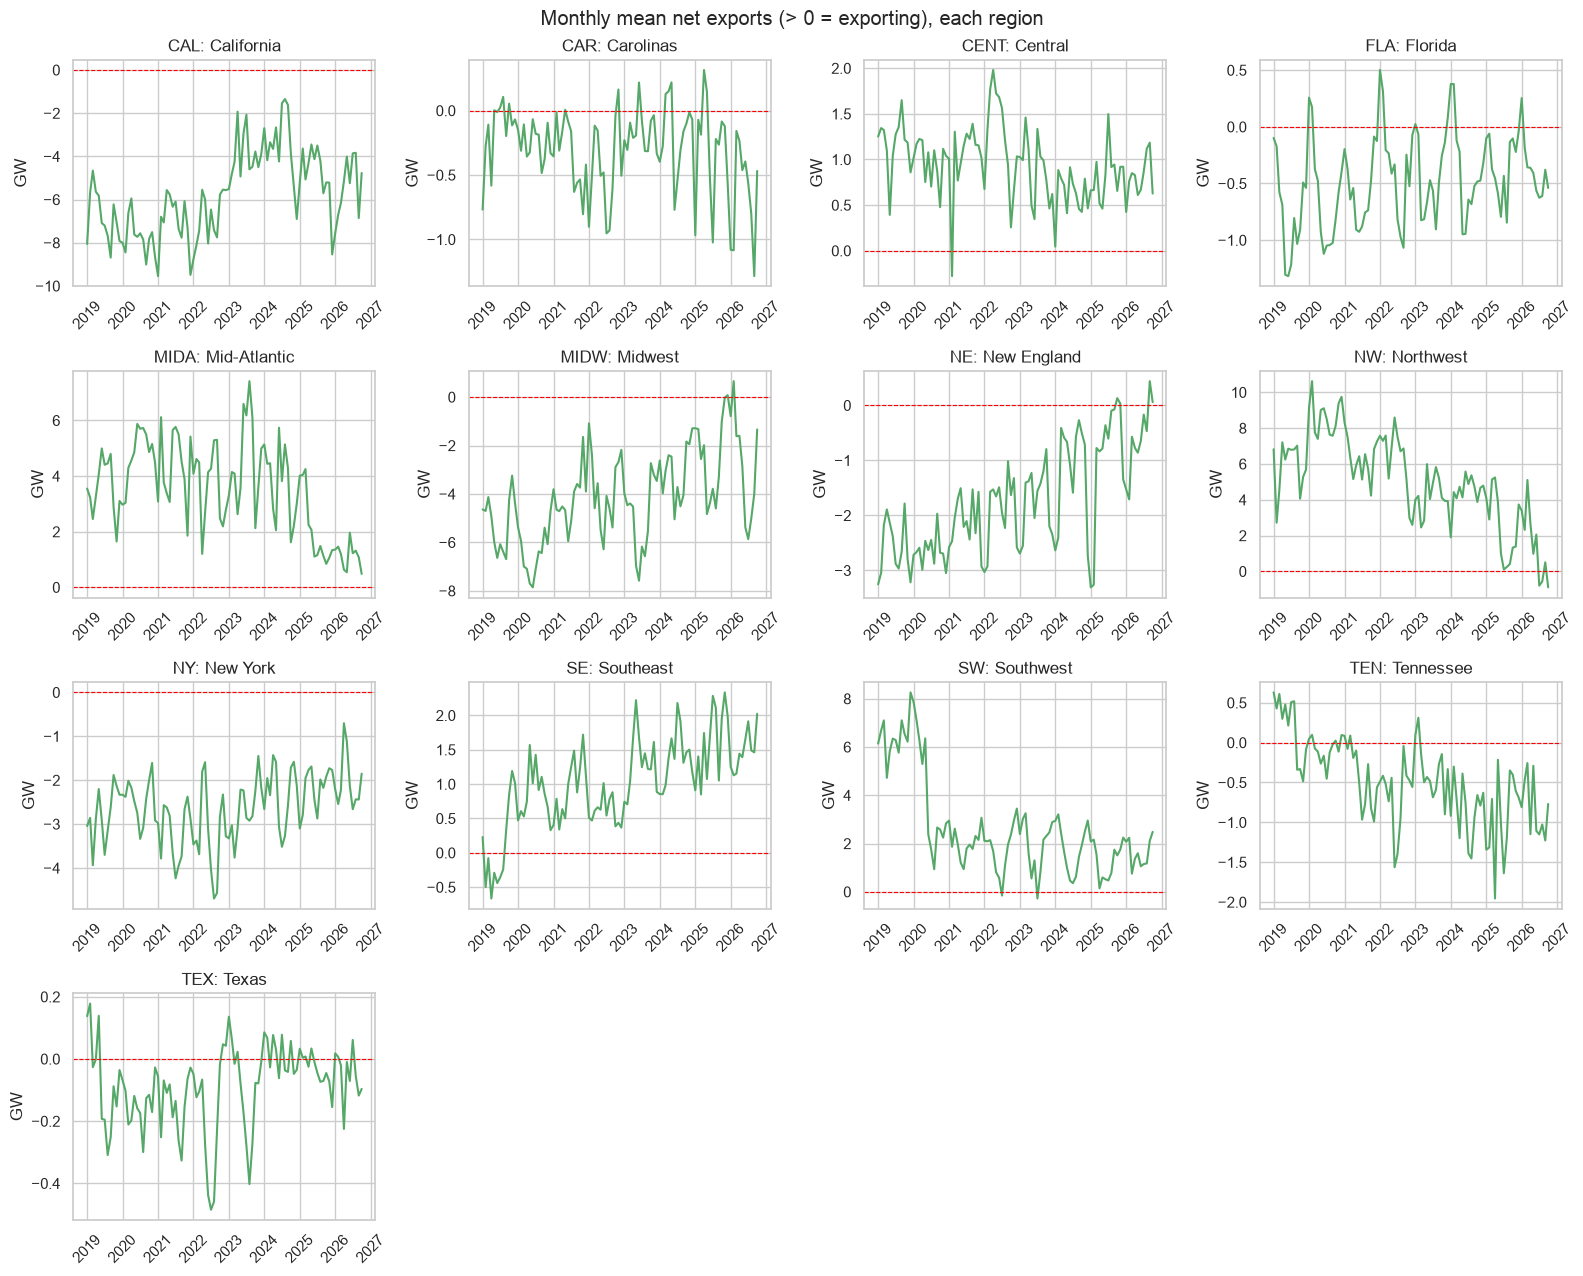

In [39]:
fig, ax = grid13(sharey=False)
for r in REGIONS:
    m = R[R.region == r].groupby(R.date.dt.to_period("M")).interchange.mean() / 1e3
    ax[r].plot(m.index.to_timestamp(), m.values, color="C2")
    ax[r].axhline(0, color="red", linestyle="--", lw=0.8)
    ax[r].set_title(f"{r}: {RN[r]}")
    ax[r].set_ylabel("GW")
    ax[r].tick_params(axis="x", rotation=45)
plt.suptitle("Monthly mean net exports (> 0 = exporting), each region")
plt.tight_layout()
plt.show()

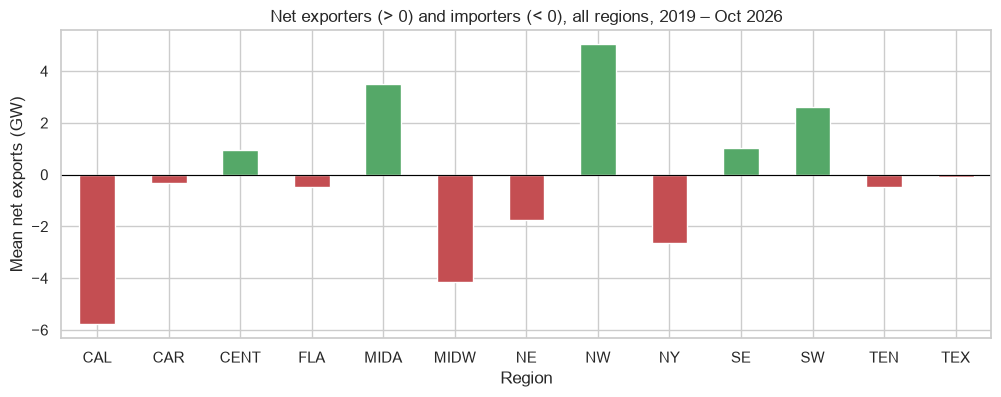

In [40]:
# all together
net = (R.groupby("region").interchange.mean() / 1e3).reindex(REGIONS)
net.plot(kind="bar", figsize=(12, 4), rot=0, color=["C2" if v > 0 else "C3" for v in net])
plt.axhline(0, color="black", lw=0.8)
plt.xlabel("Region")
plt.ylabel("Mean net exports (GW)")
plt.title("Net exporters (> 0) and importers (< 0), all regions, 2019 – Oct 2026")
plt.show()

### 5.1 Polished charts: carbon intensity over time

The charts from here on use the presentation style.

/Users/claracheng/Downloads/209a Final Project/style.py:77: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.savefig(path, dpi=300)
findfont: Failed to find font weight semibold for Arial, now using 700.
findfont: Failed to find font weight semibold for Arial, now using 700.
/Users/claracheng/anaconda3/envs/cs1090a/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


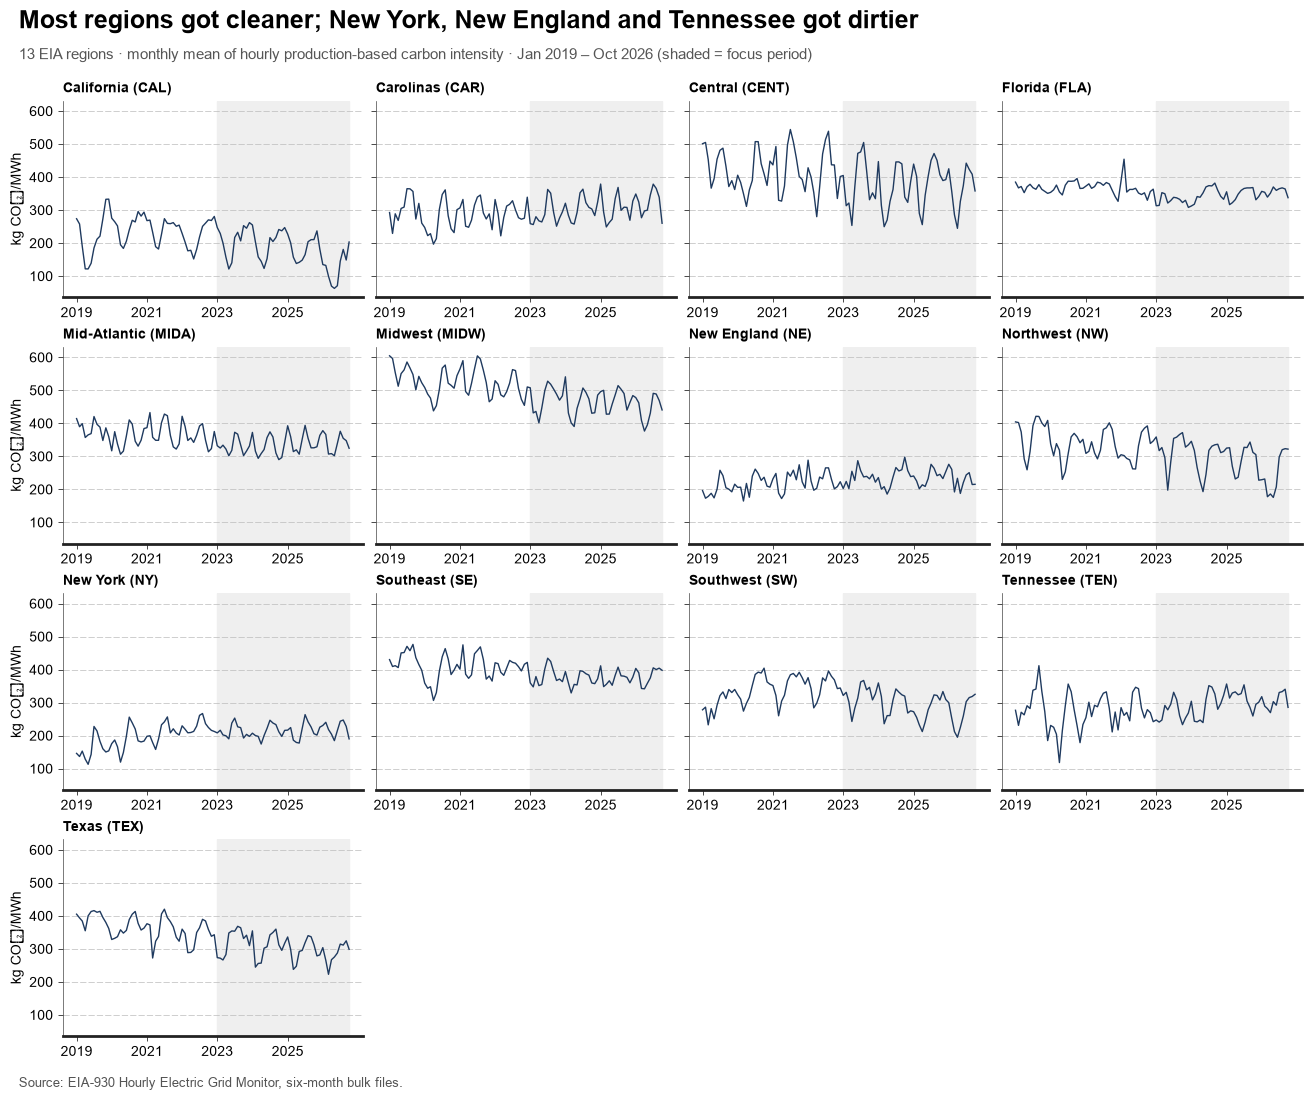

In [41]:
S.set_style()
fig, axes = plt.subplots(4, 4, figsize=(13, 11), sharex=True, sharey=True)
axes = axes.ravel()
for ax, r in zip(axes, REGIONS):
    ax.axvspan(pd.Timestamp(FOCUS_START), monthly.index.max(), color=S.NEUTRAL["shade"], zorder=0)
    ax.plot(monthly.index, monthly[r], color=S.NAVY, lw=S.LINE_PT["medium"])
    ax.set_title(f"{RN[r]} ({r})", fontsize=10)
    S.chart_lines(ax)
    ax.set_xticks(pd.to_datetime(["2019-01-01", "2021-01-01", "2023-01-01", "2025-01-01"]))
    ax.set_xticklabels(["2019", "2021", "2023", "2025"])
    ax.xaxis.set_tick_params(labelbottom=True)
for ax in axes[len(REGIONS):]:
    ax.axis("off")
for ax in axes[::4]:
    ax.set_ylabel("kg CO₂/MWh")
S.frame(fig, "Most regions got cleaner; New York, New England and Tennessee got dirtier",
        "13 EIA regions · monthly mean of hourly production-based carbon intensity · Jan 2019 – Oct 2026 (shaded = focus period)")
S.save(fig, f"{FIG}/01_ci_monthly_by_region.png")

/Users/claracheng/Downloads/209a Final Project/style.py:77: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.savefig(path, dpi=300)
/Users/claracheng/anaconda3/envs/cs1090a/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


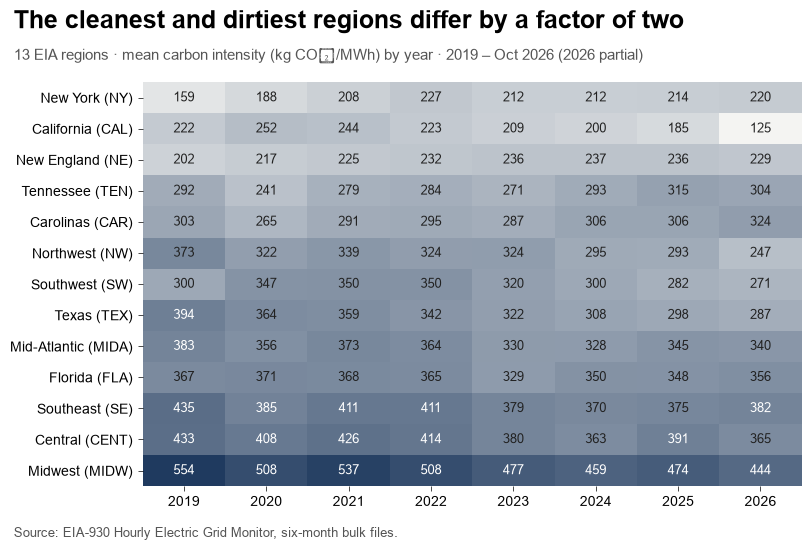

In [42]:
# all together: mean carbon intensity by region and year
order = yearly_ci.mean().sort_values().index
fig, ax = plt.subplots(figsize=S.PANEL["L"])
im = ax.imshow(yearly_ci[order].T.values, aspect="auto", cmap=S.SEQ)
ax.set_yticks(range(len(order))); ax.set_yticklabels([f"{RN[r]} ({r})" for r in order])
ax.set_xticks(range(len(yearly_ci))); ax.set_xticklabels(yearly_ci.index)
for i, r in enumerate(order):
    for j, y in enumerate(yearly_ci.index):
        v = yearly_ci.loc[y, r]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=9, color="white" if v > 380 else S.NEUTRAL["ink"])
for sp in ax.spines.values(): sp.set_visible(False)
S.frame(fig, "The cleanest and dirtiest regions differ by a factor of two",
        "13 EIA regions · mean carbon intensity (kg CO₂/MWh) by year · 2019 – Oct 2026 (2026 partial)")
S.save(fig, f"{FIG}/02_ci_region_by_year.png")

### 5.2 Polished chart: what each region runs on

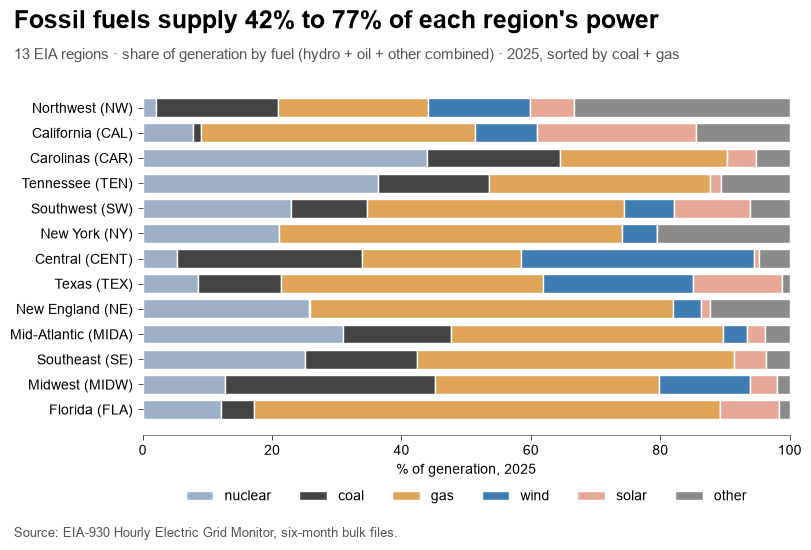

,nuclear,coal,gas,wind,solar,other
region,,,,,,
NW,2.000000,18.900000,23.200001,15.800000,6.8,33.299999
CAL,7.700000,1.300000,42.400002,9.500000,24.6,14.500000
CAR,43.900002,20.600000,25.700001,0.000000,4.5,5.300000
TEN,36.400002,17.100000,34.200001,-0.000000,1.7,10.600000
SW,22.900000,11.900000,39.599998,7.800000,11.8,6.100000
NY,21.100000,0.000000,53.000000,5.300000,0.0,20.500000
CENT,5.300000,28.500000,24.700001,35.900002,0.8,4.700000
TEX,8.500000,12.800000,40.500000,23.299999,13.7,1.200000
NE,25.600000,0.300000,56.099998,4.200000,1.5,12.300000


In [43]:
m25 = R[R.year == 2025].copy()
m25["other"] = m25[["hydro", "oil", "other"]].sum(axis=1)       # small fuels combined, as in style.FUEL_COLOR
share = m25.groupby("region")[list(S.FUEL_COLOR)].sum()
share = share.div(share.sum(axis=1), axis=0) * 100
share = share.loc[share.eval("coal + gas").sort_values().index]   # cleanest mix at the top

fig, ax = plt.subplots(figsize=S.PANEL["L"])
left = np.zeros(len(share))
for f, col in S.FUEL_COLOR.items():
    ax.barh(range(len(share)), share[f], left=left, color=col, edgecolor="white", linewidth=1, height=0.75, label=f)
    left += share[f].values
ax.set_yticks(range(len(share))); ax.set_yticklabels([f"{RN[r]} ({r})" for r in share.index])
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.set_xlabel("% of generation, 2025")
ax.legend(ncol=6, loc="upper center", bbox_to_anchor=(0.5, -0.12))
for sp in ("top", "right", "left"): ax.spines[sp].set_visible(False)
S.frame(fig, "Fossil fuels supply 42% to 77% of each region's power",
        "13 EIA regions · share of generation by fuel (hydro + oil + other combined) · 2025, sorted by coal + gas")
S.save(fig, f"{FIG}/03_generation_mix_by_region.png")
share.round(1)

### 5.3 Why we focus on 2023 onward

The full timeline is useful context, but the early years are a poor guide to today's grid:

- **Data problems cluster before 2023:** PJM's broken fuel mix in January 2020, interchange that doesn't add up in several regions in 2019–2020, and most of the BA reshuffling.
- **2020–2021 are COVID years**, with unusual demand.
- **The grid changed quickly.** Solar's share of generation grew from 1% to 14% in Texas, from 3% to 12% in the Southwest, and from 1.5% to 9% in Florida between 2019 and 2025. Even within 2023–2026 the daily shape keeps moving (Section 6).

So, as a team, the rest of the analysis uses **Jan 2023 – Oct 2026** (33,599 hours per region).

## 6. EDA: focus period (Jan 2023 – Oct 2026)

In [44]:
F = R[R.date >= FOCUS_START].copy()
print(f"focus period: {F.date.min().date()} → {F.date.max().date()},  {len(F):,} rows ({len(F) // 13:,} hours per region)")
F.groupby("region_name").ci.describe().round(0).sort_values("mean")

focus period: 2023-01-01 → 2026-10-31,  436,788 rows (33,599 hours per region)


,count,mean,std,min,25%,50%,75%,max
region_name,,,,,,,,
California,33597.0,182.0,72.0,22.0,129.0,178.0,238.0,433.0
New York,33586.0,214.0,31.0,107.0,193.0,214.0,235.0,350.0
New England,33597.0,235.0,42.0,54.0,208.0,235.0,261.0,465.0
Northwest,33589.0,292.0,72.0,76.0,243.0,300.0,344.0,489.0
Southwest,33578.0,294.0,64.0,87.0,256.0,302.0,342.0,456.0
Tennessee,33597.0,296.0,48.0,126.0,260.0,297.0,331.0,452.0
Carolinas,33599.0,305.0,60.0,144.0,259.0,302.0,351.0,471.0
Texas,33578.0,305.0,79.0,73.0,246.0,307.0,365.0,502.0
Mid-Atlantic,33589.0,336.0,40.0,210.0,306.0,332.0,362.0,458.0


### 6.0 Basic EDA on the focus period

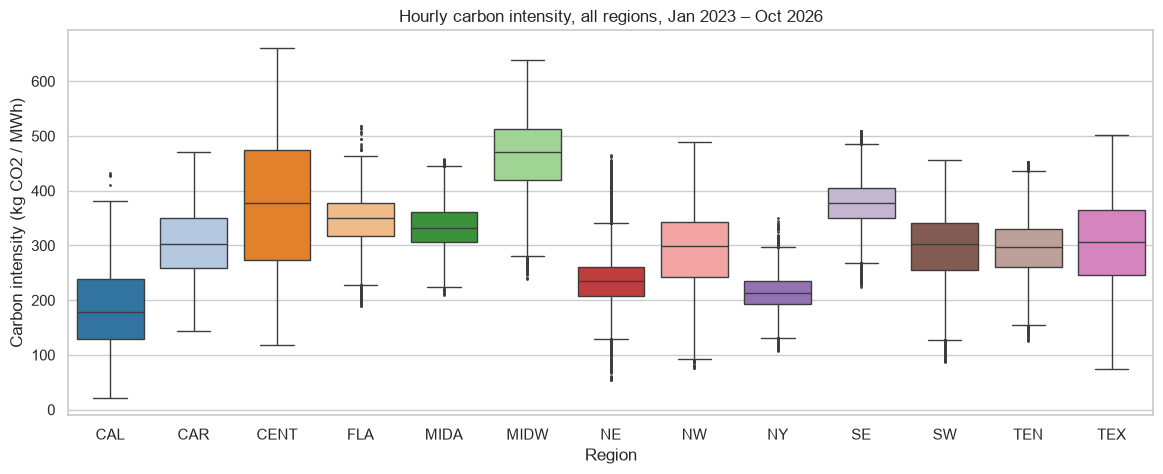

In [45]:
plt.rcdefaults()
sns.set_theme(style="whitegrid")

# all together: distribution of the target
fig, ax = plt.subplots(figsize=(14, 5))
sns.boxplot(data=F, x="region", y="ci", order=REGIONS, palette=PAL13, hue="region", legend=False, fliersize=1, ax=ax)
ax.set_xlabel("Region")
ax.set_ylabel("Carbon intensity (kg CO2 / MWh)")
ax.set_title("Hourly carbon intensity, all regions, Jan 2023 – Oct 2026")
plt.show()

#### (a) The daily shape: mean carbon intensity by hour, one line per year

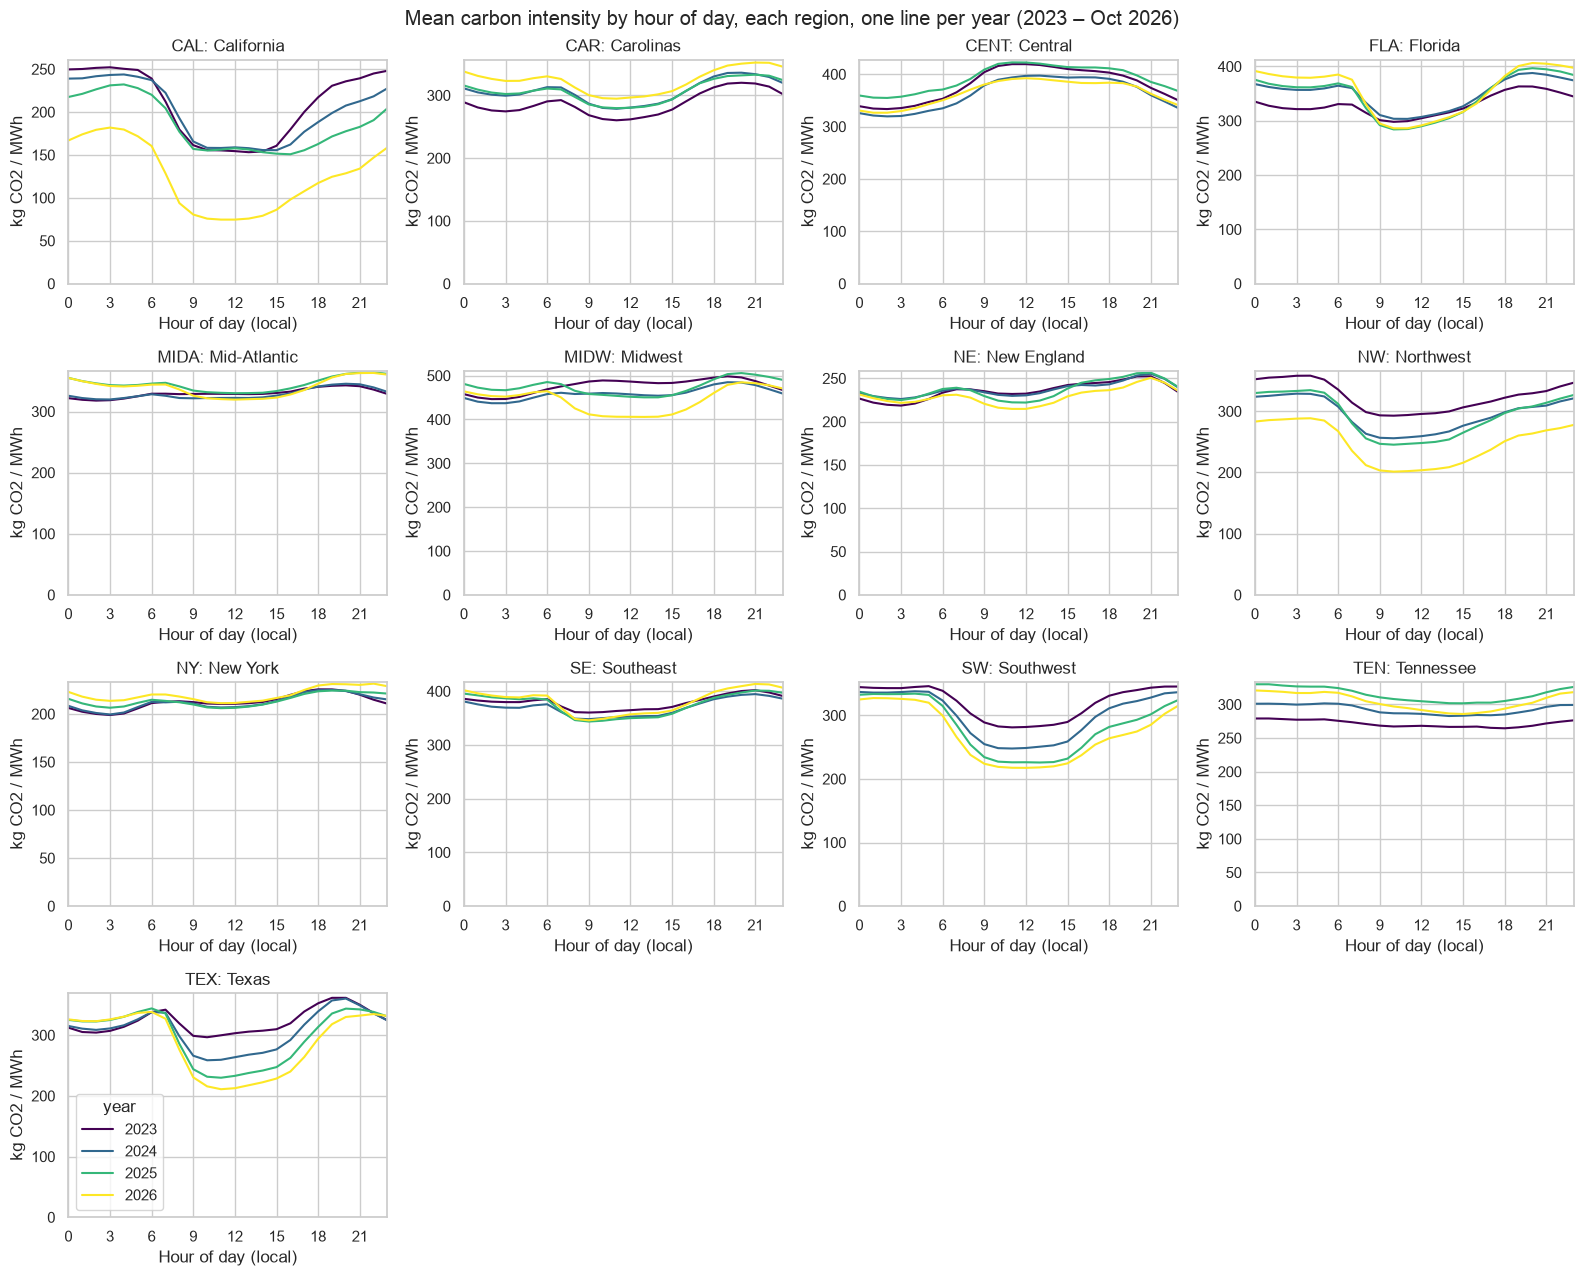

In [46]:
fig, ax = grid13(sharey=False)
for r in REGIONS:
    sns.lineplot(data=F[F.region == r], x="hour", y="ci", hue="year", palette="viridis", errorbar=None, ax=ax[r], legend=(r == "TEX"))
    ax[r].set_title(f"{r}: {RN[r]}")
    ax[r].set_xlabel("Hour of day (local)")
    ax[r].set_ylabel("kg CO2 / MWh")
    ax[r].set_xticks(range(0, 24, 3))
    ax[r].set_xlim(0, 23)
    ax[r].set_ylim(bottom=0)
plt.suptitle("Mean carbon intensity by hour of day, each region, one line per year (2023 – Oct 2026)")
plt.tight_layout()
plt.show()

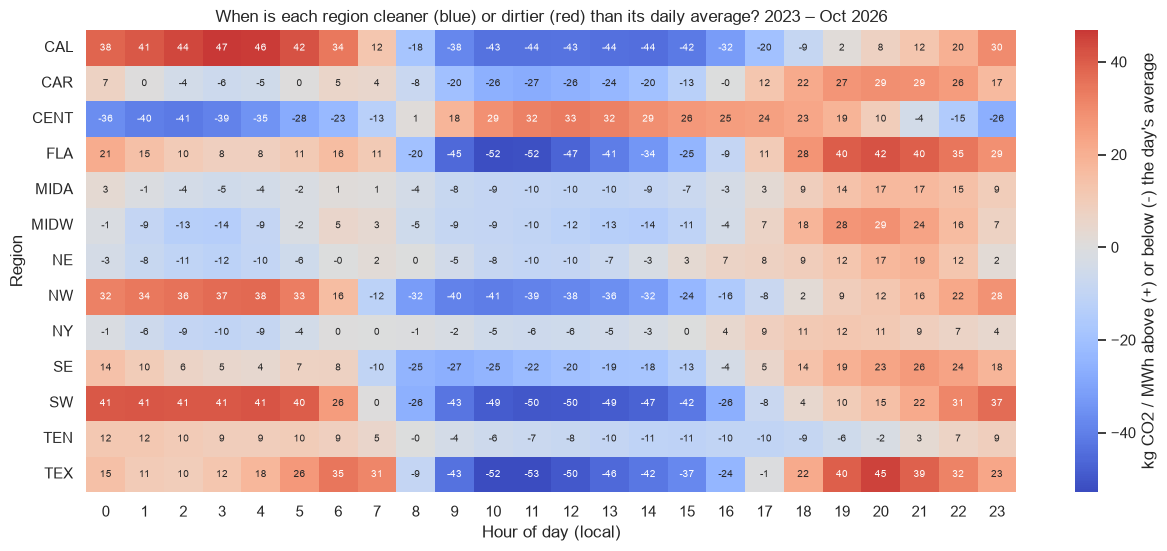

In [47]:
# all together: each hour's carbon intensity minus its own day's average (removes the level, keeps the daily shape)
F["ci_dev"] = F.ci - F.groupby(["region", "date"]).ci.transform("mean")
dev = F.groupby(["region", "hour"]).ci_dev.mean().unstack().reindex(REGIONS)
fig, ax = plt.subplots(figsize=(15, 6))
sns.heatmap(dev, cmap="coolwarm", center=0, annot=True, fmt=".0f", annot_kws={"size": 7},
            cbar_kws={"label": "kg CO2 / MWh above (+) or below (-) the day's average"}, ax=ax)
ax.set_xlabel("Hour of day (local)")
ax.set_ylabel("Region")
ax.set_title("When is each region cleaner (blue) or dirtier (red) than its daily average? 2023 – Oct 2026")
plt.show()

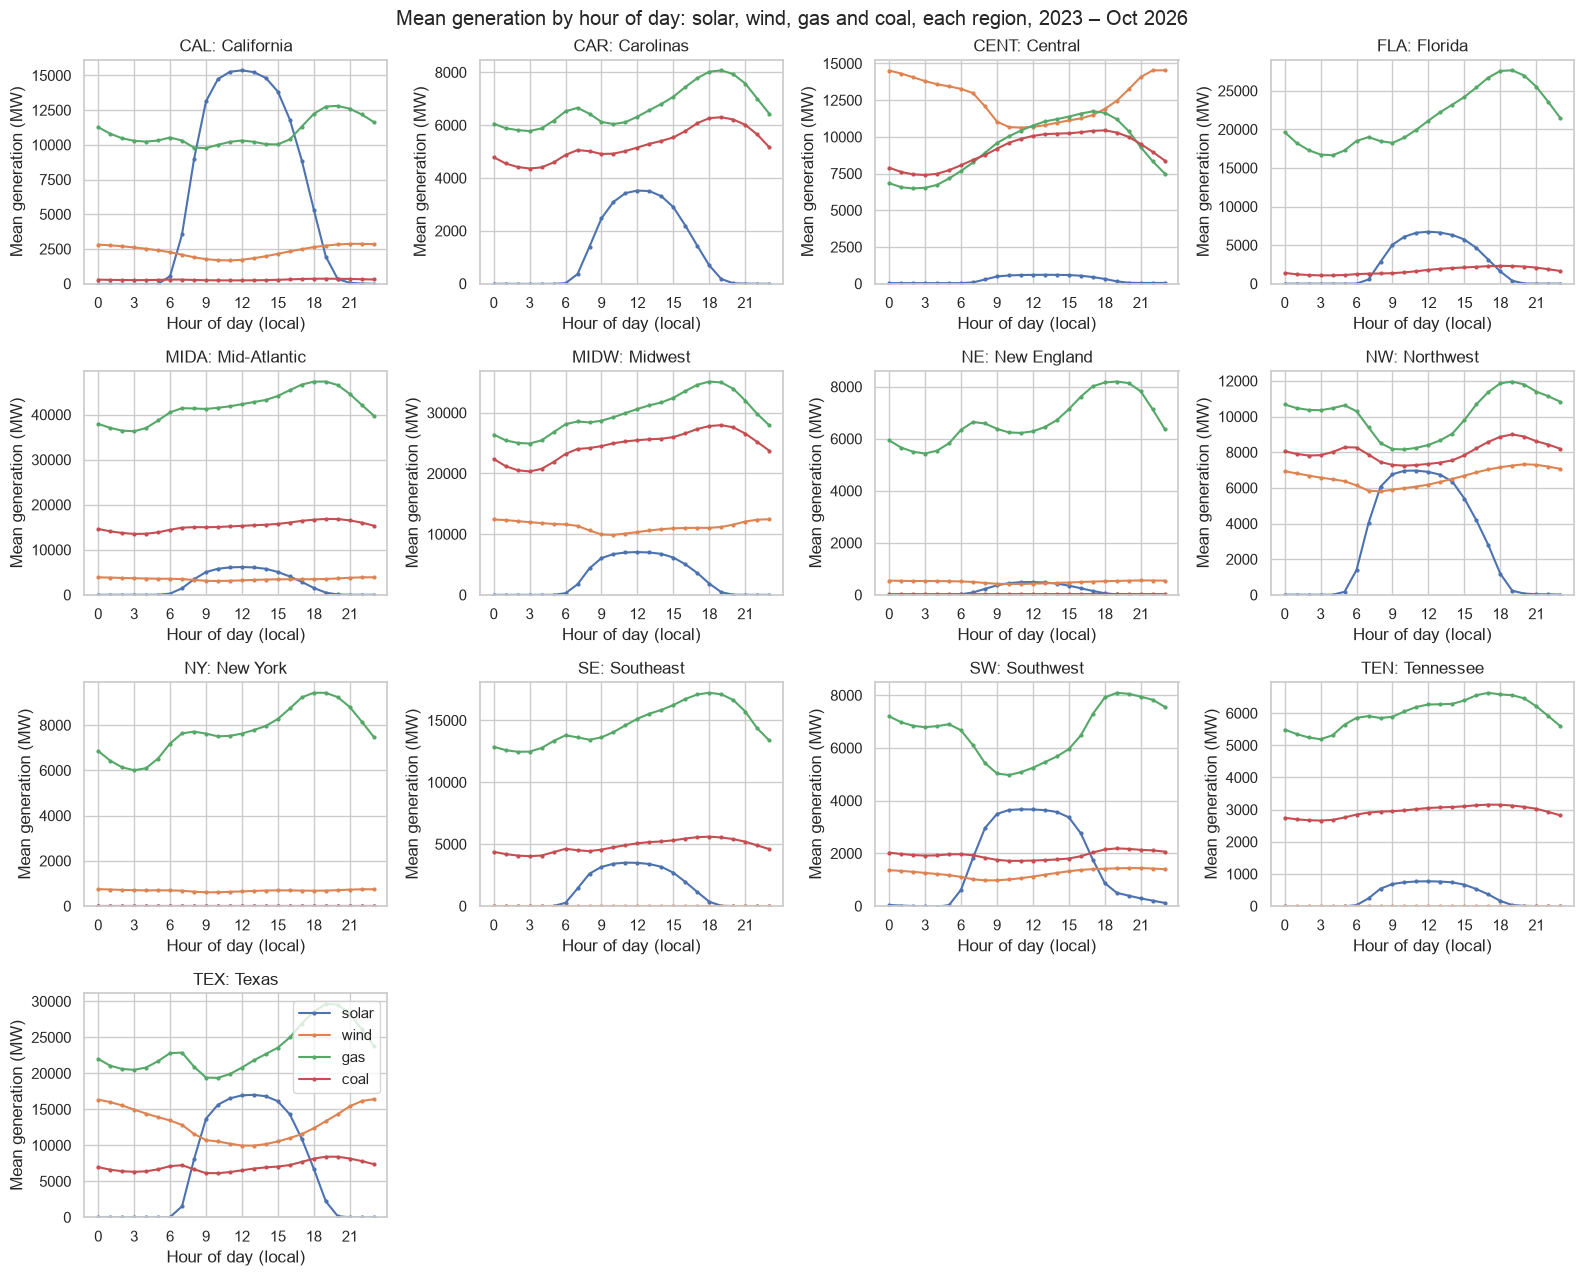

In [48]:
# solar, wind, gas and coal by hour of day: the reason the clean hours move
# y-axis starts at 0 so the size of each fuel is shown honestly; each region has its own scale
fig, ax = grid13(sharex=False, sharey=False)
for r in REGIONS:
    F[F.region == r].groupby("hour")[["solar", "wind", "gas", "coal"]].mean().plot(ax=ax[r], marker="o", ms=2, legend=(r == "TEX"))
    ax[r].set_ylim(bottom=0)
    ax[r].set_title(f"{r}: {RN[r]}")
    ax[r].set_xlabel("Hour of day (local)")
    ax[r].set_ylabel("Mean generation (MW)")
    ax[r].set_xticks(range(0, 24, 3))
plt.suptitle("Mean generation by hour of day: solar, wind, gas and coal, each region, 2023 – Oct 2026")
plt.tight_layout()
plt.show()

#### (b) The cleanest hour of each day

For every complete day we find the one hour with the **lowest carbon intensity**, then count how often each hour wins. A bar at 12 that reaches 30% means: on 30% of days, the 12:00–13:00 hour was the cleanest hour of that day. Each panel's bars add up to 100%.

**Read the bar at 23 with care.** In Central, the Midwest, New England and New York, hour 23 wins more often than its neighbours. That is a calendar edge effect, not a cleaner hour. On those nights carbon intensity is still falling as wind picks up, so the true low comes after midnight, on the next calendar day. On about 90% of the days where 23:00 wins, the hour after midnight is even lower. The real pattern in those regions is "cleanest overnight", spread across 23:00–05:00.

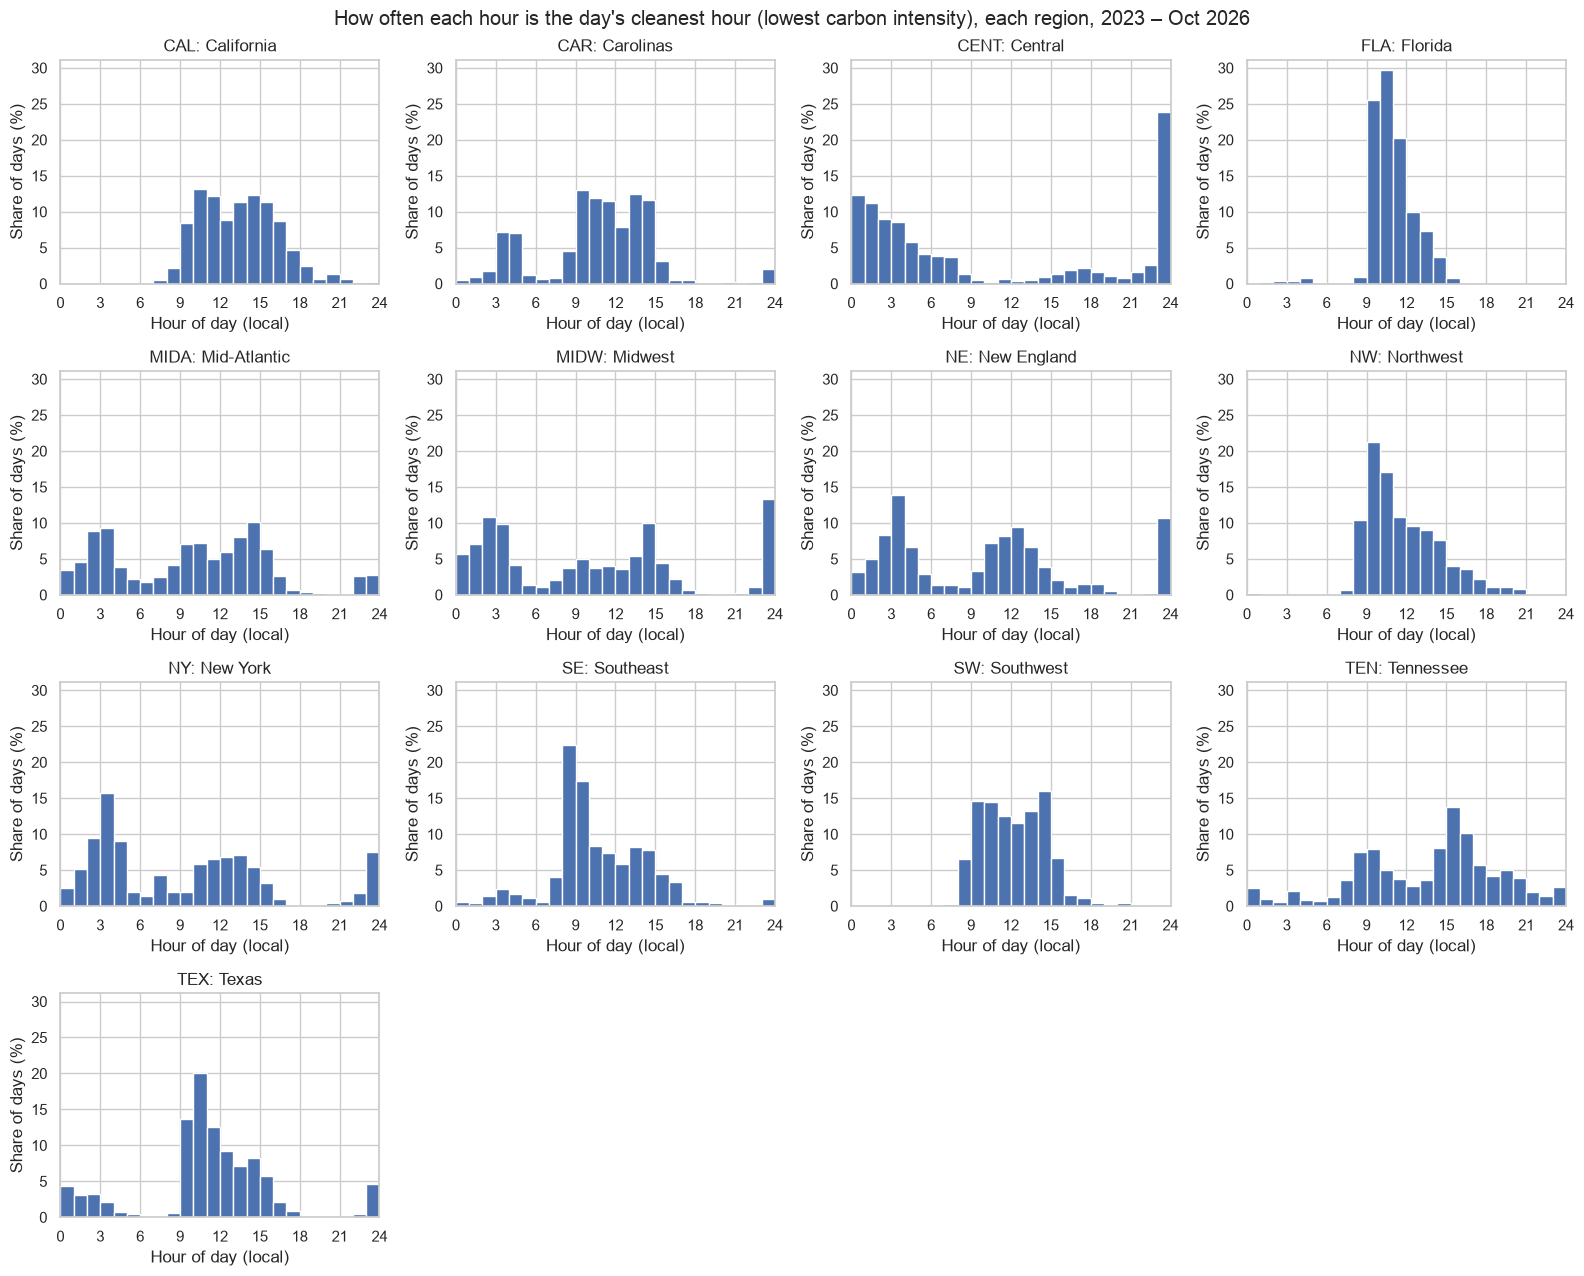

In [49]:
full = F.dropna(subset=["ci"])
full = full[full.groupby(["region", "date"]).ci.transform("size") == 24]       # complete days only
best = full.loc[full.groupby(["region", "date"]).ci.idxmin()]

fig, ax = grid13(sharex=False, sharey=True)
for r in REGIONS:
    share = best[best.region == r].hour.value_counts(normalize=True).mul(100).reindex(range(24), fill_value=0)
    ax[r].bar(share.index, share.values, width=1, align="edge", color="C0", edgecolor="white")  # bar h spans h:00-h+1:00
    ax[r].set_xlim(0, 24)
    ax[r].set_xticks(range(0, 25, 3))
    ax[r].set_title(f"{r}: {RN[r]}")
    ax[r].set_xlabel("Hour of day (local)")
    ax[r].set_ylabel("Share of days (%)")
    ax[r].yaxis.set_tick_params(labelleft=True)   # same scale on every panel, numbers on every panel
plt.suptitle("How often each hour is the day's cleanest hour (lowest carbon intensity), each region, 2023 – Oct 2026")
plt.tight_layout()
plt.show()

In [50]:
# all together: share of days whose cleanest hour is overnight (0-5) vs midday (10-15), by year
when = best.assign(overnight=best.hour.between(0, 5), midday=best.hour.between(10, 15))
when.groupby(["region_name", "year"])[["overnight", "midday"]].mean().mul(100).round(0).unstack()

overnight                   midday                  
year              2023  2024  2025  2026   2023  2024  2025  2026
region_name                                                      
California         0.0   1.0   1.0   0.0   84.0  70.0  39.0  88.0
Carolinas         25.0  19.0  20.0   9.0   56.0  57.0  58.0  64.0
Central           53.0  51.0  47.0  54.0    2.0   4.0   6.0   4.0
Florida            6.0   1.0   0.0   0.0   60.0  75.0  76.0  77.0
Mid-Atlantic      57.0  42.0  19.0   7.0   17.0  30.0  57.0  71.0
Midwest           63.0  52.0  27.0  10.0    6.0  18.0  45.0  61.0
New England       57.0  41.0  31.0  28.0   24.0  35.0  45.0  48.0
New York          56.0  50.0  35.0  32.0   18.0  29.0  44.0  50.0
Northwest          1.0   0.0   0.0   0.0   52.0  55.0  61.0  64.0
Southeast         10.0  13.0   3.0   4.0   45.0  35.0  48.0  41.0
Southwest          0.0   0.0   0.0   0.0   74.0  70.0  77.0  79.0
Tennessee         12.0   8.0   4.0   7.0   27.0  35.0  42.0  45.0
Texas             35.0  13.0   6.0   1.0   28.0  59.0  81.0  90.0

#### (c) How much does picking the hour matter?

For each complete day: how much cleaner is the **best hour** (and the best **4-hour block**) than the **day's average hour**? This is the most a perfect scheduler could save for a flexible job, i.e. the size of the prize.

In [51]:
W = full.pivot_table(index=["region", "date"], columns="hour", values="ci")
day_mean = W.mean(axis=1)
prize = pd.DataFrame({
    "within-day spread, max − min (kg/MWh)": W.max(axis=1) - W.min(axis=1),
    "best hour vs day average (% cleaner)": (1 - W.min(axis=1) / day_mean) * 100,
    "best 4-h block vs day average (% cleaner)": (1 - W.T.rolling(4).mean().T.min(axis=1) / day_mean) * 100,
}).reset_index()
prize["year"] = prize.date.dt.year
prize_region = prize.groupby("region").median(numeric_only=True).drop(columns="year").reindex(REGIONS)
prize_region.round(1)

,"within-day spread, max − min (kg/MWh)",best hour vs day average (% cleaner),best 4-h block vs day average (% cleaner)
region,,,
CAL,111.900002,29.799999,27.1
CAR,83.900002,14.000000,12.1
CENT,166.300003,22.799999,19.2
FLA,99.800003,16.000000,14.4
MIDA,45.400002,6.200000,5.3
MIDW,92.099998,9.900000,8.3
NE,49.799999,11.200000,9.0
NW,102.000000,16.700001,15.1
NY,38.200001,9.300000,7.5


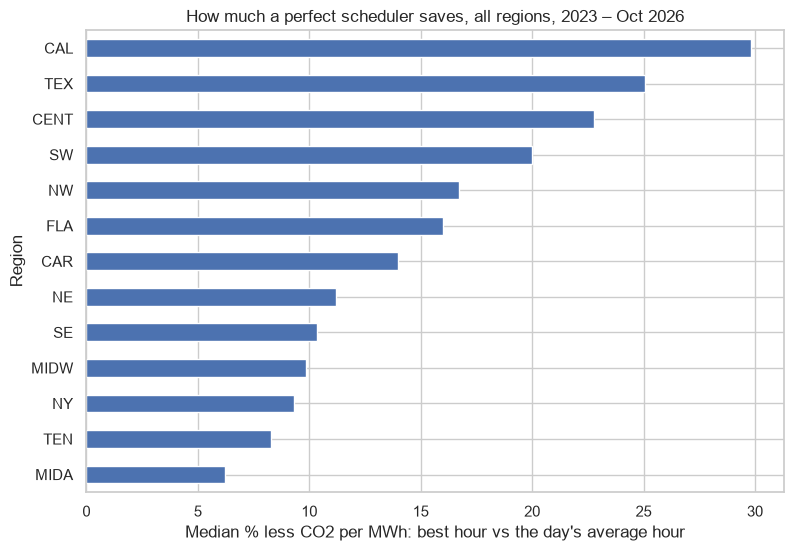

median best-hour saving (%) by region and year:


year,2023,2024,2025,2026
region,,,,
CAL,30.600000,27.700001,25.200001,44.900002
CAR,15.000000,13.500000,13.700000,13.400000
CENT,24.799999,22.200001,22.400000,22.000000
FLA,11.100000,14.400000,19.500000,20.700001
MIDA,5.400000,5.800000,6.800000,8.300000
MIDW,9.600000,9.200000,8.800000,12.300000
NE,10.900000,9.700000,12.500000,12.700000
NW,12.900000,16.100000,18.600000,21.700001
NY,9.400000,9.900000,8.500000,9.100000


In [52]:
# all together
prize_region["best hour vs day average (% cleaner)"].sort_values().plot(kind="barh", figsize=(9, 6), color="C0")
plt.xlabel("Median % less CO2 per MWh: best hour vs the day's average hour")
plt.ylabel("Region")
plt.title("How much a perfect scheduler saves, all regions, 2023 – Oct 2026")
plt.show()

print("median best-hour saving (%) by region and year:")
prize.groupby(["region", "year"])["best hour vs day average (% cleaner)"].median().unstack().reindex(REGIONS).round(1)

#### (d) Energy mix and flows between regions

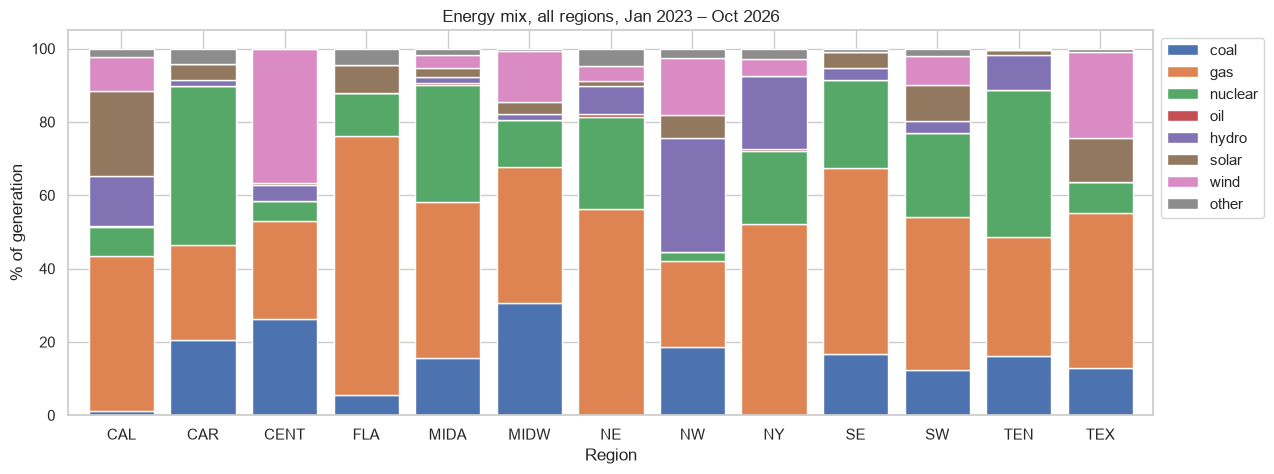

In [53]:
mix_f = F.groupby("region")[E.FUELS].sum().reindex(REGIONS)
mix_f = mix_f.div(mix_f.sum(axis=1), axis=0) * 100
mix_f.plot(kind="bar", stacked=True, figsize=(14, 5), rot=0, width=0.8)
plt.xlabel("Region")
plt.ylabel("% of generation")
plt.title("Energy mix, all regions, Jan 2023 – Oct 2026")
plt.legend(bbox_to_anchor=(1, 1))
plt.show()

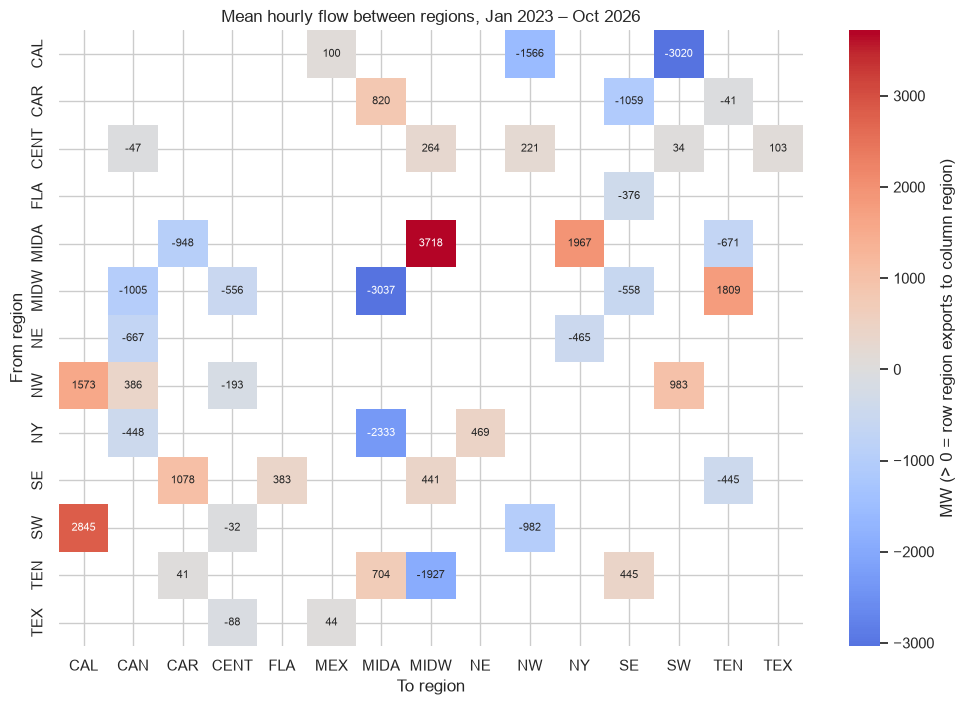

In [54]:
# mean flow between regions (row exports to column if > 0), focus period
ff = flows[flows.utc_end >= FOCUS_START]
matrix = ff.groupby(["region", "to_region"]).mw.mean().unstack()
fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(matrix, cmap="coolwarm", center=0, annot=True, fmt=".0f", annot_kws={"size": 8},
            cbar_kws={"label": "MW (> 0 = row region exports to column region)"}, ax=ax)
ax.set_xlabel("To region")
ax.set_ylabel("From region")
ax.set_title("Mean hourly flow between regions, Jan 2023 – Oct 2026")
plt.show()

### 6.1 Polished charts

/Users/claracheng/Downloads/209a Final Project/style.py:77: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.savefig(path, dpi=300)
/Users/claracheng/anaconda3/envs/cs1090a/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


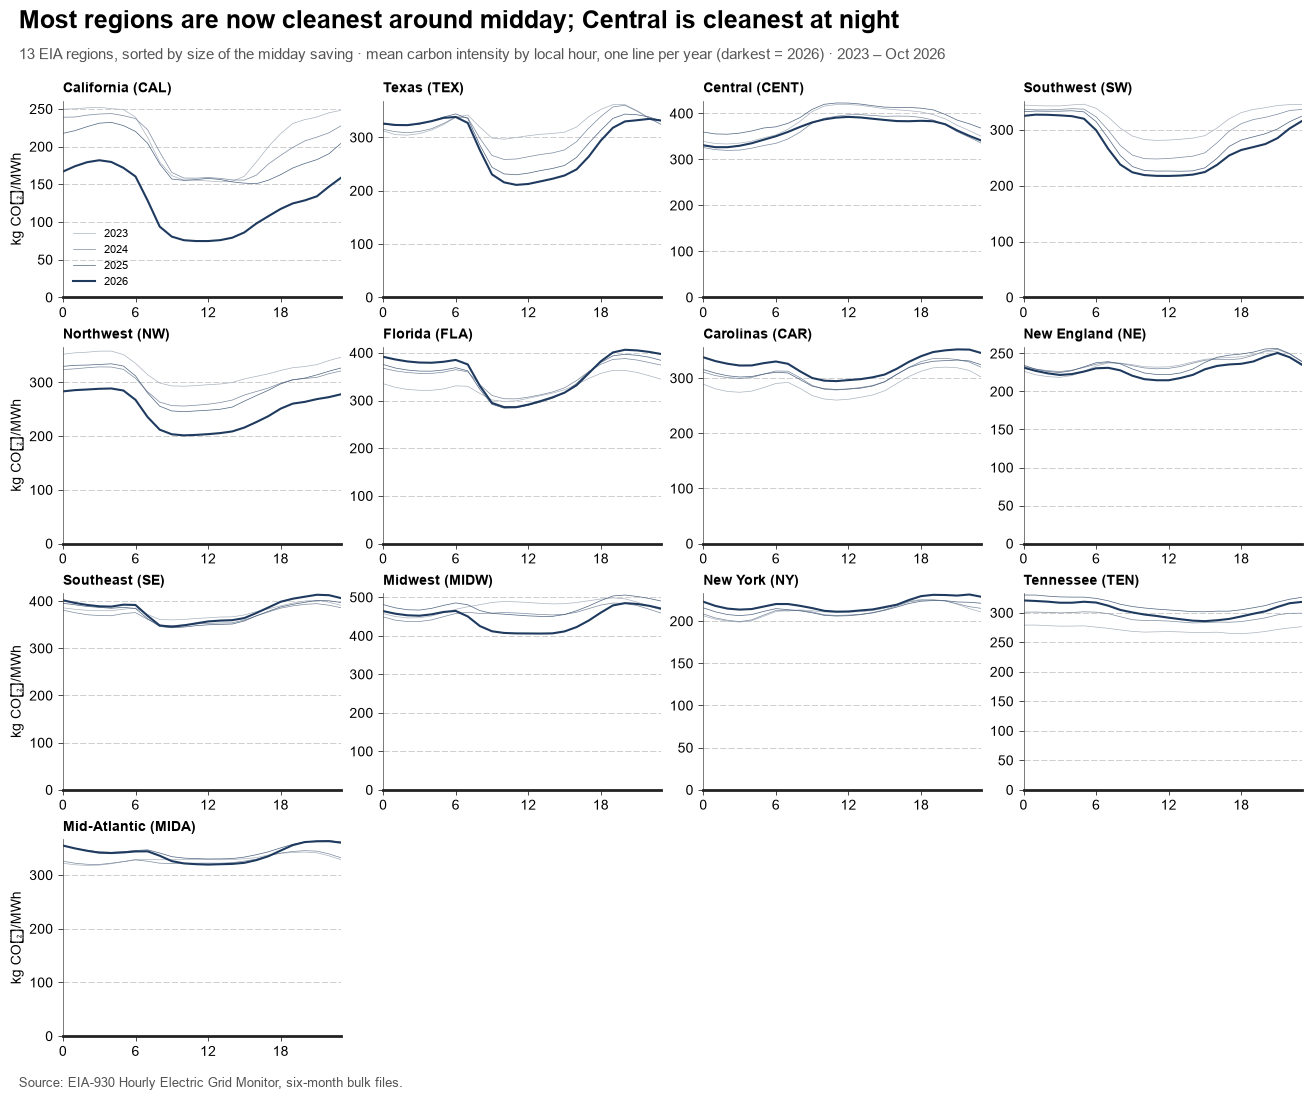

In [55]:
S.set_style()
order = prize_region["best hour vs day average (% cleaner)"].sort_values(ascending=False).index
fig, axes = plt.subplots(4, 4, figsize=(13, 11), sharex=True)
axes = axes.ravel()
years = sorted(F.year.unique())
for ax, r in zip(axes, order):
    g = F[F.region == r]
    for i, y in enumerate(years):
        p = g[g.year == y].groupby("hour").ci.mean()
        ax.plot(p.index, p.values, color=S.SEQ(0.35 + 0.65 * i / (len(years) - 1)),
                lw=S.LINE_PT["heavy"] if y == years[-1] else S.LINE_PT["light"], label=str(y))
    ax.set_title(f"{RN[r]} ({r})", fontsize=10)
    ax.set_xticks(range(0, 24, 6))
    ax.set_xlim(0, 23)
    ax.set_ylim(bottom=0)
    ax.xaxis.set_tick_params(labelbottom=True)
    S.chart_lines(ax)
for ax in axes[len(REGIONS):]:
    ax.axis("off")
axes[0].legend(fontsize=8, loc="lower left")
for ax in axes[::4]:
    ax.set_ylabel("kg CO₂/MWh")
S.frame(fig, "Most regions are now cleanest around midday; Central is cleanest at night",
        "13 EIA regions, sorted by size of the midday saving · mean carbon intensity by local hour, one line per year (darkest = 2026) · 2023 – Oct 2026")
S.save(fig, f"{FIG}/04_daily_profile_by_region.png")

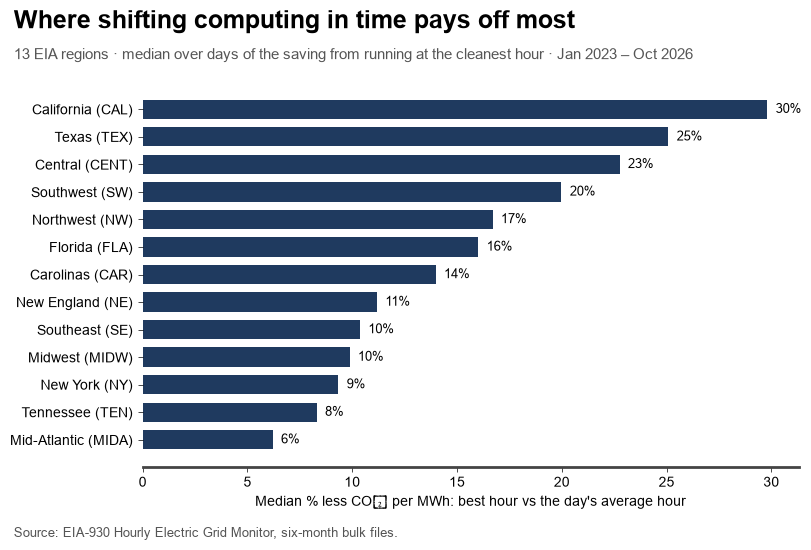

In [56]:
p = prize_region["best hour vs day average (% cleaner)"].sort_values()
fig, ax = plt.subplots(figsize=S.PANEL["L"])
ax.barh([f"{RN[r]} ({r})" for r in p.index], p.values, color=S.NAVY, height=0.7)
for i, v in enumerate(p.values):
    ax.text(v + 0.4, i, f"{v:.0f}%", va="center", fontsize=9)
ax.set_xlabel("Median % less CO₂ per MWh: best hour vs the day's average hour")
for sp in ("top", "right", "left"): ax.spines[sp].set_visible(False)
ax.spines["bottom"].set_linewidth(S.LINE_PT["profile"])
S.frame(fig, "Where shifting computing in time pays off most",
        "13 EIA regions · median over days of the saving from running at the cleanest hour · Jan 2023 – Oct 2026")
S.save(fig, f"{FIG}/05_scheduling_prize_by_region.png")

## 7. Summary of findings

**About the data**

- **Size and coverage:**
  - Raw: 2.28 GB of CSVs, 74 raw columns.
  - Grids: 69 balancing authorities in 13 regions, 4.3 million BA-hours.
  - Cleaned: one row per region × hour, **892,620 rows × 24 columns** (13 regions × 68,663 hours, Jan 2019 – Oct 2026). The focus period has 436,788 rows.
- **Quality is high after cleaning.** EIA's `(Adjusted)` columns replace the raw records that contain impossible values. Our cleaning removes one-hour spikes and out-of-range values per BA. Remaining problems are listed in Section 4, notably **California 2026 (verify)** and **Mid-Atlantic January 2020**.

**Full timeline (2019 – 2026)**

- **Regions differ by more than a factor of two.** Mean carbon intensity in 2025 ranges from 185 kg/MWh (California) and 214 (New York) to 474 (Midwest). Fossil fuels supply 42% to 77% of each region's power.
- **Most regions got cleaner, but not all.** Between 2019 and 2025:
  - Cleaner: Texas −24%, Northwest −22%, California −17%, Midwest −14%, Southeast −14%, Mid-Atlantic −10%.
  - Dirtier: New York +34%, New England +17%, Tennessee +8%.
- **Solar is the main change:** Texas grew from 1% to 14% of generation, the Southwest from 3% to 12%, and Florida from 1.5% to 9%.

**Focus period (2023 – Oct 2026)**

- **The cleanest hours are moving to midday.** In 12 of 13 regions, midday is cleaner than the day's average.
  - The share of days whose cleanest hour falls at 10:00–15:00 rose from 2023 to 2026: Texas 28% → 90%, Mid-Atlantic 17% → 71%, Midwest 6% → 61%.
  - **Central (SPP) is the exception:** it is cleanest at night on 78% of days, because of night-time wind.
- **The scheduling prize differs a lot by region.** Running at the day's best hour instead of an average hour cuts carbon intensity by a median of:
  - 6% in the Mid-Atlantic (PJM) and 8–10% in Tennessee, New York and the Midwest;
  - 20–30% in the Southwest, Central, Texas and California.
  - It is growing in most regions: Texas 20% → 30%, Northwest 13% → 22%, Florida 11% → 21% from 2023 to 2026.
- **Implications for modelling:**
  - Each region has its own daily shape, which is still changing year to year. A model should be fit per region (or use region as a feature), weight recent data, and be tested on the most recent months.
  - Because what matters is *which hours* are cleanest, evaluate the ranking of hours within a day, not just average error.

## 9. ERCOT fuel mix data for Texas

**Why a second source for Texas.** EIA-930 gives one row per region and hour. ERCOT, the grid operator for most of Texas, publishes its own *Fuel Mix Report* with more detail:

- **15-minute** values instead of hourly
- gas split into **combined-cycle plants** (`Gas-CC`, efficient) and **steam and combustion turbines** (`Gas`, less efficient "peakers")
- **battery charging** reported separately (`WSL`, Wholesale Storage Load)

It covers the team's focus period, **Jan 2023 – Oct 2026**. We use it to (1) check EIA's Texas numbers against the grid operator's own, and (2) keep the extra detail for Texas available as features for Milestone 3.

The code in this section is written step by step, with one small task per cell.

### 9.1 Where the data comes from and how we got it

| | |
|---|---|
| **Source** | ERCOT, *Fuel Mix Report*: https://www.ercot.com/gridinfo/generation (section "Fuel Mix") |
| **Files** | One Excel workbook per year: `IntGenbyFuel2023.xlsx` … `IntGenbyFuel2026.xlsx`. 2025 and 2026 are direct links on that page; 2023 and 2024 are inside the zip file *Fuel Mix Report: 2007 – 2024* on the same page |
| **Inside each file** | One sheet per month (`Jan` … `Dec`), plus summary sheets we don't use. Months that haven't happened yet are empty sheets |
| **Downloaded** | 2026-11-10 to 2026-11-12. The 2026 file is updated by ERCOT each month |
| **Where to put them** | `data/raw/ercot/` |


In [57]:
ERCOT_DIR = f"{RAW}/ercot"
os.makedirs(ERCOT_DIR, exist_ok=True)

ERCOT_URLS = {2025: "https://www.ercot.com/files/docs/2025/02/07/IntGenbyFuel2025.xlsx",
              2026: "https://www.ercot.com/files/docs/2026/02/09/IntGenbyFuel2026.xlsx"}
ERCOT_ZIP_URL = "https://www.ercot.com/files/docs/2021/03/10/FuelMixReport_PreviousYears.zip"   # 2007 - 2024
ZIP_YEARS = [2023, 2024]
ERCOT_YEARS = [2023, 2024, 2025, 2026]


def download_file(url, path):
    request = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(request) as response:
        data = response.read()
    with open(path, "wb") as f:
        f.write(data)

for year in ERCOT_URLS:
    path = f"{ERCOT_DIR}/IntGenbyFuel{year}.xlsx"
    if not os.path.exists(path):
        try:
            download_file(ERCOT_URLS[year], path)
            print("downloaded", os.path.basename(path))
        except Exception as e:
            print("not available:", os.path.basename(path), e)

missing = []
for year in ZIP_YEARS:
    if not os.path.exists(f"{ERCOT_DIR}/IntGenbyFuel{year}.xlsx"):
        missing.append(year)

if len(missing) > 0:
    zip_path = f"{ERCOT_DIR}/FuelMixReport_PreviousYears.zip"
    try:
        download_file(ERCOT_ZIP_URL, zip_path)
        z = zipfile.ZipFile(zip_path)
        for name in z.namelist():
            for year in missing:
                if f"intgenbyfuel{year}" in name.lower():
                    with open(f"{ERCOT_DIR}/IntGenbyFuel{year}.xlsx", "wb") as f:
                        f.write(z.read(name))
                    print("extracted", f"IntGenbyFuel{year}.xlsx")
        z.close()
        os.remove(zip_path)
    except Exception as e:
        print("not available:", missing, e)

ercot_files = []
ercot_mb = 0
for year in ERCOT_YEARS:
    path = f"{ERCOT_DIR}/IntGenbyFuel{year}.xlsx"
    if os.path.exists(path):
        size_mb = os.path.getsize(path) / 1e6
        ercot_files.append(path)
        ercot_mb = ercot_mb + size_mb
        print(f"{os.path.basename(path)}   {size_mb:.1f} MB")

print(f"\nTotal ERCOT raw data: {ercot_mb:.1f} MB")

downloaded IntGenbyFuel2025.xlsx
downloaded IntGenbyFuel2026.xlsx
extracted IntGenbyFuel2023.xlsx
extracted IntGenbyFuel2024.xlsx
IntGenbyFuel2023.xlsx   3.0 MB
IntGenbyFuel2024.xlsx   3.0 MB
IntGenbyFuel2025.xlsx   3.0 MB
IntGenbyFuel2026.xlsx   2.6 MB

Total ERCOT raw data: 11.6 MB


In [58]:
eia_mb = sizes.MB.sum()
print(f"EIA-930:  {eia_mb / 1e3:.2f} GB")
print(f"ERCOT:    {ercot_mb / 1e3:.3f} GB")
print(f"Total:    {(eia_mb + ercot_mb) / 1e3:.2f} GB")

EIA-930:  2.33 GB
ERCOT:    0.012 GB
Total:    2.34 GB


### 9.2 What one row and each column represent

We read every month sheet of every year, exactly as published, and stack them into one table called `ercot_wide`. Empty sheets (future months) are skipped.

In [59]:
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

sheets = []
for path in ercot_files:
    for m in MONTHS:
        sheet = pd.read_excel(path, sheet_name=m)
        if len(sheet) > 0:
            sheets.append(sheet)

ercot_wide = pd.concat(sheets, ignore_index=True)
print("shape:", ercot_wide.shape)
print("dates:", ercot_wide["Date"].min().date(), "to", ercot_wide["Date"].max().date())
ercot_wide.head(10)

shape: (14000, 104)
dates: 2023-01-01 to 2026-10-31


,Date,Fuel,Settlement Type,Total,0:15,0:30,0:45,1:00,1:15,1:30,1:45,2:00,2:15,2:30,2:45,3:00,3:15,3:30,3:45,4:00,...,20:15,20:30,20:45,21:00,21:15,21:30,21:45,22:00,22:15,22:30,22:45,23:00,23:15,23:30,23:45,0:00,01:15 (DST),01:30 (DST),01:45 (DST),02:00 (DST)
0,2023-01-01,Biomass,FINAL,399.445752,4.185436,4.182232,4.184353,4.183658,4.183344,4.188761,4.184123,4.190345,4.182942,4.185056,4.183046,4.185329,4.178574,4.182398,4.186294,4.178331,...,4.169971,4.181011,4.174404,4.173692,4.169634,4.176940,4.177780,4.186978,4.170929,4.181941,4.173710,4.179576,4.179776,4.178324,4.186321,4.171277,NaN,NaN,NaN,NaN
1,2023-01-01,Coal,FINAL,106976.004454,921.604654,893.081975,881.553732,863.928866,855.495937,854.039200,847.019798,845.303903,844.240662,853.454602,840.197869,840.693950,847.469860,842.701816,844.557121,848.531394,...,1073.426838,1070.570900,1089.121093,1101.901806,1107.654442,1117.226595,1107.711876,1093.174064,1082.282031,1072.398024,1042.469737,989.093888,949.257443,921.793106,913.633028,895.728246,NaN,NaN,NaN,NaN
2,2023-01-01,Gas,FINAL,19409.242580,164.266324,162.040533,158.855930,158.186564,156.437603,152.641497,147.887164,147.766951,146.900332,146.332224,145.678266,145.817144,144.996054,144.467804,144.040232,142.597204,...,170.982229,168.911256,172.758558,173.832672,179.569243,164.148112,162.541452,164.867129,131.124729,126.661120,124.653024,123.897170,123.566698,124.060560,123.649819,122.363679,NaN,NaN,NaN,NaN
3,2023-01-01,Gas-CC,FINAL,216098.972378,1401.927280,1338.986303,1295.088153,1280.607814,1274.936688,1278.458307,1264.541629,1263.943279,1259.391481,1261.508460,1249.646564,1262.231011,1274.681502,1269.915656,1272.933707,1272.220561,...,2440.111866,2371.072208,2335.127319,2294.491436,2185.023480,1961.343238,1771.749220,1658.413231,1607.507964,1480.204487,1336.997733,1300.384439,1293.413896,1281.380608,1293.622428,1263.459487,NaN,NaN,NaN,NaN
4,2023-01-01,Hydro,FINAL,259.665426,4.053273,5.952185,6.008958,5.877862,1.153690,1.076637,1.054632,1.030177,1.029020,1.029153,1.030808,1.032213,1.029944,1.028892,1.031231,1.023716,...,1.152640,1.166177,1.184327,1.181935,1.175176,1.145021,1.136890,1.161356,1.152321,1.158468,1.150125,1.152583,1.150820,1.135488,1.116912,1.093971,NaN,NaN,NaN,NaN
5,2023-01-01,Nuclear,FINAL,122562.160563,1277.477718,1277.697111,1277.609374,1277.783076,1277.503337,1277.673707,1277.523096,1277.383494,1277.289482,1277.382180,1277.539389,1277.575204,1277.514834,1277.310979,1277.405271,1277.342804,...,1276.060119,1276.340733,1276.161231,1276.045564,1275.832052,1276.185949,1276.184611,1276.518663,1276.051674,1276.168010,1275.977607,1276.242156,1276.106951,1276.163885,1276.362196,1275.899223,NaN,NaN,NaN,NaN
6,2023-01-01,Other,FINAL,1607.441246,1.431746,6.522572,6.853462,5.005813,10.886001,3.561088,8.148880,10.252429,4.135296,13.672321,4.436391,22.690393,8.915308,4.825490,3.435379,4.003396,...,4.653324,18.620233,9.844218,7.091480,0.793272,9.757645,15.922879,37.051638,25.924182,42.926439,4.976688,2.836645,5.549673,1.844537,29.728270,2.534023,NaN,NaN,NaN,NaN
7,2023-01-01,Solar,FINAL,46505.797750,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.001825,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.006755,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.001940,0.000000,NaN,NaN,NaN,NaN
8,2023-01-01,WSL,FINAL,-1834.513580,-29.810096,-2.712604,-6.145239,-10.130714,-11.229481,-22.673470,-17.742052,-6.327298,-18.369073,-11.416057,-17.026733,-6.030970,-11.325829,-12.696560,-21.734549,-19.981082,...,-18.854612,-6.219198,-7.699141,-12.590231,-35.584231,-15.001141,-8.499216,-2.115518,-36.214053,-4.098172,-21.774979,-21.488003,-20.130557,-20.792725,-13.919983,-22.782410,NaN,NaN,NaN,NaN
9,2023-01-01,Wind,FINAL,394469.324652,5389.258859,5398.169670,5439.582984,5458.294312,5426.170313,5422.854683,5351.777173,5299.884736,5298.674154,5256.777585,5238.346012,5178.137377,5174.025533,5149.731412,5123.246769,5103.639714,..

**Shape of the table: 14,000 rows × 104 columns.**

- **Rows:** one row per day per fuel. There are 1,400 days from Jan 1, 2023 to Oct 31, 2026, and 10 fuels each day, so 1,400 × 10 = 14,000 rows.
- **Columns:**
  - **4 label columns:** `Date`, `Fuel`, `Settlement Type`, and `Total` (the fuel's energy for the whole day, in MWh).
  - **96 interval columns:** one for each 15-minute interval in a day (24 hours × 4). Each column is named by the time the interval *ends*, from `0:15` to `0:00` (midnight at the end of the day), and holds the energy (MWh) produced in that interval.
  - **4 daylight-saving columns:** `01:15 (DST)` to `02:00 (DST)`. These are used only on the November day when clocks fall back and 1:00 – 2:00 a.m. happens twice. They are empty on every other day.

**One row = one day × one fuel type.** Each day has 10 rows, one per fuel.

| Column | Meaning |
|---|---|
| `Date` | The day (local Central time) |
| `Fuel` | Biomass, Coal, Gas, Gas-CC, Hydro, Nuclear, Other, Solar, WSL, Wind (see below) |
| `Settlement Type` | `FINAL` (checked by ERCOT, about two months after the day) or `INITIAL` (first count, may still be revised slightly) |
| `Total` | Energy from that fuel over the whole day, MWh |
| `0:15` … `0:00` | **96 columns**, one per 15-minute interval: energy in **MWh** produced in the interval **ending** at that time. The last column, `0:00`, is midnight at the **end** of the day |
| `01:15 (DST)` … `02:00 (DST)` | 4 extra columns used only on the day clocks fall back in November, for the repeated 1 – 2 a.m. hour. Empty on every other day |

| Fuel code | Meaning |
|---|---|
| `Gas-CC` | Natural gas, combined-cycle plants (efficient) |
| `Gas` | Natural gas, steam turbines and simple-cycle combustion turbines (less efficient) |
| `WSL` | Wholesale Storage Load: electricity used to **charge** batteries. Always ≤ 0 |
| `Other` | Mostly battery **discharge**, plus small sources |
| the rest | as named |

Data types: `Date` is read as a date, `Fuel` and `Settlement Type` as text, and every energy column as a number (`float64`). No types need to be forced.

In [60]:
print(ercot_wide.dtypes.value_counts())
print()
print(ercot_wide[["Date", "Fuel", "Settlement Type", "Total"]].dtypes)

float64           101
str                 2
datetime64[us]      1
Name: count, dtype: int64

Date               datetime64[us]
Fuel                          str
Settlement Type               str
Total                     float64
dtype: object


**Summary statistics.** There are 101 numerical columns: 96 fifteen-minute interval columns, 4 extra daylight-saving columns, and the daily `Total`. They all measure the same thing (energy in MWh over a period of time), so it is clearer to summarize them **by fuel**. The table gives, for each fuel, the mean, minimum and maximum over all 15-minute values, and the same for the daily `Total`.

In [80]:
interval_cols = []
for c in ercot_wide.columns:
    if ":" in str(c):
        interval_cols.append(c)
print(len(interval_cols), "interval columns (not including Total)")

stats = []
for fuel in sorted(ercot_wide["Fuel"].unique()):
    rows = ercot_wide[ercot_wide["Fuel"] == fuel]
    values = rows[interval_cols].stack()
    stats.append({"fuel": fuel,
                  "15-min mean (MWh)": values.mean(),
                  "15-min min (MWh)": values.min(),
                  "15-min max (MWh)": values.max(),
                  "daily Total mean (MWh)": rows["Total"].mean(),
                  "daily Total min (MWh)": rows["Total"].min(),
                  "daily Total max (MWh)": rows["Total"].max()})
pd.DataFrame(stats).set_index("fuel").round(1)

100 interval columns (not including Total)


,15-min mean (MWh),15-min min (MWh),15-min max (MWh),daily Total mean (MWh),daily Total min (MWh),daily Total max (MWh)
fuel,,,,,,
Biomass,11.0,0.0,31.2,1052.9,82.9,2835.9
Coal,1751.1,429.6,3255.3,168102.2,57795.5,292976.6
Gas,1137.4,59.5,4971.3,109184.0,6491.6,304447.7
Gas-CC,4677.9,739.0,8350.7,449069.0,127456.8,716281.1
Hydro,12.4,0.0,93.8,1190.7,134.1,5566.1
Nuclear,1155.5,596.7,1282.2,110929.3,58520.5,122809.3
Other,124.1,0.0,3241.4,11914.0,1128.1,43233.7
Solar,1644.0,0.0,8835.6,157815.1,9351.8,370585.1
WSL,-148.5,-2983.0,-0.5,-14251.8,-47383.9,-1538.0


### 9.3 Cleaning and preprocessing

Each step below says what we did and why. The goal is a table in the same shape and with the same conventions as Amy’s region table (one row per hour, utc_end as the time key, the same 8 fuels, the same emission factors), so the two sources can be compared hour by hour.

#### Step 1: basic quality checks

Before reshaping anything, we made sure every day has every fuel exactly once, and that ERCOT's own daily `Total` agrees with its 15-minute values.

In [62]:
print("rows per fuel (should all be equal, one per day):")
print(ercot_wide["Fuel"].value_counts().to_dict())

n_days = ercot_wide["Date"].nunique()
print("\ndays:", n_days)

n_dup = ercot_wide.duplicated(["Date", "Fuel"]).sum()
print("duplicate (day, fuel) rows:", n_dup)

interval_sum = ercot_wide[interval_cols].sum(axis=1)
biggest_gap = (ercot_wide["Total"] - interval_sum).abs().max()
print("largest |Total - sum of 15-min values|:", round(biggest_gap, 6), "MWh")

print("\nsettlement type (rows):")
print(ercot_wide["Settlement Type"].value_counts().to_dict())

rows per fuel (should all be equal, one per day):
{'Biomass': 1400, 'Coal': 1400, 'Gas': 1400, 'Gas-CC': 1400, 'Hydro': 1400, 'Nuclear': 1400, 'Other': 1400, 'Solar': 1400, 'WSL': 1400, 'Wind': 1400}

days: 1400
duplicate (day, fuel) rows: 0
largest |Total - sum of 15-min values|: 1e-06 MWh

settlement type (rows):
{'FINAL': 13390, 'INITIAL': 610}


**Result**

- **Every fuel has one row per day** (1,400 rows each, for 1,400 days), and **no day–fuel pair appears twice**.
- **ERCOT's daily `Total` matches the sum of the 15-minute values** on every row (largest difference 0.000001 MWh, which is rounding). So no 15-minute values are missing or misread.
- **Settlement type:** ERCOT counts each day's generation twice. The **`INITIAL`** count is made within days and may still be slightly incomplete; the **`FINAL`** count is made about two months later, after all meter readings are in and errors are fixed. Both are real measurements; `FINAL` has just been fully checked.
  - 13,390 rows (Jan 2023 – Aug 2026) are `FINAL`.
  - 610 rows (61 days: Sep – Oct 2026) are still `INITIAL`.

#### Step 2: missing data

We looked at missing data, distinguishing between a real gap or just a time that doesn't exist.

In [ ]:
missing_per_col = ercot_wide[interval_cols].isna().sum()
print("blank cells, all interval columns:", int(missing_per_col.sum()))

# the 4 DST columns are blank on every day except the fall-back day
dst_cols = []
for c in interval_cols:
    if "DST" in str(c):
        dst_cols.append(c)
print("blank cells in the 4 DST columns:", int(missing_per_col[dst_cols].sum()))

# the regular 96 columns
regular_cols = []
for c in interval_cols:
    if "DST" not in str(c):
        regular_cols.append(c)
has_blank = ercot_wide[regular_cols].isna().any(axis=1)
print("\ndays with a blank in the regular columns:", sorted(ercot_wide.loc[has_blank, "Date"].dt.date.unique()))
blank_cols = missing_per_col[regular_cols]
print("columns with blanks:", list(blank_cols[blank_cols > 0].index))
print("blank cells in the regular columns:", int(blank_cols.sum()))

blank cells, all interval columns: 56040
blank cells in the 4 DST columns: 55880

days with a blank in the regular columns: [datetime.date(2023, 3, 12), datetime.date(2024, 3, 10), datetime.date(2025, 3, 9), datetime.date(2026, 3, 8)]
columns with blanks: ['2:15', '2:30', '2:45', '3:00']
blank cells in the regular columns: 160


**Missing data.** The cell counts the blank cells in the interval columns, then splits them into two groups to see where they come from:

- **The 4 DST columns:** 55,880 blanks. These columns hold data only on the November fall-back day, so they are empty on every other day.
- **The 96 regular columns:** 160 blanks, all on the four spring-forward days in the columns `2:15` – `3:00`, the skipped hour 2:00 – 3:00 a.m. That is 4 days × 10 fuels × 4 intervals = 160.

Every blank is a time that doesn't exist, so **no real data is missing**. We drop these cells when reshaping, since no energy was produced at a time that never happened.

findfont: Failed to find font weight semibold for Arial, now using 700.
/var/folders/qh/vcbywc8161n7lb2z7bpvjyhh0000gn/T/ipykernel_14860/2321617805.py:11: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


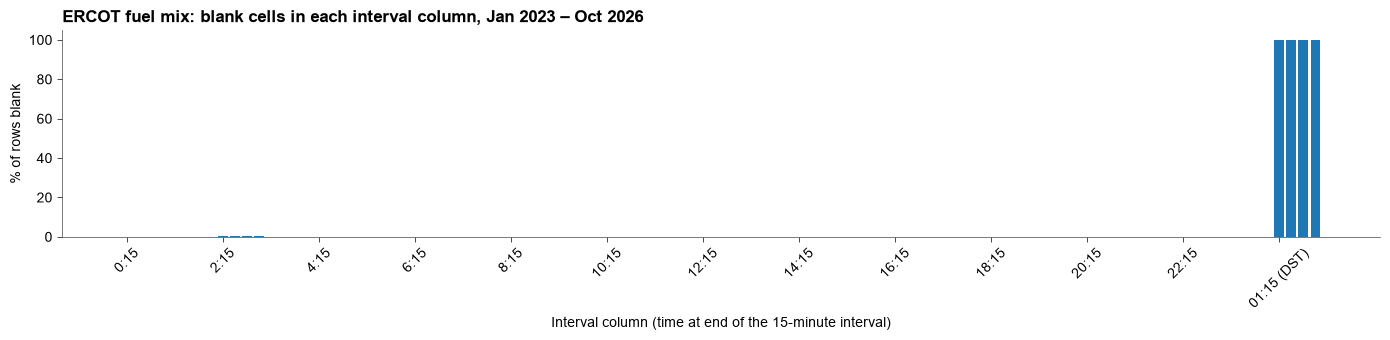

In [64]:
# plot: share of rows that are blank, for each interval column
pct_missing = ercot_wide[interval_cols].isna().mean() * 100

fig, ax = plt.subplots(figsize=(14, 3.5))
ax.bar(range(len(pct_missing)), pct_missing.values, color="C0")
ax.set_xticks(range(0, len(pct_missing), 8))
ax.set_xticklabels(list(pct_missing.index[::8]), rotation=45)
ax.set_xlabel("Interval column (time at end of the 15-minute interval)")
ax.set_ylabel("% of rows blank")
ax.set_title("ERCOT fuel mix: blank cells in each interval column, Jan 2023 – Oct 2026")
plt.tight_layout()
plt.show()

**Result and decision.** All the blank cells are times that **do not exist**, so nothing is really missing:

- The **4 DST columns** are blank on every day except the November fall-back days (the tall bars at the right of the plot).
- The **regular columns** are blank only on the March spring-forward days, in the 4 intervals of the skipped hour. That is 4 days out of 1,400, too few to see as bars in the plot around hour 2:00 – 3:00 a.m.

We decided to drop these blank cells when reshaping. Filling them in would invent energy for a time that never happened.

#### Step 3: unusual values

Look for impossible values (e.g. negative generation) and values far from the rest.

In [65]:
long_check = ercot_wide.melt(id_vars=["Fuel"], value_vars=interval_cols, value_name="mwh").dropna()

print("negative 15-minute values, by fuel:")
print(long_check[long_check["mwh"] < 0].groupby("Fuel").size().to_dict())

print("\nlargest 15-minute value of each fuel (MWh), and the same as average power (MW = MWh x 4):")
largest = long_check.groupby("Fuel")["mwh"].max()
print(pd.DataFrame({"max MWh per 15 min": largest.round(0), "as MW": (largest * 4).round(0)}))

negative 15-minute values, by fuel:
{'WSL': 134396}

largest 15-minute value of each fuel (MWh), and the same as average power (MW = MWh x 4):
         max MWh per 15 min    as MW
Fuel                                
Biomass                31.0    125.0
Coal                 3255.0  13021.0
Gas                  4971.0  19885.0
Gas-CC               8351.0  33403.0
Hydro                  94.0    375.0
Nuclear              1282.0   5129.0
Other                3241.0  12966.0
Solar                8836.0  35343.0
WSL                    -1.0     -2.0
Wind                 7233.0  28931.0


**Result and decision.**

- **Only `WSL` is ever negative.** That makes sense because WSL is bettery and it uses electricity. We keep it, but as its own column (`storage_charging`), **not** as generation.
- **No impossible sizes.** The largest values, as average power, are within what ERCOT's fleet can produce (for example solar about 35 GW and wind about 29 GW at their peaks). Unlike EIA's raw columns, there are no `2,147,483,647`-style broken records.
- **Low nuclear values are real.** Nuclear sometimes drops to about half its usual output; those are plant outages or refuelling, so we keep them.
- **Tiny values like solar = 0.00001 MWh at night** are measurement noise and are left as they are; they have no effect on hourly totals.

So no values are removed in this step.

#### Step 4: reshape to one row per 15-minute interval

In the raw table the time of day is hidden in column names. To give each value a real timestamp, we give each value its own row.

In [81]:
pieces = []
for col in interval_cols:
    piece = ercot_wide[["Date", "Fuel", "Settlement Type"]].copy()
    piece["interval"] = col
    piece["mwh"] = ercot_wide[col]
    pieces.append(piece)

ercot_long = pd.concat(pieces, ignore_index=True)
ercot_long = ercot_long.dropna(subset=["mwh"])
print(ercot_long.shape)
ercot_long.head()

(1343960, 5)


,Date,Fuel,Settlement Type,interval,mwh
0,2023-01-01,Biomass,FINAL,0:15,4.185436
1,2023-01-01,Coal,FINAL,0:15,921.604654
2,2023-01-01,Gas,FINAL,0:15,164.266324
3,2023-01-01,Gas-CC,FINAL,0:15,1401.927280
4,2023-01-01,Hydro,FINAL,0:15,4.053273


#### Step 5: real timestamps, in UTC

To maintain consistency and allow for easy comparison, we convert time to `utc_end` (end of the hour, UTC). Three details:

1. The column label is the **end** of a 15-minute interval, and `0:00` means midnight at the **end** of the day (24 hours after the date).
2. We work with the interval's **start** (label − 15 minutes). A start time never falls exactly on a clock change, which keeps the time-zone step simple.
3. On the November fall-back day, 1:00 – 2:00 a.m. happens twice. The regular columns are the first pass (daylight time); the `(DST)` columns are the repeated hour (standard time).

In [67]:
# hours and minutes from labels like "1:15" or "01:15 (DST)"
label = ercot_long["interval"].astype(str)
is_repeat = label.str.contains("DST")
clock = label.str.replace("(DST)", "", regex=False).str.strip()
parts = clock.str.split(":", expand=True).astype(int)
offset = pd.to_timedelta(parts[0], unit="h") + pd.to_timedelta(parts[1], unit="m")

# "0:00" is midnight at the END of the day
offset = offset.where(offset > pd.Timedelta(0), pd.Timedelta(hours=24))

# local start of each 15-minute interval
start_local = pd.to_datetime(ercot_long["Date"]) + offset - pd.Timedelta(minutes=15)

# attach the Central time zone. For the repeated fall-back hour, regular columns = daylight time (True),
# "(DST)" columns = standard time (False). The choice is ignored for every other, unambiguous time.
first_pass = (~is_repeat).to_numpy()
start_utc = start_local.dt.tz_localize("America/Chicago", ambiguous=first_pass).dt.tz_convert("UTC")

ercot_long["start_utc"] = start_utc.dt.tz_localize(None)
# Amy's key: END of the hour, UTC. Hour start = interval start rounded down to the hour.
ercot_long["utc_end"] = ercot_long["start_utc"].dt.floor("h") + pd.Timedelta(hours=1)

print("same fuel twice in one 15-minute slot:", ercot_long.duplicated(["start_utc", "Fuel"]).sum())
ercot_long[["Date", "Fuel", "interval", "start_utc", "utc_end", "mwh"]].head()

same fuel twice in one 15-minute slot: 0


,Date,Fuel,interval,start_utc,utc_end,mwh
0,2023-01-01,Biomass,0:15,2023-01-01 06:00:00,2023-01-01 07:00:00,4.185436
1,2023-01-01,Coal,0:15,2023-01-01 06:00:00,2023-01-01 07:00:00,921.604654
2,2023-01-01,Gas,0:15,2023-01-01 06:00:00,2023-01-01 07:00:00,164.266324
3,2023-01-01,Gas-CC,0:15,2023-01-01 06:00:00,2023-01-01 07:00:00,1401.927280
4,2023-01-01,Hydro,0:15,2023-01-01 06:00:00,2023-01-01 07:00:00,4.053273


#### Step 6: add the four 15-minute values into hours

**Why:** EIA and the project work in hours. Adding the four 15-minute energies gives the MWh produced in that hour, which equals the average power in MW over the hour (the same unit as Amy's table).

In [68]:
ercot_hourly = ercot_long.pivot_table(index="utc_end", columns="Fuel", values="mwh", aggfunc="sum")
counts = ercot_long.pivot_table(index="utc_end", columns="Fuel", values="mwh", aggfunc="count")

print("hours:", len(ercot_hourly))
print("15-min values per hour and fuel: min", int(counts.min().min()), " max", int(counts.max().max()), "(should both be 4)")

# every hour from the first to the last should be present exactly once
all_hours = pd.date_range(ercot_hourly.index.min(), ercot_hourly.index.max(), freq="h")
print("hours missing from the range:", len(all_hours.difference(ercot_hourly.index)))

# an hour is INITIAL if any of its values is still INITIAL
settle = ercot_long.groupby("utc_end")["Settlement Type"].agg(lambda s: "INITIAL" if (s == "INITIAL").any() else "FINAL")

hours: 33599
15-min values per hour and fuel: min 4  max 4 (should both be 4)
hours missing from the range: 0


#### Step 7: map ERCOT's fuels onto the team's 8 fuels

**Why:** the same column names must mean the same thing in both tables. We keep ERCOT's extra detail in three additional columns.

| Team fuel (Amy) | ERCOT fuel(s) |
|---|---|
| `coal` | Coal |
| `gas` | Gas + Gas-CC |
| `nuclear` | Nuclear |
| `oil` | none (ERCOT reports no oil; left blank, as in EIA's `TEX`) |
| `hydro` | Hydro |
| `solar` | Solar |
| `wind` | Wind |
| `other` | Other (mostly battery discharge) + Biomass |
| extra: `gas_cc`, `gas_ct` | Gas-CC, and Gas (steam + combustion turbines) separately |
| extra: `storage_charging` | WSL (≤ 0, **not** counted as generation) |

In [69]:
T = pd.DataFrame(index=ercot_hourly.index)
T["coal"] = ercot_hourly["Coal"]
T["gas"] = ercot_hourly["Gas"] + ercot_hourly["Gas-CC"]
T["nuclear"] = ercot_hourly["Nuclear"]
T["oil"] = float("nan")
T["hydro"] = ercot_hourly["Hydro"]
T["solar"] = ercot_hourly["Solar"]
T["wind"] = ercot_hourly["Wind"]
T["other"] = ercot_hourly["Other"] + ercot_hourly["Biomass"]

T["gas_cc"] = ercot_hourly["Gas-CC"]
T["gas_ct"] = ercot_hourly["Gas"]
T["storage_charging"] = ercot_hourly["WSL"]

# total generation = the 8 fuels (battery charging is load, not generation)
T["netgen"] = T[E.FUELS].sum(axis=1)
T["settlement"] = settle
T = T.reset_index()
T.head()

,utc_end,coal,gas,nuclear,oil,hydro,solar,wind,other,gas_cc,gas_ct,storage_charging,netgen,settlement
0,2023-01-01 07:00:00,3560.169227,5959.958901,5110.567279,NaN,21.892278,0.000000,21685.305825,36.549272,5316.609550,643.349351,-48.798653,36374.442782,FINAL
1,2023-01-01 08:00:00,3401.858838,5686.613118,5110.083634,NaN,4.315136,0.000000,21500.686905,49.594971,5081.879903,604.733215,-57.972301,35753.152602,FINAL
2,2023-01-01 09:00:00,3378.587083,5617.505482,5109.786255,NaN,4.121194,0.000000,20971.935128,61.670774,5032.777516,584.727966,-52.842833,35143.605916,FINAL
3,2023-01-01 10:00:00,3383.260191,5665.852720,5109.573888,NaN,4.113783,0.001825,20550.643428,37.905170,5089.751426,576.101294,-65.738020,34751.351005,FINAL
4,2023-01-01 11:00:00,3364.536435,5718.406713,5109.531344,NaN,3.986804,0.002008,20340.517976,53.001391,5149.165268,569.241445,-68.687951,34589.982671,FINAL


#### Step 8: local calendar columns, the same way as Amy

**Why:** the same features must mean the same thing for every region. Following `E.build_regions`, `hour` is the local hour *beginning* on Texas's clock (`America/Chicago`), and `date`, `year`, `month`, `dow` (0 = Monday) and `season` come from the local date.

In [70]:
hour_start_utc = T["utc_end"] - pd.Timedelta(hours=1)
local = hour_start_utc.dt.tz_localize("UTC").dt.tz_convert(E.REGION_TZ["TEX"]).dt.tz_localize(None)

T["region"] = "TEX"
T["date"] = local.dt.normalize()
T["hour"] = local.dt.hour
T["year"] = T["date"].dt.year
T["month"] = T["date"].dt.month
T["dow"] = T["date"].dt.dayofweek
T["season"] = T["month"].map(E.SEASON)

# keep the team's window: local days Jan 2023 – Oct 2026
T = T[(T["date"] >= FOCUS_START) & (T["date"] <= END)].copy()
print(T["date"].min().date(), "to", T["date"].max().date(), " hours:", len(T))

2023-01-01 to 2026-10-31  hours: 33599


#### Step 9: carbon intensity, with the team's emission factors

Using Amy's emission factors (`E.ef_table()`: EIA's CO₂ coefficient × that year's national heat rate) means Texas is measured exactly like every other region. Gas-CC and the less efficient gas plants get the same gas factor here, as in EIA's data; the split stays available for later.

carbon intensity (kg CO₂/MWh) = Σ (generation by fuel × emission factor) / Σ generation

In [71]:
ef = E.ef_table()
print(ef.round(0))

co2_kg = pd.Series(0.0, index=T.index)
for fuel in ef.columns:                                   # coal, gas, oil
    factor = T["year"].map(ef[fuel])                      # kg CO2 per MWh, for that row's year
    co2_kg = co2_kg + T[fuel].fillna(0).clip(lower=0) * factor

T["co2_t"] = co2_kg / 1000                                # tonnes of CO2 in that hour
T["ci"] = co2_kg / T["netgen"]                            # kg CO2 per MWh

T["ci"].describe().round(1)

        coal    gas    oil
year                      
2019  1013.0  409.0  831.0
2020  1023.0  409.0  835.0
2021  1016.0  407.0  832.0
2022  1026.0  410.0  828.0
2023  1031.0  409.0  850.0
2024  1034.0  410.0  830.0
2025  1034.0  410.0  830.0
2026  1034.0  410.0  830.0


count    33599.0
mean       303.3
std         79.4
min         72.4
25%        245.0
50%        305.4
75%        363.7
max        500.8
Name: ci, dtype: float64

#### Step 10: the cleaned ERCOT table, saved as CSV

In [72]:
ERCOT_COLS = ["region", "utc_end", "date", "hour", "year", "month", "dow", "season", "settlement",
              "netgen", *E.FUELS, "gas_cc", "gas_ct", "storage_charging", "co2_t", "ci"]
ercot = T[ERCOT_COLS].sort_values("utc_end").reset_index(drop=True)

print("cleaned ERCOT table:", ercot.shape[0], "rows x", ercot.shape[1], "columns")
ercot.to_csv(f"{OUT}/ercot_hourly_clean.csv", index=False)
print(f"saved {OUT}/ercot_hourly_clean.csv  {os.path.getsize(f'{OUT}/ercot_hourly_clean.csv') / 1e6:.1f} MB")
ercot.info()

cleaned ERCOT table: 33599 rows x 23 columns
saved data/ercot_hourly_clean.csv  8.1 MB
<class 'pandas.DataFrame'>
RangeIndex: 33599 entries, 0 to 33598
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   region            33599 non-null  str           
 1   utc_end           33599 non-null  datetime64[us]
 2   date              33599 non-null  datetime64[us]
 3   hour              33599 non-null  int32         
 4   year              33599 non-null  int32         
 5   month             33599 non-null  int32         
 6   dow               33599 non-null  int32         
 7   season            33599 non-null  str           
 8   settlement        33599 non-null  str           
 9   netgen            33599 non-null  float64       
 10  coal              33599 non-null  float64       
 11  gas               33599 non-null  float64       
 12  nuclear           33599 non-null  float64       
 13  

| Column | Units | Meaning |
|---|---|---|
| `region` | | Always `TEX`, so the table stacks with Amy's |
| `utc_end` | UTC | **End** of the hour. |
| `date`, `hour`, `year`, `month`, `dow`, `season` | local | Same definitions as Amy's table, on Central time |
| `settlement` | | `FINAL` or `INITIAL` (may still be revised by ERCOT) |
| `netgen` | MW | Total generation = sum of the 8 fuels |
| `coal` … `other` | MW | The team's 8 fuels (`oil` is always blank for Texas) |
| `gas_cc`, `gas_ct` | MW | Gas split into combined-cycle and less efficient plants |
| `storage_charging` | MW | Battery charging (≤ 0), not counted as generation |
| `co2_t` | t CO₂ | CO₂ from Texas's own generation that hour |
| `ci` | kg CO₂/MWh | **Carbon intensity**, the project's target |

### 9.4 Check: does ERCOT agree with EIA's Texas region?

**Why:** Amy's note in Section 8 suggests this as the first integration test. If the two sources agree hour by hour, EIA's `TEX` numbers can be trusted, and ERCOT's extra detail can be added to them. The cell joins the two tables on `utc_end`, then compares total generation and carbon intensity.

In [73]:
tex = R[(R.region == "TEX") & (R.date >= FOCUS_START)][["utc_end", "netgen", "solar", "wind", "gas", "coal", "ci"]]
both = tex.merge(ercot[["utc_end", "netgen", "solar", "wind", "gas", "coal", "ci"]],
                 on="utc_end", suffixes=("_eia", "_ercot"))
print("hours in both tables:", len(both), " of", len(ercot), "ERCOT hours")

rows = []
for col in ["netgen", "solar", "wind", "gas", "coal", "ci"]:
    a = both[col + "_eia"]
    b = both[col + "_ercot"]
    rows.append({"column": col,
                 "correlation": a.corr(b),
                 "mean EIA": a.mean(),
                 "mean ERCOT": b.mean(),
                 "mean difference (ERCOT - EIA)": (b - a).mean(),
                 "median |difference| as % of EIA mean": (b - a).abs().median() / a.mean() * 100})
pd.DataFrame(rows).set_index("column").round(2)

hours in both tables: 33599  of 33599 ERCOT hours


,correlation,mean EIA,mean ERCOT,mean difference (ERCOT - EIA),median |difference| as % of EIA mean
column,,,,,
netgen,1.0,54548.058594,55033.28,485.93,0.40
solar,1.0,6524.669922,6575.83,52.52,0.09
wind,1.0,12987.280273,12979.64,-4.67,0.14
gas,1.0,23276.880859,23261.23,-18.95,0.18
coal,1.0,7058.770020,7004.47,-54.52,0.75
ci,1.0,304.609985,303.34,-1.30,0.37


/var/folders/qh/vcbywc8161n7lb2z7bpvjyhh0000gn/T/ipykernel_14860/2324641448.py:23: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


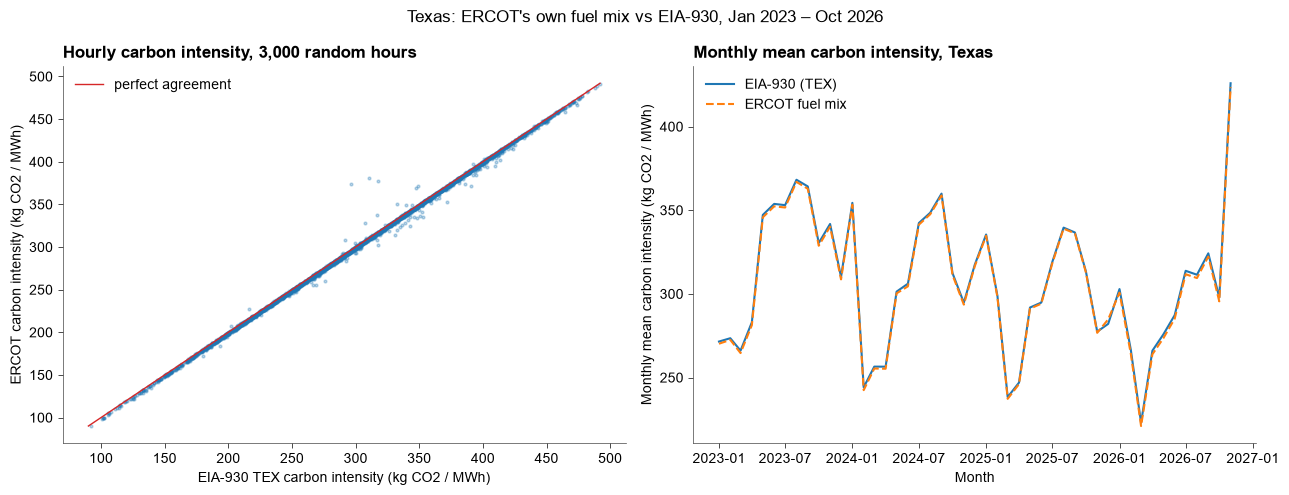

In [74]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sample = both.dropna(subset=["ci_eia", "ci_ercot"]).sample(3000, random_state=0)
axes[0].scatter(sample["ci_eia"], sample["ci_ercot"], s=4, alpha=0.3, color="C0")
low = min(sample["ci_eia"].min(), sample["ci_ercot"].min())
high = max(sample["ci_eia"].max(), sample["ci_ercot"].max())
axes[0].plot([low, high], [low, high], color="C3", lw=1, label="perfect agreement")
axes[0].set_xlabel("EIA-930 TEX carbon intensity (kg CO2 / MWh)")
axes[0].set_ylabel("ERCOT carbon intensity (kg CO2 / MWh)")
axes[0].set_title("Hourly carbon intensity, 3,000 random hours")
axes[0].legend()

monthly_eia = both.groupby(both.utc_end.dt.to_period("M"))["ci_eia"].mean()
monthly_ercot = both.groupby(both.utc_end.dt.to_period("M"))["ci_ercot"].mean()
axes[1].plot(monthly_eia.index.to_timestamp(), monthly_eia.values, label="EIA-930 (TEX)", color="C0")
axes[1].plot(monthly_ercot.index.to_timestamp(), monthly_ercot.values, label="ERCOT fuel mix", color="C1", linestyle="--")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Monthly mean carbon intensity (kg CO2 / MWh)")
axes[1].set_title("Monthly mean carbon intensity, Texas")
axes[1].legend()

plt.suptitle("Texas: ERCOT's own fuel mix vs EIA-930, Jan 2023 – Oct 2026")
plt.tight_layout()
plt.show()

**How to read the check.** A correlation close to 1 and points along the red line mean the two sources describe the same grid. Small, steady differences are expected for two reasons: ERCOT's report is the grid operator's settlement data while EIA publishes its own adjusted series, and ERCOT's `Other` (batteries) and EIA's `other` are defined slightly differently. A large gap in one fuel, or in one period, would show where one source has a reporting problem.

### 9.5 The response variable for Texas

The project's target is hourly carbon intensity. Its distribution in ERCOT's data, one panel per year:

/var/folders/qh/vcbywc8161n7lb2z7bpvjyhh0000gn/T/ipykernel_14860/316637333.py:11: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


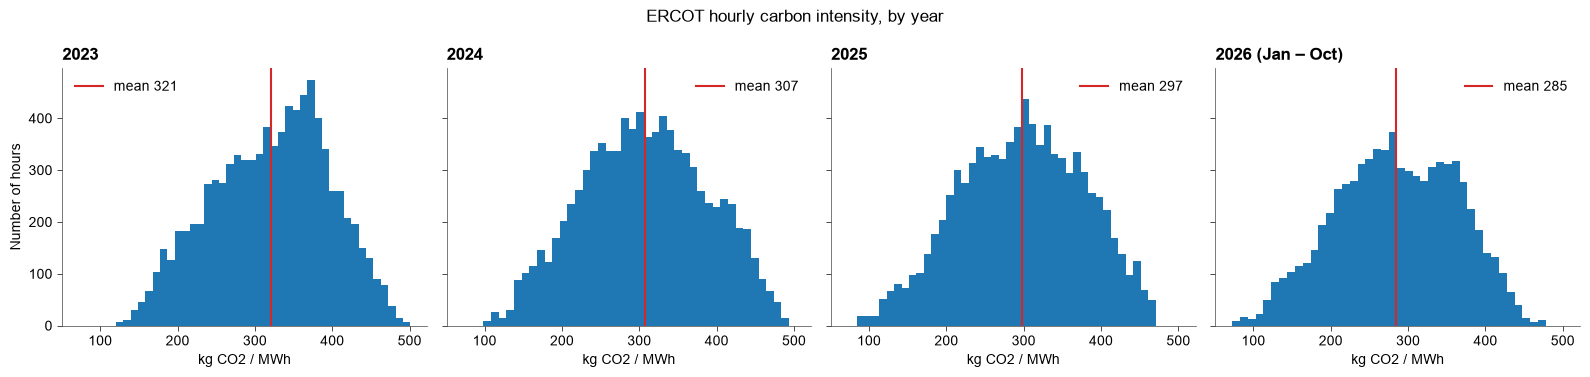

,count,mean,std,min,25%,50%,75%,max
year,,,,,,,,
2023,8760.0,321.0,75.0,120.0,265.0,328.0,377.0,501.0
2024,8784.0,307.0,80.0,98.0,248.0,307.0,366.0,494.0
2025,8760.0,297.0,80.0,84.0,239.0,300.0,358.0,471.0
2026,7295.0,285.0,78.0,72.0,229.0,285.0,346.0,478.0


In [75]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharex=True, sharey=True)
for i, y in enumerate(ERCOT_YEARS):
    values = ercot.loc[ercot["year"] == y, "ci"]
    axes[i].hist(values, bins=40, color="C0")
    axes[i].axvline(values.mean(), color="C3", lw=1.5, label=f"mean {values.mean():.0f}")
    axes[i].set_title(str(y) if y < 2026 else "2026 (Jan – Oct)")
    axes[i].set_xlabel("kg CO2 / MWh")
    axes[i].legend()
axes[0].set_ylabel("Number of hours")
plt.suptitle("ERCOT hourly carbon intensity, by year")
plt.tight_layout()
plt.show()

ercot.groupby("year")["ci"].describe().round(0)

**What we see.** Texas carbon intensity falls each year, and the spread within each year is wide. Much of that spread is the daily cycle: solar makes the middle of the day clean, gas fills the evening (Amy's Section 6). The wide spread is good for the project: the larger the gap between hours, the more there is to gain by choosing when to run a flexible job.

## 10. Issues checklist, both datasets

### 10.1 Missing data

| Dataset | How much is missing | Pattern | Decision |
|---|---|---|---|
| EIA-930 regions (Section 4) | Under 0.4% of hours in any measured column, in any region | Concentrated in a few places: PJM's fuel mix in Jan 2020 (8% of 2020 hours have no carbon intensity), and fuels a region never reports (e.g. no wind in the Carolinas), which are 100% "missing" but really zero | Gaps of ≤ 3 hours are filled by time interpolation; longer gaps are left blank. Carbon intensity is left blank when the fuels cover < 85% of net generation. The focus period (2023 onward) avoids most of the problem years |
| ERCOT (Section 9.3, Step 2) | No real missing values | All blanks are times that don't exist (the skipped spring-forward hour, and the DST columns on ordinary days) | Dropped, since no energy was produced at a time that didn't exist |

### 10.2 Unusual values

| Dataset | What we found | Error or real? | Decision |
|---|---|---|---|
| EIA-930 raw columns | 342 values above 1,000,000 MW, some equal to 2³¹ − 1 | Errors (broken records) | Not used: we only use EIA's `(Adjusted)` columns |
| EIA-930 adjusted columns | One-hour spikes and out-of-range values (e.g. PJM nuclear 46 GW, above its ~33 GW capacity) | Errors | Set to missing, then short gaps interpolated (`E.clean`) |
| EIA-930, California 2026 | Gas generation drops by about two-thirds for five months, then returns | Probably a reporting change | Kept for now and flagged; verify before relying on California 2026 |
| ERCOT | Battery charging (`WSL`) is negative; nuclear sometimes at half output | Real | Kept: charging as its own column, not generation; outages are real grid behaviour |

### 10.3 Class imbalance

Our main task is **regression** (predict each hour's carbon intensity), so class imbalance does not apply directly. It would apply if we frame part of the project as **classification**, for example "which hour of tomorrow will be the cleanest?". The classes (hours 0 – 23) are very unbalanced, as the count below shows for Texas. If we use that framing in Milestone 3, plain accuracy would be misleading (always guessing the most common hour scores well), so we would report per-class or ranking metrics instead.

In [76]:
# Texas, ERCOT data: on how many days is each hour the cleanest hour of the day? (complete days only)
cleanest_hour_count = {}
for h in range(24):
    cleanest_hour_count[h] = 0

for day, rows in ercot.groupby("date"):
    if len(rows) == 24:
        best_row = rows.loc[rows["ci"].idxmin()]
        cleanest_hour_count[best_row["hour"]] = cleanest_hour_count[best_row["hour"]] + 1

classes = pd.Series(cleanest_hour_count, name="days")
print("days:", classes.sum())
print("most common cleanest hour:", classes.idxmax(), f"({classes.max() / classes.sum() * 100:.0f}% of days)")
print("hours that are never the cleanest:", list(classes[classes == 0].index))
classes.to_frame().T

days: 1393
most common cleanest hour: 10 (20% of days)
hours that are never the cleanest: [6, 7, 19, 20]


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
days,60,42,47,30,11,7,0,0,9,189,280,176,124,106,115,82,29,12,2,0,0,1,7,64


### 10.4 Scale of the features

The numerical columns are on very different scales: hour of day runs 0 – 23, fuel shares 0 – 1, and demand and generation run from hundreds to over 150,000 MW depending on the region. Models such as regularized regression and k-nearest neighbours need these features **standardized** (subtract the mean, divide by the standard deviation, using the training data only). Tree-based models (random forests, gradient boosting) do not.

Range of each numerical column, Amy's region table, focus period:

In [77]:
num_cols = ["hour", "month", "dow", "n_ba", "demand", "demand_fcst", "netgen", "interchange", *E.FUELS, "co2_t", "ci"]
ranges = F[num_cols].agg(["min", "max", "mean", "std"]).T
ranges["range (max - min)"] = ranges["max"] - ranges["min"]
ranges.round(1)

,min,max,mean,std,range (max - min)
hour,0.0,23.0,11.5,6.9,23.0
month,1.0,12.0,6.3,3.4,11.0
dow,0.0,6.0,3.0,2.0,6.0
n_ba,1.0,21.0,4.7,5.4,20.0
demand,2309.0,162648.0,37321.5,25753.8,160339.0
demand_fcst,0.0,165557.0,36915.9,25891.2,165557.0
netgen,2485.0,164403.0,37026.9,26493.0,161918.0
interchange,-17109.0,13302.0,-199.7,2774.7,30411.0
coal,-8.0,43101.0,6342.5,7362.8,43109.0
gas,1076.0,75926.0,14987.5,11869.7,74850.0


Range of each numerical column, ERCOT table:

In [78]:
ercot_num = ["hour", "month", "dow", "netgen", "coal", "gas", "nuclear", "hydro", "solar", "wind", "other",
             "gas_cc", "gas_ct", "storage_charging", "co2_t", "ci"]
ercot_ranges = ercot[ercot_num].agg(["min", "max", "mean", "std"]).T
ercot_ranges["range (max - min)"] = ercot_ranges["max"] - ercot_ranges["min"]
ercot_ranges.round(1)

,min,max,mean,std,range (max - min)
hour,0.0,23.0,11.5,6.9,23.0
month,1.0,12.0,6.3,3.4,11.0
dow,0.0,6.0,3.0,2.0,6.0
netgen,33270.3,92320.7,55033.3,11684.7,59050.4
coal,1897.9,12885.8,7004.5,2168.9,10987.9
gas,3429.3,51178.5,23261.2,9303.7,47749.2
nuclear,2387.3,5122.9,4622.2,637.1,2735.6
hydro,0.0,345.2,49.6,62.8,345.2
solar,0.0,35140.3,6575.8,8821.8,35140.3
wind,33.1,28844.4,12979.6,6731.3,28811.4


### 10.5 Information leakage

The model predicts **tomorrow's** 24 hourly carbon intensities, using what is known when the prediction is made (the day before). Any value measured during the target hour is only known **after** the outcome, so it cannot be a feature for that hour.

| Column(s) | Can it be a feature for the target hour? | Why |
|---|---|---|
| `hour`, `month`, `dow`, `season`, `year`, `region` | Yes | Known in advance |
| `demand_fcst` | Yes | EIA's **day-ahead** demand forecast, published before the day starts |
| `demand`, `netgen`, `interchange`, the 8 fuels, `gas_cc`, `gas_ct`, `storage_charging` | **Only as lagged values** (e.g. the same hour yesterday, or yesterday's daily average) | Measured during the hour itself. Same-hour values give away the answer: carbon intensity is computed directly from the fuel mix |
| `co2_t`, `ci` | **Only as lagged values** | `ci` is the target; `co2_t` is its numerator |
| `mix_ratio`, `n_ba`, `settlement` | No (data-quality flags only) | They describe how the data was recorded, sometimes after the fact |

Two more points:

- **Time-based split.** Training, validation and test sets must be split **by time** (train on earlier months, test on later ones), never randomly. A random split puts tomorrow's hours in training, which leaks the future.
- **Revisions.** ERCOT's `INITIAL` values (Sep – Oct 2026) and EIA's adjusted series can be revised after the fact. In real use, a forecaster would only have the first-published values. This matters little for our analysis, but we note it.
